In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import re

# ============================================================
# SINGLE CELL - CLINICAL GROUPING + MEDIAN SURVIVAL + MUTATIONS
#
# PANCREAS OVERALL ANALYSIS
# Tutti i pazienti pancreatici vengono considerati insieme,
# senza separazione per istologia / ONCOTREE_CODE.
#
# Output principali in memoria:
# - df_with_groups
# - clinical
# - pancreas_median_summary
# - df
# - df_mutations
# - df_final
# - df_final_grouped
#
# Compatibilità:
# Le celle successive del notebook useranno:
#   ONCOTREE_CODE = PANCREAS_ALL
#
# L'istologia originale, se presente, viene conservata in:
#   ORIGINAL_ONCOTREE_CODE
#
# La nuova variabile clinica di stratificazione è:
#   survival_group
#
# Gruppi:
#   LOW_SURVIVAL
#   HIGH_SURVIVAL
# ============================================================


# ============================================================
# 0. Paths e parametri
# ============================================================

data_dir = Path("data_pancreas")

input_file = data_dir / "filtered_data_PANCREAS.csv"

# Prova prima a cercare data_mutations.txt dentro data_pancreas.
# Se non lo trova, usa il path classico data/data_mutations.txt.
# Se non trova neanche quello, usa direttamente filtered_data_PANCREAS.csv
# perché nel tuo dataset sono già presenti righe mutazionali.
mutation_file_candidates = [
    (data_dir / "data_mutations.txt", "\t"),
    (Path("data") / "data_mutations.txt", "\t"),
    (input_file, ",")
]

file_path_mutations = None
mutation_sep = None

for candidate, sep in mutation_file_candidates:
    if candidate.exists():
        file_path_mutations = candidate
        mutation_sep = sep
        break

if file_path_mutations is None:
    raise FileNotFoundError(
        "File mutazioni non trovato. Ho cercato in:\n"
        + "\n".join(str(p[0]) for p in mutation_file_candidates)
    )

SAVE_OUTPUTS = True

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

output_dir = data_dir / "clinical_to_network_median_pancreas_all"
output_dir.mkdir(parents=True, exist_ok=True)

# Possibili nomi della colonna survival nel dataset filtrato
survival_col_candidates = [
    "Overall Survival (Months)",
    "Overall Survival Months",
    "OS_MONTHS",
    "OS_MONTH",
    "OS months",
    "OS_months",
    "Survival Months",
    "Survival months"
]

# Possibili nomi della colonna status
survival_status_col_candidates = [
    "Overall Survival Status",
    "OS_STATUS",
    "OS Status",
    "Survival Status",
    "Survival status"
]


# ============================================================
# Helper
# ============================================================

def safe_filename(text):
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9_-]+", "_", text)
    return text.strip("_")


def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def collapse_duplicate_columns(df_in):
    """
    Rimuove/gestisce colonne duplicate.
    Se esistono duplicati con stesso nome, tiene la prima occorrenza.
    """
    return df_in.loc[:, ~df_in.columns.duplicated()].copy()


def find_required_column(columns, candidates, label):
    """
    Cerca automaticamente una colonna obbligatoria nel dataset.
    """
    for candidate in candidates:
        if candidate in columns:
            return candidate

    raise ValueError(
        f"Colonna {label} non trovata nel dataset. "
        f"Colonne disponibili: {list(columns)}"
    )


def find_optional_column(columns, candidates):
    """
    Cerca automaticamente una colonna opzionale nel dataset.
    """
    for candidate in candidates:
        if candidate in columns:
            return candidate

    return None


def assign_survival_group(value, median_value):
    """
    Stratifica i pazienti rispetto alla mediana di OS_MONTHS.

    LOW_SURVIVAL:
        OS_MONTHS < median_value

    HIGH_SURVIVAL:
        OS_MONTHS >= median_value
    """
    if pd.isna(value):
        return np.nan

    if value < median_value:
        return "LOW_SURVIVAL"

    return "HIGH_SURVIVAL"


def extract_patient_id_from_barcode(series):
    """
    Estrae Patient_ID da Tumor_Sample_Barcode in modo robusto.

    Gestisce casi tipo:
    - P-0000000-T01
    - TCGA-XX-XXXX-...
    - altri barcode con suffisso tumorale dopo -T
    """
    barcode = series.astype(str).str.strip()

    patient_id = barcode.str.extract(r"^(P-\d+)", expand=False)

    missing = patient_id.isna()
    patient_id.loc[missing] = barcode.loc[missing].str.extract(
        r"^(TCGA-[A-Z0-9]{2}-[A-Z0-9]{4})",
        expand=False
    )

    missing = patient_id.isna()
    patient_id.loc[missing] = barcode.loc[missing].str.replace(
        r"-T.*$",
        "",
        regex=True
    )

    return patient_id


# ============================================================
# 1. Load filtered clinical dataset
# ============================================================

df_raw = pd.read_csv(input_file, low_memory=False)
df_raw = collapse_duplicate_columns(df_raw)

survival_original_col = find_required_column(
    df_raw.columns,
    survival_col_candidates,
    "survival / OS_MONTHS"
)

survival_status_original_col = find_optional_column(
    df_raw.columns,
    survival_status_col_candidates
)

print(f"Colonna survival identificata: {survival_original_col}")

if survival_status_original_col is not None:
    print(f"Colonna survival status identificata: {survival_status_original_col}")
else:
    print("Colonna survival status non trovata: continuo senza OS_STATUS.")

print(f"File mutazioni usato: {file_path_mutations}")

rename_map = {
    "Patient_ID": "PATIENT_ID",
    "PATIENT ID": "PATIENT_ID",
    "PATIENT_ID": "PATIENT_ID",
    "Oncotree Code": "ORIGINAL_ONCOTREE_CODE",
    "ONCOTREE_CODE": "ORIGINAL_ONCOTREE_CODE",
    "Oncotree_Code": "ORIGINAL_ONCOTREE_CODE",
    survival_original_col: "OS_MONTHS"
}

if survival_status_original_col is not None:
    rename_map[survival_status_original_col] = "OS_STATUS"

df_raw = df_raw.rename(columns=rename_map)
df_raw = collapse_duplicate_columns(df_raw)


# ============================================================
# 2. Check colonne richieste
# ============================================================

required_cols = {
    "PATIENT_ID",
    "OS_MONTHS"
}

missing_cols = required_cols - set(df_raw.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti in filtered_data_PANCREAS.csv: {missing_cols}"
    )

# Se non esiste una colonna istologica, la creo comunque come informazione non disponibile
if "ORIGINAL_ONCOTREE_CODE" not in df_raw.columns:
    df_raw["ORIGINAL_ONCOTREE_CODE"] = "Unknown"

# Se non esiste OS_STATUS, la creo vuota per compatibilità
if "OS_STATUS" not in df_raw.columns:
    df_raw["OS_STATUS"] = np.nan


# ============================================================
# 3. Preprocessing survival
# ============================================================

df_raw["PATIENT_ID"] = df_raw["PATIENT_ID"].astype(str).str.strip()

df_raw["ORIGINAL_ONCOTREE_CODE"] = (
    df_raw["ORIGINAL_ONCOTREE_CODE"]
    .astype(str)
    .str.strip()
)

df_raw["OS_MONTHS"] = pd.to_numeric(df_raw["OS_MONTHS"], errors="coerce")

# Evento survival, utile per eventuali analisi KM/Cox successive
df_raw["event"] = (
    df_raw["OS_STATUS"]
    .astype(str)
    .str.contains("DECEASED", case=False, na=False)
    .astype(int)
)

# Tengo solo pazienti con Patient_ID e OS_MONTHS disponibili
df_raw = df_raw.dropna(
    subset=[
        "PATIENT_ID",
        "OS_MONTHS"
    ]
).copy()

# Calcolo della mediana a livello paziente, non a livello riga mutazionale
patient_level_survival = (
    df_raw[
        [
            "PATIENT_ID",
            "OS_MONTHS"
        ]
    ]
    .drop_duplicates(["PATIENT_ID"])
    .copy()
)

survival_median = patient_level_survival["OS_MONTHS"].median()

print("\nMedian OS_MONTHS - pancreas overall:")
print(round(survival_median, 4))

# Variabile clinica principale per le analisi successive
df_raw["survival_group"] = df_raw["OS_MONTHS"].apply(
    lambda x: assign_survival_group(x, survival_median)
)

# Alias utile se in qualche cella successiva vuoi riferirti esplicitamente alla mediana
df_raw["median_group"] = df_raw["survival_group"]

df_raw["survival_threshold_median_pancreas_all"] = survival_median

# Gruppo unico pancreas
df_raw["ONCOTREE_CODE"] = PANCREAS_GROUP
df_raw["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 4. Patient-level clinical table - pancreas overall
# ============================================================

clinical = (
    df_raw[
        [
            "PATIENT_ID",
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "ORIGINAL_ONCOTREE_CODE",
            "OS_MONTHS",
            "OS_STATUS",
            "event",
            "survival_threshold_median_pancreas_all",
            "survival_group",
            "median_group"
        ]
    ]
    .drop_duplicates(["PATIENT_ID"])
    .copy()
)

print("\nPatient-level clinical table - pancreas overall:")
print("Patients:", clinical["PATIENT_ID"].nunique())
print("Rows:", clinical.shape[0])

print("\nMedian survival-group distribution - pancreas overall:")
safe_display(
    clinical
    .groupby(
        [
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "survival_group"
        ]
    )
    .agg(
        n_patients=("PATIENT_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


# ============================================================
# 5. Median survival summary - pancreas overall
# ============================================================

pancreas_median_summary = (
    clinical
    .groupby(
        [
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "survival_group"
        ]
    )
    .agg(
        n_patients=("PATIENT_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        mean_OS_MONTHS=("OS_MONTHS", "mean"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum")
    )
    .reset_index()
)

total_patients = clinical["PATIENT_ID"].nunique()

pancreas_median_summary["total_patients"] = total_patients

pancreas_median_summary["percentage"] = (
        pancreas_median_summary["n_patients"]
        / pancreas_median_summary["total_patients"]
        * 100
).round(2)

pancreas_median_summary["survival_threshold_median_pancreas_all"] = survival_median

pancreas_median_summary = pancreas_median_summary.sort_values(
    ["ONCOTREE_CODE", "survival_group"]
).reset_index(drop=True)

print("\nMedian survival summary - pancreas overall:")
safe_display(pancreas_median_summary)


# ============================================================
# 6. Merge survival group back into original filtered dataset
# ============================================================

df_with_groups = df_raw.copy()

print("\nSurvival group distribution in filtered pancreas dataset:")
safe_display(
    df_with_groups
    .drop_duplicates(["PATIENT_ID"])
    .groupby(
        [
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "survival_group"
        ]
    )
    .agg(
        n_patients=("PATIENT_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


# ============================================================
# 7. Prepare df for downstream notebook compatibility
# ============================================================
# Da questo punto in poi:
# - df["ONCOTREE_CODE"] contiene sempre PANCREAS_ALL
# - df["ORIGINAL_ONCOTREE_CODE"] conserva l'eventuale istologia originale
# - df["survival_group"] contiene LOW_SURVIVAL oppure HIGH_SURVIVAL
# - df["median_group"] è un alias di survival_group

df = df_with_groups.copy()
df = collapse_duplicate_columns(df)

df = df.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",
    "Hugo_Symbol": "Hugo_Symbol"
})

df = collapse_duplicate_columns(df)

required_df_cols = {
    "Patient_ID",
    "ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "OS_MONTHS",
    "OS_STATUS",
    "event",
    "survival_threshold_median_pancreas_all",
    "survival_group",
    "median_group"
}

missing_df_cols = required_df_cols - set(df.columns)

if missing_df_cols:
    raise ValueError(
        f"Colonne mancanti dopo la creazione del gruppo pancreas overall: {missing_df_cols}"
    )

df["Patient_ID"] = df["Patient_ID"].astype(str).str.strip()
df["ONCOTREE_CODE"] = PANCREAS_GROUP
df["Included_Oncotree_Codes"] = PANCREAS_LABEL

unique_patients = df["Patient_ID"].dropna().unique()

print("\nPatients in pancreas overall clinical dataframe:", len(unique_patients))

print("\nPancreas overall group used as ONCOTREE_CODE:")
safe_display(
    df[
        [
            "Patient_ID",
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "ORIGINAL_ONCOTREE_CODE",
            "OS_MONTHS",
            "OS_STATUS",
            "event",
            "survival_threshold_median_pancreas_all",
            "survival_group",
            "median_group"
        ]
    ]
    .drop_duplicates()
    .groupby(
        [
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "survival_group"
        ]
    )
    .agg(
        n_patients=("Patient_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


# ============================================================
# 8. Load mutations
# ============================================================

df_mutations = pd.read_csv(
    file_path_mutations,
    sep=mutation_sep,
    low_memory=False
)

df_mutations = collapse_duplicate_columns(df_mutations)

if "Patient_ID" in df_mutations.columns:
    df_mutations["Patient_ID"] = df_mutations["Patient_ID"].astype(str).str.strip()

elif "PATIENT_ID" in df_mutations.columns:
    df_mutations = df_mutations.rename(columns={"PATIENT_ID": "Patient_ID"})
    df_mutations["Patient_ID"] = df_mutations["Patient_ID"].astype(str).str.strip()

elif "Tumor_Sample_Barcode" in df_mutations.columns:
    df_mutations["Patient_ID"] = extract_patient_id_from_barcode(
        df_mutations["Tumor_Sample_Barcode"]
    )

else:
    raise ValueError(
        "Nel file mutazioni manca sia Patient_ID sia Tumor_Sample_Barcode."
    )

df_final = df_mutations[
    df_mutations["Patient_ID"].isin(unique_patients)
].copy()

print("\nMutation rows after patient filtering:", df_final.shape[0])
print("Mutation patients:", df_final["Patient_ID"].nunique())


# ============================================================
# 9. Mutation dataframe annotated by pancreas overall + median survival
# ============================================================

patient_group_map_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "OS_MONTHS",
    "OS_STATUS",
    "event",
    "survival_threshold_median_pancreas_all",
    "survival_group",
    "median_group"
]

patient_group_map = (
    df[patient_group_map_cols]
    .drop_duplicates(["Patient_ID"])
    .copy()
)

df_final_grouped = df_final.merge(
    patient_group_map,
    on="Patient_ID",
    how="inner"
)

print("\nGrouped mutation dataframe created in memory - pancreas overall:")
print("Rows:", df_final_grouped.shape[0])
print("Patients:", df_final_grouped["Patient_ID"].nunique())

print("\nMutation patients by pancreas overall survival_group:")
safe_display(
    df_final_grouped
    .drop_duplicates(["Patient_ID"])
    .groupby(
        [
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "survival_group"
        ]
    )
    .agg(
        n_patients=("Patient_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


# ============================================================
# 10. Optional saving
# ============================================================

if SAVE_OUTPUTS:
    pancreas_median_summary.to_csv(
        output_dir / "median_survival_distribution_pancreas_all.csv",
        index=False
    )

    df_with_groups.to_csv(
        output_dir / "filtered_data_PANCREAS_with_median_survival_groups_PANCREAS_ALL.csv",
        index=False
    )

    clinical.to_csv(
        output_dir / "clinical_median_survival_groups_pancreas_all.csv",
        index=False
    )

    df_final_grouped.to_csv(
        output_dir / "mutations_with_median_survival_groups_PANCREAS_ALL.csv",
        index=False
    )

    print("\nCSV intermedi salvati in:")
    print(output_dir)


# ============================================================
# 11. Compatibility aliases
# ============================================================

oncotree_median_summary = pancreas_median_summary
group_median_summary = pancreas_median_summary

oncotree_survival_summary = pancreas_median_summary
group_survival_summary = pancreas_median_summary

print("\nNota finale:")
print(
    "Da questo punto in poi il notebook userà ONCOTREE_CODE = PANCREAS_ALL, "
    "quindi tutti i pazienti pancreatici sono analizzati insieme."
)
print(
    "Il codice istologico originale, se presente, è conservato in ORIGINAL_ONCOTREE_CODE "
    "ma non viene usato per separare i pazienti."
)
print(
    "La feature clinica usata per la stratificazione è survival_group, "
    "derivata dalla mediana di Overall Survival (Months)."
)
print(
    f"Soglia mediana OS_MONTHS usata per PANCREAS_ALL: {survival_median:.4f} mesi."
)

Colonna survival identificata: Overall Survival (Months)
Colonna survival status identificata: Overall Survival Status
File mutazioni usato: data\data_mutations.txt

Median OS_MONTHS - pancreas overall:
9.2383

Patient-level clinical table - pancreas overall:
Patients: 886
Rows: 886

Median survival-group distribution - pancreas overall:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,9.238346,87.813602,319,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,0.032877,9.205469,393,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Median survival summary - pancreas overall:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,mean_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events,total_patients,percentage,survival_threshold_median_pancreas_all
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,22.804936,9.238346,87.813602,319,886,50.11,9.238346
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,4.368507,0.032877,9.205469,393,886,49.89,9.238346



Survival group distribution in filtered pancreas dataset:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,9.238346,87.813602,319,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,0.032877,9.205469,393,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Patients in pancreas overall clinical dataframe: 886

Pancreas overall group used as ONCOTREE_CODE:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,9.238346,87.813602,319,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,0.032877,9.205469,393,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Mutation rows after patient filtering: 4204
Mutation patients: 886

Grouped mutation dataframe created in memory - pancreas overall:
Rows: 4204
Patients: 886

Mutation patients by pancreas overall survival_group:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,9.238346,87.813602,319,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,0.032877,9.205469,393,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



CSV intermedi salvati in:
data_pancreas\clinical_to_network_median_pancreas_all

Nota finale:
Da questo punto in poi il notebook userà ONCOTREE_CODE = PANCREAS_ALL, quindi tutti i pazienti pancreatici sono analizzati insieme.
Il codice istologico originale, se presente, è conservato in ORIGINAL_ONCOTREE_CODE ma non viene usato per separare i pazienti.
La feature clinica usata per la stratificazione è survival_group, derivata dalla mediana di Overall Survival (Months).
Soglia mediana OS_MONTHS usata per PANCREAS_ALL: 9.2383 mesi.


***
## CO-OCCURRENCE ANALYSIS - LUNG CANCER

## Filter unique patients

In [2]:
# show me how many unique patients have mutations in these genes
unique_patients = df['Patient_ID'].unique()
unique_patients

array(['P-0089443', 'P-0088810', 'P-0088735', 'P-0088679', 'P-0088577',
       'P-0088583', 'P-0088053', 'P-0088293', 'P-0088382', 'P-0087475',
       'P-0085539', 'P-0087935', 'P-0085182', 'P-0086144', 'P-0086357',
       'P-0086888', 'P-0086142', 'P-0085308', 'P-0086548', 'P-0086688',
       'P-0086627', 'P-0086550', 'P-0085651', 'P-0066677', 'P-0083108',
       'P-0085645', 'P-0084904', 'P-0085728', 'P-0085614', 'P-0085336',
       'P-0085236', 'P-0085294', 'P-0084721', 'P-0012792', 'P-0082689',
       'P-0083790', 'P-0083693', 'P-0083746', 'P-0082278', 'P-0083507',
       'P-0083290', 'P-0083218', 'P-0083163', 'P-0081378', 'P-0082860',
       'P-0082971', 'P-0082974', 'P-0082999', 'P-0083026', 'P-0083087',
       'P-0083067', 'P-0082870', 'P-0062729', 'P-0065035', 'P-0056105',
       'P-0038819', 'P-0039794', 'P-0045466', 'P-0029597', 'P-0029823',
       'P-0030773', 'P-0031153', 'P-0031431', 'P-0033383', 'P-0026123',
       'P-0028118', 'P-0029023', 'P-0022156', 'P-0023197', 'P-00

In [3]:
df_mutations["Patient_ID"] = (
    df_mutations["Tumor_Sample_Barcode"]
    .astype(str)
    .str.extract(r"^(P-\d+)", expand=False)
    .str.strip()
 )

In [4]:
# given df_mutations, filter by unique_patients
df_final = df_mutations[df_mutations['Patient_ID'].isin(unique_patients)]
print(df_final[['Hugo_Symbol', 'Patient_ID']])

       Hugo_Symbol Patient_ID
340          CSF1R  P-0089443
341           TP53  P-0089443
342          U2AF1  P-0089443
343          PREX2  P-0089443
344           KRAS  P-0089443
...            ...        ...
206661        MEN1  P-0010490
206701        KRAS  P-0010691
206702        TP53  P-0010691
206703       PTPRT  P-0010691
206704      BCL2L1  P-0010691

[4204 rows x 2 columns]


In [5]:
df_final['Patient_ID'].value_counts()

Patient_ID
P-0043903    121
P-0070191     37
P-0032979     26
P-0033131     22
P-0043580     20
            ... 
P-0019789      1
P-0051469      1
P-0009225      1
P-0036211      1
P-0058589      1
Name: count, Length: 886, dtype: int64

# Structural Variant

In [6]:
file_path_structural = Path("data") / "data_sv.txt"

df_structural = pd.read_csv(file_path_structural, sep='\t')
df_structural.head()

,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Connection_Type,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments
0,P-0022424-T01-IM6,SOMATIC,SEPTIN12,ARID1A,16,1,4838352.0,27089562.0,5-UTR of SEPT12(-):11Kb before coding start,Exon 8 of ARID1A(+),...,3to3,ARID1A (NM_006015) - SEPT12 (NM_144605) rearra...,yes,unknown,0.0,0.0,0.0,0.0,10.0,Note: The ARID1A - SEPT12 rearrangement is a t...
1,P-0015002-T01-IM6,SOMATIC,A2BP1,ZFHX3,16,16,6119693.0,72831356.0,5-UTR of A2BP1(+): 982Kb before coding start,Exon 9 of ZFHX3(-),...,5to5,ZFHX3 (NM_006885) rearrangement : c.5225:ZFHX3...,yes,unknown,66711663.0,322021.0,328704.0,0.0,22.0,Note: The ZFHX3 (NM_006885) rearrangement resu...
2,P-0067067-T01-IM7,SOMATIC,ABCA3,CREBBP,16,16,2345775.0,3832990.0,Intron of ABCA3(-):34bp before exon 18,Intron of CREBBP(-):63bp before exon 6,...,5to3,ABCA3 (NM_001089) - CREBBP (NM_004380) rearran...,yes,unknown,1487215.0,110825.0,189734.0,0.0,26.0,Note: The ABCA3 - CREBBP rearrangement is a du...
3,P-0056185-T01-IM6,SOMATIC,ABCC4,VEGFA,13,6,95869663.0,43752221.0,Intron of ABCC4(-):7Kb before exon 5,Intron of VEGFA(+):56bp before exon 8,...,5to5,ABCC4 (NM_005845) - VEGFA (NM_001171623) rearr...,yes,unknown,0.0,0.0,0.0,0.0,66.0,Note: The ABCC4 - VEGFA rearrangement is a tra...
4,P-0014522-T01-IM6,SOMATIC,ABCC4,TMPRSS2,21,13,42873289.0,95689572.0,Intron of TMPRSS2(-): 3Kb before exon 2,Intron of ABCC4(-): 3Kb before exon 30,...,3to5,ABCC4 (NM_005845) - TMPRSS2 (NM_001135099) Re...,yes,unknown,0.0,0.0,0.0,0.0,4.0,Note: The ABCC4 - TMPRSS2 Rearrangement is a...


In [7]:
df_structural["Patient_ID"] = (
    df_structural["Sample_Id"]
    .astype(str)
    .str.extract(r"^(P-\d+)", expand=False)
    .str.strip()
 )

In [8]:
df_structural

,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments,Patient_ID
0,P-0022424-T01-IM6,SOMATIC,SEPTIN12,ARID1A,16,1,4838352.0,27089562.0,5-UTR of SEPT12(-):11Kb before coding start,Exon 8 of ARID1A(+),...,ARID1A (NM_006015) - SEPT12 (NM_144605) rearra...,yes,unknown,0.0,0.0,0.0,0.0,10.0,Note: The ARID1A - SEPT12 rearrangement is a t...,P-0022424
1,P-0015002-T01-IM6,SOMATIC,A2BP1,ZFHX3,16,16,6119693.0,72831356.0,5-UTR of A2BP1(+): 982Kb before coding start,Exon 9 of ZFHX3(-),...,ZFHX3 (NM_006885) rearrangement : c.5225:ZFHX3...,yes,unknown,66711663.0,322021.0,328704.0,0.0,22.0,Note: The ZFHX3 (NM_006885) rearrangement resu...,P-0015002
2,P-0067067-T01-IM7,SOMATIC,ABCA3,CREBBP,16,16,2345775.0,3832990.0,Intron of ABCA3(-):34bp before exon 18,Intron of CREBBP(-):63bp before exon 6,...,ABCA3 (NM_001089) - CREBBP (NM_004380) rearran...,yes,unknown,1487215.0,110825.0,189734.0,0.0,26.0,Note: The ABCA3 - CREBBP rearrangement is a du...,P-0067067
3,P-0056185-T01-IM6,SOMATIC,ABCC4,VEGFA,13,6,95869663.0,43752221.0,Intron of ABCC4(-):7Kb before exon 5,Intron of VEGFA(+):56bp before exon 8,...,ABCC4 (NM_005845) - VEGFA (NM_001171623) rearr...,yes,unknown,0.0,0.0,0.0,0.0,66.0,Note: The ABCC4 - VEGFA rearrangement is a tra...,P-0056185
4,P-0014522-T01-IM6,SOMATIC,ABCC4,TMPRSS2,21,13,42873289.0,95689572.0,Intron of TMPRSS2(-): 3Kb before exon 2,Intron of ABCC4(-): 3Kb before exon 30,...,ABCC4 (NM_005845) - TMPRSS2 (NM_001135099) Re...,yes,unknown,0.0,0.0,0.0,0.0,4.0,Note: The ABCC4 - TMPRSS2 Rearrangement is a...,P-0014522
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6884,P-0073984-T01-IM7,SOMATIC,ZNRF3,NaN,22,22,29247410.0,29442727.0,IGR: 32Kb before ZNRF3(+),Exon 6 of ZNRF3(+),...,ZNRF3 (NM_001206998): rearrangement: g.2924741...,NaN,NaN,195317.0,10766.0,13674.0,0.0,3.0,Note: The ZNRF3 rearrangement is an inversion ...,P-0073984
6885,P-0051867-T01-IM6,SOMATIC,ZRSR2,ZRSR2,X,X,15815003.0,15827409.0,Intron of ZRSR2(+):3Kb before exon 3,Exon 7 of ZRSR2(+),...,ZRSR2 (NM_005089) rearrangement: c.122-2992_c....,yes,unknown,12406.0,4694.0,12421.0,0.0,16.0,Note: The ZRSR2 rearrangement is an intragenic...,P-0051867
6886,P-0059443-T01-IM7,SOMATIC,ZRSR2,ZNF804A,X,2,15808580.0,186012111.0,5-UTR of ZRSR2(+):38bp before coding start,IGR: 549Kb before ZNF804A(+),...,ZRSR2 (NM_005089) rearrangement: t(2;X)(q31.2;...,yes,unknown,0.0,0.0,0.0,0.0,14.0,Note: The ZRSR2 rearrangement is a translocati...,P-0059443
6887,P-0076134-T01-IM7,SOMATIC,ZYG11B,NTRK1,1,1,53282489.0,156835688.0,Intron of ZYG11B(+):188bp after exon 13,Intron of NTRK1(+):1Kb before exon 4,...,ZYG11B (NM_024646) - NTRK1 (NM_002529) fusion:...,yes,unknown,103553199.0,535464.0,746890.0,0.0,39.0,Note: The ZYG11B - NTRK1 fusion involves ZYG11...,P-0076134


In [9]:
# Keep only patients in df_structural that are also present in df filtered
# unique_patients = df['Patient_ID'].unique()
patients_in_data_filtered = set(df['Patient_ID'].dropna().astype(str).str.strip())

df_structural_filtered = df_structural[df_structural['Patient_ID'].astype(str).str.strip().isin(patients_in_data_filtered)].copy()

print(f"Patients in df: {len(unique_patients)}")
print(f"Patients in df_structural before: {df_structural['Patient_ID'].nunique()}")
print(f"Patients kept in df_structural_filtered: {df_structural_filtered['Patient_ID'].nunique()}")

df_structural_filtered

Patients in df: 886
Patients in df_structural before: 5398
Patients kept in df_structural_filtered: 150


,Sample_Id,SV_Status,Site1_Hugo_Symbol,Site2_Hugo_Symbol,Site1_Chromosome,Site2_Chromosome,Site1_Position,Site2_Position,Site1_Description,Site2_Description,...,Annotation,DNA_Support,RNA_Support,SV_Length,Normal_Read_Count,Tumor_Read_Count,Normal_Variant_Count,Tumor_Variant_Count,Comments,Patient_ID
24,P-0020763-T01-IM6,SOMATIC,AEBP2,RECQL,12,12,19703521.0,21624495.0,IGR: 110Kb before AEBP2(+),Exon 14 of RECQL(-),...,AEBP2 (NM_001114176) - RECQL (NM_032941) rearr...,yes,unknown,1920974.0,6871.0,14267.0,0.0,33.0,Note: The RECQL rearrangement results in the d...,P-0020763
25,P-0065035-T02-IM7,SOMATIC,AGAP1,RAF1,NaN,NaN,NaN,NaN,NaN,NaN,...,POSITIVE FOR GENE FUSIONS IN THE INVESTIGATION...,yes,unknown,NaN,NaN,NaN,NaN,NaN,Lab Notes Run Number: ArcherV4-CLIN-20210084 M...,P-0065035
42,P-0063444-T01-IM7,SOMATIC,AIRE,TMPRSS2,21,21,42861585.0,45713450.0,Intron of TMPRSS2(-):65bp before exon 4,Intron of AIRE(+):221bp before exon 11,...,AIRE (NM_000383) - TMPRSS2 (NM_001135099) rear...,yes,unknown,2851865.0,114466.0,150548.0,0.0,21.0,Note: The AIRE - TMPRSS2 rearrangement is an i...,P-0063444
60,P-0038541-T01-IM6,SOMATIC,AKT1,CEP128,14,14,81040246.0,105242111.0,Intron of CEP128(-):6Kb after exon 19,Exon 5 of AKT1(-),...,AKT1 (NM_001014431) - CEP128 (NM_152446) rearr...,yes,unknown,24201865.0,74765.0,103646.0,1.0,72.0,Note: The AKT1 - CEP128 rearrangement is a del...,P-0038541
68,P-0069621-T01-IM7,SOMATIC,AKT3,AKT3,1,1,231415948.0,243708884.0,Promoter of GNPAT(+):39Kb from tx start,Exon 11 of AKT3(-),...,AKT3 (NM_005465) rearrangement: c.1179:AKT3_ch...,yes,unknown,12292936.0,57824.0,100978.0,0.0,14.0,Note: The AKT3 rearrangement is a deletion of ...,P-0069621
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6714,P-0009647-T01-IM5,SOMATIC,TUBGCP3,BRCA2,13,13,32906232.0,113176627.0,Intron of BRCA2(+): 177bp before exon 10,Intron of TUBGCP3(-): 7bp after exon 14,...,TUBGCP3 (NM_006322) - BRCA2 (NM_000059) rearra...,yes,unknown,80270395.0,437275.0,496125.0,0.0,5.0,Note: TUBGCP3 (NM_006322) - BRCA2 (NM_000059) ...,P-0009647
6733,P-0067017-T01-IM7,SOMATIC,UPK3A,EP300,22,22,41572752.0,45682724.0,Intron of EP300(+):24bp before exon 31,Intron of UPK3A(+):747bp after exon 2,...,UPK3A (NM_006953) - EP300 (NM_001429) rearrang...,yes,unknown,4109972.0,39395.0,54909.0,0.0,22.0,Note: The UPK3A - EP300 rearrangement is a dup...,P-0067017
6804,P-0073744-T01-IM7,SOMATIC,XPO1,XPO1,8,2,40114439.0,61706061.0,IGR: 103Kb before C8orf4(+),Exon 25 of XPO1(-),...,XPO1 (NM_003400) rearrangement: t(2;8)(p15;p11...,yes,unknown,0.0,0.0,0.0,0.0,28.0,Note: The XPO1 rearrangement is a translocatio...,P-0073744
6859,P-0024556-T01-IM6,SOMATIC,ZFHX3,ZFHX3,16,16,72718236.0,72993629.0,IGR: 99Kb before ZFHX3(-),Exon 2 of ZFHX3(-),...,ZFHX3 (NM_006885) Rearrangement: chr16:g.72718...,yes,unknown,275393.0,76018.0,112721.0,0.0,4.0,Note: The ZFHX3 Rearrangement results in the d...,P-0024556


In [10]:
# Group by patient and gene, combining Site1 and Site2 into one gene column
patient_gene_structural = (
    df_structural_filtered[["Patient_ID", "Site1_Hugo_Symbol", "Site2_Hugo_Symbol"]]
    .melt(
        id_vars=["Patient_ID"],
        value_vars=["Site1_Hugo_Symbol", "Site2_Hugo_Symbol"],
        value_name="Gene"
    )
    [["Patient_ID", "Gene"]]
    .dropna()
)

patient_gene_counts = (
    patient_gene_structural
    .groupby(["Patient_ID", "Gene"], as_index=False)
    .size()
    .rename(columns={"size": "count"})
    .sort_values(["Patient_ID", "count"], ascending=[True, False])
)

patient_gene_counts

,Patient_ID,Gene,count
0,P-0005821,ARID1A,2
1,P-0006412,BRAF,1
2,P-0006412,LUC7L2,1
3,P-0006617,ALK,1
4,P-0006617,ASAP2,1
...,...,...,...
238,P-0082974,TP53,1
239,P-0084721,GNAS,1
240,P-0084904,TGFBR1,1
241,P-0085308,FGFR4,1


In [11]:
patient_gene_structural

,Patient_ID,Gene
0,P-0020763,AEBP2
1,P-0065035,AGAP1
2,P-0063444,AIRE
3,P-0038541,AKT1
4,P-0069621,AKT3
...,...,...
353,P-0009647,BRCA2
354,P-0067017,EP300
355,P-0073744,XPO1
356,P-0024556,ZFHX3


In [12]:
#show sorted by count
patient_gene_counts.sort_values("count", ascending=False).head(30)

,Patient_ID,Gene,count
159,P-0061836,ARID5B,4
178,P-0064764,BRAF,3
0,P-0005821,ARID1A,2
180,P-0064764,SND1,2
168,P-0062813,FGFR1,2
98,P-0038811,TSC2,2
170,P-0063444,ICOSLG,2
95,P-0038557,SMAD4,2
174,P-0064070,STAT3,2
92,P-0037803,CDKN2B-AS1,2


# CNA

In [13]:
import pandas as pd
df_cna = pd.read_csv("data/data_cna.txt", sep="\t", low_memory=False)  # se tab

# Rinomina le colonne per estrarre Patient_ID dai nomi dei campioni
import re
df_cna.columns = ['Hugo_Symbol'] + [re.sub(r'^(P-\d+).*', r'\1', col) for col in df_cna.columns[1:]]

df_cna

,Hugo_Symbol,P-0008840,P-0050951,P-0086178,P-0020358,P-0089413,P-0033156,P-0044605,P-0077282,P-0037126,...,P-0011072,P-0072579,P-0050748,P-0087758,P-0062922,P-0052296,P-0048082,P-0069255,P-0060577,P-0070319
0,TAP1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
1,ERRFI1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
2,STK19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
3,CRKL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,SCG5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
697,PDPK1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
698,BAP1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
699,SDHB,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
700,SDHD,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
# fai una colonna con patient_ID e una con hugo_symbol , dove quando per il paziente x c'e' un nuemro diverso da 0 e
# nan allora crea la riga paziente coppiata con gene name e ovviamente ci possono essere piu geni per paziente
# Trasforma in formato lungo e filtra per valori diversi da 0 e non NaN
df_cna_long = df_cna.melt(id_vars=['Hugo_Symbol'], var_name='Patient_ID', value_name='CNA_Value')
df_cna_long = df_cna_long[(df_cna_long['CNA_Value'] != 0) & (df_cna_long['CNA_Value'].notna())]
df_cna_long = df_cna_long[['Patient_ID', 'Hugo_Symbol']]

df_cna_long

,Patient_ID,Hugo_Symbol
1579,P-0086178,CDKN2B
1581,P-0086178,CDKN2A
1676,P-0086178,CDK4
1710,P-0086178,CDKN2Ap14ARF
1892,P-0086178,KMT2B
...,...,...
17572235,P-0069255,H3C13
17572236,P-0069255,H3C14
17572293,P-0069255,MYC
17572370,P-0069255,AGO2


In [15]:
# Keep only patients in df_cna_long that are also present in df
patients_in_data_filtered = set(df["Patient_ID"].dropna().astype(str).str.strip())

df_cna_filtered = df_cna_long[
    df_cna_long["Patient_ID"].astype(str).str.strip().isin(patients_in_data_filtered)
].copy()

print(f"Patients in df: {df['Patient_ID'].nunique()}")
print(f"Patients in df_cna_long before: {df_cna_long['Patient_ID'].nunique()}")
print(f"Patients kept in df_cna_filtered: {df_cna_filtered['Patient_ID'].nunique()}")

df_cna_filtered

Patients in df: 886
Patients in df_cna_long before: 11689
Patients kept in df_cna_filtered: 458


,Patient_ID,Hugo_Symbol
41719,P-0086548,PRKCI
43612,P-0034859,SMAD4
69772,P-0058427,CDK6
127221,P-0024328,CSF3R
127356,P-0024328,RAD54L
...,...,...
17572047,P-0069255,MCL1
17572235,P-0069255,H3C13
17572236,P-0069255,H3C14
17572293,P-0069255,MYC


In [16]:
# merge df_final con df_cna_long per avere una tabella finale con tutte le mutazioni e le CNA dei pazienti filtrati
# Usa how='outer' per complementare i due dataset: mantiene tutte le righe da entrambi
df_merge = df_final.merge(df_cna_filtered, on=['Patient_ID', 'Hugo_Symbol'], how='outer', suffixes=('_mut', '_cna'))
df_merge[['Hugo_Symbol', 'Patient_ID']]

,Hugo_Symbol,Patient_ID
0,BARD1,P-0000314
1,BCOR,P-0000314
2,BCOR,P-0000314
3,FAT1,P-0000314
4,HIST1H1C,P-0000314
...,...,...
6230,MSH3,P-0089443
6231,PREX2,P-0089443
6232,SMAD4,P-0089443
6233,TP53,P-0089443


In [17]:
# Add Patient_ID-Hugo_Symbol associations from patient_gene_counts into df_merge

# Normalize columns from patient_gene_counts to match df_merge keys
pgc_pairs = (
    patient_gene_counts[["Patient_ID", "Gene"]]
    .rename(columns={"Patient_ID": "Patient_ID", "Gene": "Hugo_Symbol"})
    .dropna(subset=["Patient_ID", "Hugo_Symbol"])
    .drop_duplicates()
)

# Existing key pairs in df_merge
merge_pairs = (
    df_merge[["Patient_ID", "Hugo_Symbol"]]
    .dropna(subset=["Patient_ID", "Hugo_Symbol"])
    .drop_duplicates()
)

# Keep only associations not already present in df_merge
missing_pairs = (
    pgc_pairs
    .merge(merge_pairs, on=["Patient_ID", "Hugo_Symbol"], how="left", indicator=True)
    .query("_merge == 'left_only'")
    .drop(columns=["_merge"])
)

before_rows = len(df_merge)

# Append missing pairs (other columns become NaN for new rows)
if len(missing_pairs) > 0:
    df_merge = pd.concat([df_merge, missing_pairs], ignore_index=True, sort=False)

# Final deduplication by key
df_merge = df_merge.drop_duplicates(subset=["Patient_ID", "Hugo_Symbol"], keep="first")

after_rows = len(df_merge)

print(f"New associations added from patient_gene_counts: {len(missing_pairs)}")
print(f"Rows before: {before_rows}")
print(f"Rows after: {after_rows}")
print(df_merge[["Patient_ID", "Hugo_Symbol"]].head(20))

New associations added from patient_gene_counts: 231
Rows before: 6235
Rows after: 6358
   Patient_ID Hugo_Symbol
0   P-0000314       BARD1
1   P-0000314        BCOR
3   P-0000314        FAT1
4   P-0000314    HIST1H1C
5   P-0000314      INPP4B
6   P-0000314       PARP1
7   P-0002458      ARID1A
8   P-0002458      CDKN2A
9   P-0002458    HIST1H3B
10  P-0002458        KRAS
11  P-0002458       SMAD4
12  P-0004796        KRAS
13  P-0004796       SMAD4
14  P-0004796        TP53
15  P-0004806        KRAS
16  P-0004839       BRCA2
17  P-0004839       HLA-A
18  P-0004839        KRAS
19  P-0004839       PBRM1
20  P-0004839       SMAD4


In [18]:
df_merge["Patient_ID"].nunique()

886

In [19]:
from pathlib import Path
import pandas as pd
import numpy as np

# ============================================================
# Final annotation with clinical / pancreas overall / median survival information
# ============================================================
#
# In questa versione NON separiamo per istologia / ONCOTREE_CODE.
# Tutti i pazienti pancreatici vengono trattati come un unico gruppo:
#
#   ONCOTREE_CODE = PANCREAS_ALL
#
# L'eventuale istologia originale viene conservata solo come informazione
# descrittiva in ORIGINAL_ONCOTREE_CODE, ma NON viene usata per dividere
# i pazienti.
#
# Variabile clinica:
#   survival_group
#
# Gruppi:
#   LOW_SURVIVAL
#   HIGH_SURVIVAL
# ============================================================

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

data_dir = Path("data_pancreas")


# ============================================================
# Helper
# ============================================================

def assign_survival_group(value, median_value):
    """
    Stratifica i pazienti rispetto alla mediana di OS_MONTHS.

    LOW_SURVIVAL:
        OS_MONTHS < median_value

    HIGH_SURVIVAL:
        OS_MONTHS >= median_value
    """
    if pd.isna(value):
        return np.nan

    if value < median_value:
        return "LOW_SURVIVAL"

    return "HIGH_SURVIVAL"


# ============================================================
# 0. Basic column harmonization
# ============================================================

# Patient_ID in df
if "Patient_ID" not in df.columns and "PATIENT_ID" in df.columns:
    df = df.rename(columns={"PATIENT_ID": "Patient_ID"})

if "Patient_ID" not in df.columns:
    raise ValueError("Colonna Patient_ID non trovata in df.")

df["Patient_ID"] = df["Patient_ID"].astype(str).str.strip()


# Patient_ID in df_merge
if "Patient_ID" not in df_merge.columns and "PATIENT_ID" in df_merge.columns:
    df_merge = df_merge.rename(columns={"PATIENT_ID": "Patient_ID"})

if "Patient_ID" not in df_merge.columns:
    raise ValueError("Colonna Patient_ID non trovata in df_merge.")

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str).str.strip()


# ============================================================
# 1. Preserve original Oncotree / histology information if available
# ============================================================

if "ORIGINAL_ONCOTREE_CODE" not in df.columns:

    if "Oncotree Code" in df.columns:
        df["ORIGINAL_ONCOTREE_CODE"] = df["Oncotree Code"].astype(str)

    elif "ONCOTREE_CODE" in df.columns:
        # Se ONCOTREE_CODE contiene ancora PAAD, PNET, ecc.,
        # lo salvo come originale prima di sovrascriverlo.
        df["ORIGINAL_ONCOTREE_CODE"] = df["ONCOTREE_CODE"].astype(str)

    else:
        df["ORIGINAL_ONCOTREE_CODE"] = "Unknown"

df["ORIGINAL_ONCOTREE_CODE"] = (
    df["ORIGINAL_ONCOTREE_CODE"]
    .astype(str)
    .str.strip()
)


# ============================================================
# 2. Force one single pancreas group
# ============================================================

df["ONCOTREE_CODE"] = PANCREAS_GROUP
df["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 3. Median survival preprocessing
# ============================================================

# Cerco OS_MONTHS se non esiste già.
if "OS_MONTHS" not in df.columns:

    survival_col_candidates = [
        "Overall Survival (Months)",
        "Overall Survival Months",
        "OS_MONTHS",
        "OS_MONTH",
        "OS months",
        "OS_months",
        "Survival Months",
        "Survival months"
    ]

    survival_original_col = None

    for col in survival_col_candidates:
        if col in df.columns:
            survival_original_col = col
            break

    if survival_original_col is None:
        raise ValueError(
            "Colonna survival non trovata. "
            "Nel dataset pancreas dovrebbe chiamarsi 'Overall Survival (Months)'."
        )

    df = df.rename(columns={survival_original_col: "OS_MONTHS"})


# Cerco OS_STATUS se non esiste già.
if "OS_STATUS" not in df.columns:

    survival_status_col_candidates = [
        "Overall Survival Status",
        "OS_STATUS",
        "OS Status",
        "Survival Status",
        "Survival status"
    ]

    survival_status_original_col = None

    for col in survival_status_col_candidates:
        if col in df.columns:
            survival_status_original_col = col
            break

    if survival_status_original_col is not None:
        df = df.rename(columns={survival_status_original_col: "OS_STATUS"})
    else:
        df["OS_STATUS"] = np.nan


df["OS_MONTHS"] = pd.to_numeric(df["OS_MONTHS"], errors="coerce")

df["event"] = (
    df["OS_STATUS"]
    .astype(str)
    .str.contains("DECEASED", case=False, na=False)
    .astype(int)
)

# Rimuovo pazienti senza OS_MONTHS
df = df.dropna(subset=["Patient_ID", "OS_MONTHS"]).copy()

# Calcolo mediana a livello paziente, non a livello riga mutazionale
patient_level_survival = (
    df[["Patient_ID", "OS_MONTHS"]]
    .drop_duplicates(subset=["Patient_ID"])
    .copy()
)

survival_median = patient_level_survival["OS_MONTHS"].median()

print("\nMedian OS_MONTHS - pancreas overall:")
print(round(survival_median, 4))

df["survival_group"] = df["OS_MONTHS"].apply(
    lambda x: assign_survival_group(x, survival_median)
)

# Alias utile per compatibilità con celle successive
df["median_group"] = df["survival_group"]

df["survival_threshold_median_pancreas_all"] = survival_median


# ============================================================
# 4. Clinical annotation table - pancreas overall
# ============================================================

clinical_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "OS_MONTHS",
    "OS_STATUS",
    "event",
    "survival_threshold_median_pancreas_all",
    "survival_group",
    "median_group"
]

clinical_cols = [
    col for col in clinical_cols
    if col in df.columns
]

clinical_annotation = (
    df[clinical_cols]
    .dropna(subset=["Patient_ID", "ONCOTREE_CODE", "survival_group"])
    .drop_duplicates(subset=["Patient_ID"])
    .copy()
)

print("Clinical annotation columns:")
print(clinical_annotation.columns.tolist())

print("Clinical annotation rows:", clinical_annotation.shape[0])
print("Clinical annotation patients:", clinical_annotation["Patient_ID"].nunique())

print("\nMedian survival distribution in clinical annotation - pancreas overall:")
display(
    clinical_annotation
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        mean_OS_MONTHS=("OS_MONTHS", "mean"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


# ============================================================
# 5. Add pancreas overall group and median survival group to mutations + CNA + SV merge
# ============================================================

# Evito colonne duplicate/suffissi _x/_y se df_merge contiene già annotazioni cliniche
clinical_annotation_cols_to_remove = [
    "ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",

    "OS_MONTHS",
    "OS_STATUS",
    "event",
    "survival_threshold_median_pancreas_all",
    "survival_group",
    "median_group",

    "SMOKING_RAW",
    "smoking_group",
    "AGE",
    "age_group",
    "sex_group",
    "SEX",
    "SEX_RAW"
]

df_merge_base = df_merge.drop(
    columns=[
        col for col in clinical_annotation_cols_to_remove
        if col in df_merge.columns
    ],
    errors="ignore"
).copy()

df_merge_annotated = df_merge_base.merge(
    clinical_annotation,
    on="Patient_ID",
    how="left"
)

df_merge_annotated = df_merge_annotated.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "survival_group"
    ]
).copy()

# Riaffermo il gruppo unico, per sicurezza
df_merge_annotated["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge_annotated["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 6. Deduplication
# ============================================================
#
# Ora NON deduplico rispetto all'istologia originale.
# Ogni riga resta specifica per:
# paziente + gene + pancreas overall + gruppo survival.
# ============================================================

dedup_subset = [
    "Patient_ID",
    "Hugo_Symbol",
    "ONCOTREE_CODE",
    "survival_group"
]

df_merge_annotated = df_merge_annotated.drop_duplicates(
    subset=dedup_subset,
    keep="first"
).copy()


# ============================================================
# 7. Final checks
# ============================================================

print("\nFinal annotated merge - pancreas overall:")
print("Rows:", df_merge_annotated.shape[0])
print("Patients:", df_merge_annotated["Patient_ID"].nunique())
print("Genes:", df_merge_annotated["Hugo_Symbol"].nunique())

print("\nPatients by pancreas group:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .groupby("ONCOTREE_CODE")
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nRows and genes by pancreas group:")
display(
    df_merge_annotated
    .groupby("ONCOTREE_CODE")
    .agg(
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique"),
        n_patients=("Patient_ID", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nMedian survival group distribution - pancreas overall:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        mean_OS_MONTHS=("OS_MONTHS", "mean"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)

print("\nGenes by pancreas group and median survival group:")
display(
    df_merge_annotated
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        n_events=("event", "sum")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


# ============================================================
# 8. Save one single annotated merge file
# ============================================================

output_file = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_PANCREAS_ALL_MEDIAN.csv"
)

df_merge_annotated.to_csv(output_file, index=False)

print("\nSaved single annotated merge file:")
print(output_file)

print("\nNota finale:")
print(
    "Il file salvato contiene tutti i pazienti pancreatici insieme, "
    "senza separazione per istologia."
)
print(
    "La stratificazione clinica è survival_group, calcolata usando la mediana "
    "di OS_MONTHS / Overall Survival (Months)."
)
print(
    f"Soglia mediana OS_MONTHS usata per PANCREAS_ALL: {survival_median:.4f} mesi."
)


Median OS_MONTHS - pancreas overall:
9.2383
Clinical annotation columns:
['Patient_ID', 'ONCOTREE_CODE', 'Included_Oncotree_Codes', 'ORIGINAL_ONCOTREE_CODE', 'OS_MONTHS', 'OS_STATUS', 'event', 'survival_threshold_median_pancreas_all', 'survival_group', 'median_group']
Clinical annotation rows: 886
Clinical annotation patients: 886

Median survival distribution in clinical annotation - pancreas overall:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,mean_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,22.804936,9.238346,87.813602,319,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,4.368507,0.032877,9.205469,393,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Final annotated merge - pancreas overall:
Rows: 6358
Patients: 886
Genes: 559

Patients by pancreas group:


,n_patients
ONCOTREE_CODE,
PANCREAS_ALL,886



Rows and genes by pancreas group:


,n_rows,n_genes,n_patients
ONCOTREE_CODE,,,
PANCREAS_ALL,6358,559,886



Median survival group distribution - pancreas overall:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,mean_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events,original_oncotree_codes
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,22.804936,9.238346,87.813602,319,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,4.368507,0.032877,9.205469,393,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Genes by pancreas group and median survival group:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,n_rows,n_genes,median_OS_MONTHS,n_events
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,3070,475,17.095872,2247
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,3288,464,3.912324,2960



Saved single annotated merge file:
data_pancreas\CLINICAL_merged_mutations_cna_sv_PANCREAS_ALL_MEDIAN.csv

Nota finale:
Il file salvato contiene tutti i pazienti pancreatici insieme, senza separazione per istologia.
La stratificazione clinica è survival_group, calcolata usando la mediana di OS_MONTHS / Overall Survival (Months).
Soglia mediana OS_MONTHS usata per PANCREAS_ALL: 9.2383 mesi.


***
***

## NETWORK ANALYSIS
clinical survival groups → two co-occurrence networks → hub comparison

In [21]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# Add survival_group to clinical merged dataset
# PANCREAS OVERALL ANALYSIS
#
# Tutti i pazienti pancreatici vengono considerati insieme,
# senza separazione per istologia / ONCOTREE_CODE.
#
# Gruppo unico:
#   ONCOTREE_CODE = PANCREAS_ALL
#
# Merge:
#   solo su Patient_ID
#
# Stratificazione:
#   LOW_SURVIVAL  = OS_MONTHS < mediana
#   HIGH_SURVIVAL = OS_MONTHS >= mediana
# ============================================================

data_dir = Path("data_pancreas")

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

# File con survival_group calcolato per pancreas generale
groups_path = (
        data_dir
        / "clinical_to_network_median_pancreas_all"
        / "filtered_data_PANCREAS_with_median_survival_groups_PANCREAS_ALL.csv"
)

# File usato per la rete clinical-to-network
merge_path = data_dir / "CLINICAL_merged_mutations_cna_sv_PANCREAS_ALL_MEDIAN.csv"

# Output finale
output_path = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_with_median_survival_groups_PANCREAS_ALL.csv"
)


# ============================================================
# Helper
# ============================================================

def assign_survival_group(value, median_value):
    """
    Stratifica i pazienti rispetto alla mediana di OS_MONTHS.

    LOW_SURVIVAL:
        OS_MONTHS < median_value

    HIGH_SURVIVAL:
        OS_MONTHS >= median_value
    """
    if pd.isna(value):
        return np.nan

    if value < median_value:
        return "LOW_SURVIVAL"

    return "HIGH_SURVIVAL"


# ============================================================
# 1. Load files
# ============================================================

df_groups = pd.read_csv(groups_path, low_memory=False)
df_merge = pd.read_csv(merge_path, low_memory=False)

df_groups = df_groups.loc[:, ~df_groups.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 2. Uniform column names
# ============================================================

df_groups = df_groups.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",

    "Included_Oncotree_Codes": "Included_Oncotree_Codes",
    "Included Oncotree Codes": "Included_Oncotree_Codes",

    "Overall Survival (Months)": "OS_MONTHS",
    "Overall Survival Months": "OS_MONTHS",
    "OS_MONTH": "OS_MONTHS",
    "OS_MONTHS": "OS_MONTHS",

    "Overall Survival Status": "OS_STATUS",
    "OS_STATUS": "OS_STATUS",
    "OS Status": "OS_STATUS",

    "survival_group": "survival_group",
    "SURVIVAL_GROUP": "survival_group",

    "median_group": "median_group"
})

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",
})

df_groups = df_groups.loc[:, ~df_groups.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 3. Check required columns
# ============================================================

if "Patient_ID" not in df_groups.columns:
    raise ValueError(
        "Colonna Patient_ID mancante nel file median survival groups pancreas all."
    )

if "OS_MONTHS" not in df_groups.columns and "survival_group" not in df_groups.columns:
    raise ValueError(
        "Nel file median survival groups pancreas all manca sia OS_MONTHS sia survival_group. "
        "Nel dataset originale la colonna dovrebbe chiamarsi 'Overall Survival (Months)'."
    )

if "Patient_ID" not in df_merge.columns:
    raise ValueError(
        "Colonna Patient_ID mancante nel file CLINICAL_merged_mutations_cna_sv.csv."
    )

if "Hugo_Symbol" not in df_merge.columns:
    raise ValueError(
        "Colonna Hugo_Symbol mancante nel file CLINICAL_merged_mutations_cna_sv.csv."
    )


# ============================================================
# 4. Preprocessing median survival group
# ============================================================

df_groups["Patient_ID"] = df_groups["Patient_ID"].astype(str).str.strip()
df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str).str.strip()

# OS_MONTHS numerico
if "OS_MONTHS" in df_groups.columns:
    df_groups["OS_MONTHS"] = pd.to_numeric(df_groups["OS_MONTHS"], errors="coerce")

# Se OS_STATUS manca, lo creo vuoto per compatibilità
if "OS_STATUS" not in df_groups.columns:
    df_groups["OS_STATUS"] = np.nan

# Creo event per compatibilità con survival/KM/Cox
df_groups["event"] = (
    df_groups["OS_STATUS"]
    .astype(str)
    .str.contains("DECEASED", case=False, na=False)
    .astype(int)
)

# Se survival_group non esiste, lo creo dalla mediana di OS_MONTHS
if "survival_group" not in df_groups.columns:

    patient_level_survival = (
        df_groups[["Patient_ID", "OS_MONTHS"]]
        .dropna(subset=["Patient_ID", "OS_MONTHS"])
        .drop_duplicates(subset=["Patient_ID"])
        .copy()
    )

    survival_median = patient_level_survival["OS_MONTHS"].median()

    df_groups["survival_group"] = df_groups["OS_MONTHS"].apply(
        lambda x: assign_survival_group(x, survival_median)
    )

else:
    # Se survival_group esiste già, recupero comunque la mediana
    if "survival_threshold_median_pancreas_all" in df_groups.columns:
        survival_median = (
            pd.to_numeric(
                df_groups["survival_threshold_median_pancreas_all"],
                errors="coerce"
            )
            .dropna()
            .iloc[0]
        )
    else:
        patient_level_survival = (
            df_groups[["Patient_ID", "OS_MONTHS"]]
            .dropna(subset=["Patient_ID", "OS_MONTHS"])
            .drop_duplicates(subset=["Patient_ID"])
            .copy()
        )

        survival_median = patient_level_survival["OS_MONTHS"].median()

# Alias per compatibilità
df_groups["median_group"] = df_groups["survival_group"]

df_groups["survival_threshold_median_pancreas_all"] = survival_median

print("\nMedian OS_MONTHS - PANCREAS_ALL:")
print(round(survival_median, 4))


# ============================================================
# 5. Preserve original histology / Oncotree information if available
# ============================================================

if "ORIGINAL_ONCOTREE_CODE" not in df_groups.columns:

    if "ONCOTREE_CODE" in df_groups.columns:
        # Se ONCOTREE_CODE contiene ancora PAAD, PNET, ecc.,
        # lo salvo come istologia originale.
        df_groups["ORIGINAL_ONCOTREE_CODE"] = df_groups["ONCOTREE_CODE"].astype(str)

    else:
        df_groups["ORIGINAL_ONCOTREE_CODE"] = "Unknown"

df_groups["ORIGINAL_ONCOTREE_CODE"] = (
    df_groups["ORIGINAL_ONCOTREE_CODE"]
    .astype(str)
    .str.strip()
)

# Ora forzo il gruppo unico pancreas
df_groups["ONCOTREE_CODE"] = PANCREAS_GROUP
df_groups["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 6. Build patient annotation table
# ============================================================
#
# Non usiamo Patient_ID + ONCOTREE_CODE.
# Ora ogni paziente appartiene a un solo gruppo:
# PANCREAS_ALL
# ============================================================

annotation_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "ORIGINAL_ONCOTREE_CODE",
    "Included_Oncotree_Codes",
    "OS_MONTHS",
    "OS_STATUS",
    "event",
    "survival_threshold_median_pancreas_all",
    "survival_group",
    "median_group"
]

annotation_cols = [
    col for col in annotation_cols
    if col in df_groups.columns
]

patient_groups = (
    df_groups[annotation_cols]
    .dropna(
        subset=[
            "Patient_ID",
            "ONCOTREE_CODE",
            "survival_group"
        ]
    )
    .drop_duplicates(["Patient_ID"])
    .copy()
)

patient_groups["Patient_ID"] = patient_groups["Patient_ID"].astype(str).str.strip()
patient_groups["ONCOTREE_CODE"] = PANCREAS_GROUP
patient_groups["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 7. Remove old survival / smoking / age / sex / group columns if already present
# ============================================================

cols_to_remove = [
    # vecchie colonne survival
    "survival_group",
    "median_group",
    "survival_threshold_median_pancreas_all",
    "survival_threshold_median_by_oncotree",
    "survival_threshold_median_by_oncotree_group",
    "OS_MONTHS",
    "OS_MONTH",
    "Overall Survival (Months)",
    "event",
    "OS_STATUS",
    "OS_STATUS_CLEAN",
    "Overall Survival Status",

    # eventuali vecchie colonne smoking
    "smoking_group",
    "SMOKING",
    "SMOKING_RAW",
    "Smoking History (NLP)",
    "Smoking History",
    "Smoking_History_NLP",

    # eventuali vecchie colonne age
    "age_group",
    "AGE",
    "Current Age",
    "Age",

    # eventuali vecchie colonne sex
    "sex_group",
    "SEX",
    "SEX_RAW",
    "Sex",
    "Gender",

    # eventuali vecchie colonne gruppi / istologia
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE"
]

cols_to_remove_existing = [
    col for col in cols_to_remove
    if col in df_merge.columns
]

df_merge = df_merge.drop(columns=cols_to_remove_existing)


# ============================================================
# 8. Merge median survival groups using only Patient_ID
# ============================================================

df_merge_with_groups = df_merge.merge(
    patient_groups,
    on="Patient_ID",
    how="left"
)

df_merge_with_groups = df_merge_with_groups.loc[
                       :,
                       ~df_merge_with_groups.columns.duplicated()
                       ].copy()

# Per sicurezza riaffermo il gruppo unico pancreas
df_merge_with_groups["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge_with_groups["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 9. Final cleaning
# ============================================================

df_merge_with_groups = df_merge_with_groups.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "survival_group"
    ]
).copy()

df_merge_with_groups = df_merge_with_groups.drop_duplicates(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "survival_group"
    ],
    keep="first"
).copy()


# ============================================================
# 10. Save output
# ============================================================

df_merge_with_groups.to_csv(
    output_path,
    index=False
)

print("Saved:")
print(output_path)

print("\nRows:", df_merge_with_groups.shape[0])
print("Patients:", df_merge_with_groups["Patient_ID"].nunique())
print("Genes:", df_merge_with_groups["Hugo_Symbol"].nunique())


# ============================================================
# 11. Summary checks
# ============================================================

print("\nPancreas group distribution:")

display(
    df_merge_with_groups
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Patient_ID", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)


print("\nOriginal Oncotree Code distribution inside PANCREAS_ALL:")

display(
    df_merge_with_groups
    .drop_duplicates(["Patient_ID", "ORIGINAL_ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "ORIGINAL_ONCOTREE_CODE"])
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .reset_index()
    .sort_values("n_patients", ascending=False)
)


print("\nMedian survival group distribution - PANCREAS_ALL:")

display(
    df_merge_with_groups
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        mean_OS_MONTHS=("OS_MONTHS", "mean"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


print("\nGenes by PANCREAS_ALL and median survival group:")

display(
    df_merge_with_groups
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Patient_ID", "size"),
        n_genes=("Hugo_Symbol", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        n_events=("event", "sum")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


print("\nMissing survival_group:")
print(df_merge_with_groups["survival_group"].isna().sum())

print("\nMissing OS_MONTHS:")
print(df_merge_with_groups["OS_MONTHS"].isna().sum())

print("\nMissing ORIGINAL_ONCOTREE_CODE:")
print(df_merge_with_groups["ORIGINAL_ONCOTREE_CODE"].isna().sum())

print("\nNota finale:")
print(
    "Il file finale usa ONCOTREE_CODE = PANCREAS_ALL. "
    "L'eventuale istologia originale è conservata solo in ORIGINAL_ONCOTREE_CODE "
    "e non viene usata per separare i pazienti. "
    "La stratificazione clinica è basata su survival_group, calcolata rispetto "
    "alla mediana di OS_MONTHS / Overall Survival (Months)."
)
print(
    f"Soglia mediana OS_MONTHS usata per PANCREAS_ALL: {survival_median:.4f} mesi."
)


Median OS_MONTHS - PANCREAS_ALL:
9.2383
Saved:
data_pancreas\CLINICAL_merged_mutations_cna_sv_with_median_survival_groups_PANCREAS_ALL.csv

Rows: 6358
Patients: 886
Genes: 559

Pancreas group distribution:


,,n_patients,n_rows,n_genes
ONCOTREE_CODE,Included_Oncotree_Codes,,,
PANCREAS_ALL,Pancreas - all histologies,886,6358,559



Original Oncotree Code distribution inside PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,ORIGINAL_ONCOTREE_CODE,n_patients
2,PANCREAS_ALL,Pancreas - all histologies,PAAD,807
5,PANCREAS_ALL,Pancreas - all histologies,PANET,46
1,PANCREAS_ALL,Pancreas - all histologies,PAAC,14
6,PANCREAS_ALL,Pancreas - all histologies,UCP,8
3,PANCREAS_ALL,Pancreas - all histologies,PAASC,7
0,PANCREAS_ALL,Pancreas - all histologies,MCN,2
4,PANCREAS_ALL,Pancreas - all histologies,PANEC,2



Median survival group distribution - PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,mean_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,22.804936,9.238346,87.813602,319
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,4.368507,0.032877,9.205469,393



Genes by PANCREAS_ALL and median survival group:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,n_rows,n_genes,median_OS_MONTHS,n_events
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,3070,475,17.095872,2247
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,3288,464,3.912324,2960



Missing survival_group:
0

Missing OS_MONTHS:
0

Missing ORIGINAL_ONCOTREE_CODE:
0

Nota finale:
Il file finale usa ONCOTREE_CODE = PANCREAS_ALL. L'eventuale istologia originale è conservata solo in ORIGINAL_ONCOTREE_CODE e non viene usata per separare i pazienti. La stratificazione clinica è basata su survival_group, calcolata rispetto alla mediana di OS_MONTHS / Overall Survival (Months).
Soglia mediana OS_MONTHS usata per PANCREAS_ALL: 9.2383 mesi.



#### 1. Aggiunta di `survival_group` al dataset merged clinico-mutazionale

In [22]:
from pathlib import Path
import pandas as pd
import numpy as np

# ============================================================
# Final annotation with clinical / pancreas overall / median survival information
#
# PANCREAS OVERALL:
# tutti i pazienti pancreatici vengono considerati insieme,
# senza separazione per istologia / ONCOTREE_CODE.
#
# Gruppo unico:
#   ONCOTREE_CODE = PANCREAS_ALL
#
# L'eventuale istologia originale viene conservata in:
#   ORIGINAL_ONCOTREE_CODE
# ma NON viene usata per dividere i pazienti.
#
# Variabile clinica:
#   survival_group
#
# Gruppi:
#   LOW_SURVIVAL
#   HIGH_SURVIVAL
# ============================================================

required_vars = ["df", "df_merge"]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise ValueError(
        f"Variabili mancanti: {missing_vars}. "
        "Esegui prima le celle che creano df e df_merge."
    )


# ============================================================
# 0. Parametri
# ============================================================

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

data_dir = Path("data_pancreas")


# ============================================================
# Helper
# ============================================================

def assign_survival_group(value, median_value):
    """
    Stratifica i pazienti rispetto alla mediana di OS_MONTHS.

    LOW_SURVIVAL:
        OS_MONTHS < median_value

    HIGH_SURVIVAL:
        OS_MONTHS >= median_value
    """
    if pd.isna(value):
        return np.nan

    if value < median_value:
        return "LOW_SURVIVAL"

    return "HIGH_SURVIVAL"


# ============================================================
# 1. Normalizzazione colonne clinical df
# ============================================================

df = df.loc[:, ~df.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

df = df.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",
    "ONCOTREE_CODE": "ONCOTREE_CODE",

    "Overall Survival (Months)": "OS_MONTHS",
    "Overall Survival Months": "OS_MONTHS",
    "OS_MONTH": "OS_MONTHS",
    "OS_MONTHS": "OS_MONTHS",

    "Overall Survival Status": "OS_STATUS",
    "OS_STATUS": "OS_STATUS",
    "OS Status": "OS_STATUS",

    "survival_group": "survival_group",
    "SURVIVAL_GROUP": "survival_group",

    "median_group": "median_group",

    "Oncotree_Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree Group": "Oncotree_Group",

    "Included_Oncotree_Codes": "Included_Oncotree_Codes"
})

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",
    "Gene": "Hugo_Symbol",
    "Hugo_Symbol": "Hugo_Symbol"
})

df = df.loc[:, ~df.columns.duplicated()].copy()
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()


# ============================================================
# 2. Check colonne richieste
# ============================================================

if "Patient_ID" not in df.columns:
    raise ValueError("Colonna Patient_ID mancante in df clinical.")

if "OS_MONTHS" not in df.columns and "survival_group" not in df.columns:
    raise ValueError(
        "Colonna survival non trovata in df clinical. "
        "Nel dataset pancreas dovrebbe chiamarsi 'Overall Survival (Months)'."
    )

required_merge_cols = {
    "Patient_ID",
    "Hugo_Symbol"
}

missing_merge_cols = required_merge_cols - set(df_merge.columns)

if missing_merge_cols:
    raise ValueError(
        f"Colonne mancanti in df_merge: {missing_merge_cols}"
    )


# ============================================================
# 3. Preprocessing Patient_ID e median survival
# ============================================================

df["Patient_ID"] = df["Patient_ID"].astype(str).str.strip()

if "OS_MONTHS" in df.columns:
    df["OS_MONTHS"] = pd.to_numeric(df["OS_MONTHS"], errors="coerce")

if "OS_STATUS" not in df.columns:
    df["OS_STATUS"] = np.nan

df["event"] = (
    df["OS_STATUS"]
    .astype(str)
    .str.contains("DECEASED", case=False, na=False)
    .astype(int)
)

# Se survival_group non esiste, lo creo dalla mediana di OS_MONTHS
if "survival_group" not in df.columns:

    if "OS_MONTHS" not in df.columns:
        raise ValueError(
            "Impossibile creare survival_group: manca OS_MONTHS."
        )

    patient_level_survival = (
        df[["Patient_ID", "OS_MONTHS"]]
        .dropna(subset=["Patient_ID", "OS_MONTHS"])
        .drop_duplicates(subset=["Patient_ID"])
        .copy()
    )

    survival_median = patient_level_survival["OS_MONTHS"].median()

    df["survival_group"] = df["OS_MONTHS"].apply(
        lambda x: assign_survival_group(x, survival_median)
    )

else:
    # Se survival_group esiste già, provo a recuperare la soglia mediana.
    if "survival_threshold_median_pancreas_all" in df.columns:
        survival_median = (
            pd.to_numeric(
                df["survival_threshold_median_pancreas_all"],
                errors="coerce"
            )
            .dropna()
            .iloc[0]
        )
    else:
        patient_level_survival = (
            df[["Patient_ID", "OS_MONTHS"]]
            .dropna(subset=["Patient_ID", "OS_MONTHS"])
            .drop_duplicates(subset=["Patient_ID"])
            .copy()
        )

        survival_median = patient_level_survival["OS_MONTHS"].median()

# Alias per compatibilità con celle successive
df["median_group"] = df["survival_group"]

df["survival_threshold_median_pancreas_all"] = survival_median

if df["survival_group"].dropna().empty:
    raise ValueError(
        "survival_group è vuota. Controlla che la colonna "
        "'Overall Survival (Months)' contenga valori validi."
    )

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str).str.strip()
df_merge["Hugo_Symbol"] = df_merge["Hugo_Symbol"].astype(str).str.strip()

print("\nMedian OS_MONTHS - PANCREAS_ALL:")
print(round(survival_median, 4))


# ============================================================
# 4. Preservo eventuale istologia originale
# ============================================================
#
# Se il dataset aveva PAAD, PNET, ecc., li salvo in ORIGINAL_ONCOTREE_CODE.
# Poi sovrascrivo ONCOTREE_CODE con PANCREAS_ALL.
# ============================================================

if "ORIGINAL_ONCOTREE_CODE" not in df.columns:

    if "ONCOTREE_CODE" in df.columns:
        # Se ONCOTREE_CODE contiene ancora PAAD / PNET / altri codici,
        # lo salvo come istologia originale.
        df["ORIGINAL_ONCOTREE_CODE"] = df["ONCOTREE_CODE"].astype(str)

    else:
        df["ORIGINAL_ONCOTREE_CODE"] = "Unknown"

df["ORIGINAL_ONCOTREE_CODE"] = (
    df["ORIGINAL_ONCOTREE_CODE"]
    .astype(str)
    .str.strip()
)

# Forzo il gruppo unico pancreas
df["ONCOTREE_CODE"] = PANCREAS_GROUP
df["Oncotree_Group"] = PANCREAS_GROUP
df["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 5. Creo tabella clinica paziente-pancreas overall
# ============================================================

clinical_cols = [
    "Patient_ID",
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",
    "OS_MONTHS",
    "OS_STATUS",
    "event",
    "survival_threshold_median_pancreas_all",
    "survival_group",
    "median_group"
]

clinical_cols = [
    col for col in clinical_cols
    if col in df.columns
]

clinical_annotation = (
    df[clinical_cols]
    .dropna(subset=["Patient_ID", "ONCOTREE_CODE", "survival_group"])
    .drop_duplicates(["Patient_ID"])
    .copy()
)

print("Clinical annotation columns:")
print(clinical_annotation.columns.tolist())

print("Clinical annotation rows:", clinical_annotation.shape[0])
print("Clinical annotation patients:", clinical_annotation["Patient_ID"].nunique())

print("\nClinical annotation - PANCREAS_ALL:")
display(
    clinical_annotation
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        mean_OS_MONTHS=("OS_MONTHS", "mean"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum"),
        original_oncotree_codes=(
            "ORIGINAL_ONCOTREE_CODE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .sort_values("n_patients", ascending=False)
)

print("\nMedian survival distribution in clinical annotation - PANCREAS_ALL:")
display(
    clinical_annotation
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        mean_OS_MONTHS=("OS_MONTHS", "mean"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


# ============================================================
# 6. Pulizia eventuali vecchie colonne cliniche in df_merge
# ============================================================

cols_to_remove = [
    "ONCOTREE_CODE",
    "Oncotree_Group",
    "Included_Oncotree_Codes",
    "ORIGINAL_ONCOTREE_CODE",

    # vecchie colonne survival
    "survival_group",
    "median_group",
    "survival_threshold_median_pancreas_all",
    "survival_threshold_median_by_oncotree",
    "survival_threshold_median_by_oncotree_group",
    "OS_MONTHS",
    "OS_MONTH",
    "Overall Survival (Months)",
    "event",
    "OS_STATUS",
    "OS_STATUS_CLEAN",
    "Overall Survival Status",

    # eventuali colonne smoking
    "SMOKING",
    "SMOKING_RAW",
    "smoking_group",
    "Smoking History (NLP)",
    "Smoking History",
    "Smoking_History_NLP",

    # eventuali colonne age
    "AGE",
    "Current Age",
    "Age",
    "age_group",

    # eventuali colonne sex
    "SEX",
    "SEX_RAW",
    "Sex",
    "Gender",
    "sex_group"
]

cols_to_remove_existing = [
    col for col in cols_to_remove
    if col in df_merge.columns
]

df_merge_clean = df_merge.drop(
    columns=cols_to_remove_existing
).copy()


# ============================================================
# 7. Merge mutazioni + CNA + SV con annotazione clinica median survival
# ============================================================
#
# Ora il merge è SOLO su Patient_ID.
# Non usiamo Patient_ID + ONCOTREE_CODE perché non stiamo più separando
# per istologia.
# ============================================================

df_merge_annotated = df_merge_clean.merge(
    clinical_annotation,
    on="Patient_ID",
    how="left"
)

df_merge_annotated = df_merge_annotated.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "survival_group"
    ]
).copy()

# Per sicurezza riaffermo gruppo unico pancreas
df_merge_annotated["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge_annotated["Oncotree_Group"] = PANCREAS_GROUP
df_merge_annotated["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# 8. Deduplication
# ============================================================
#
# Ogni riga resta specifica per:
# paziente + gene + PANCREAS_ALL + gruppo survival.
# ============================================================

df_merge_annotated = df_merge_annotated.drop_duplicates(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "survival_group"
    ],
    keep="first"
).copy()


# ============================================================
# 9. Report finale
# ============================================================

print("\nFinal annotated merge - PANCREAS_ALL:")
print("Rows:", df_merge_annotated.shape[0])
print("Patients:", df_merge_annotated["Patient_ID"].nunique())
print("Genes:", df_merge_annotated["Hugo_Symbol"].nunique())

print("\nPatients by pancreas group:")
display(
    df_merge_annotated
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique")
    )
    .sort_values("n_patients", ascending=False)
)

print("\nOriginal Oncotree Code distribution inside PANCREAS_ALL:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ORIGINAL_ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "ORIGINAL_ONCOTREE_CODE"])
    .agg(
        n_patients=("Patient_ID", "nunique")
    )
    .reset_index()
    .sort_values("n_patients", ascending=False)
)

print("\nMedian survival group distribution - PANCREAS_ALL:")
display(
    df_merge_annotated
    .drop_duplicates(["Patient_ID", "ONCOTREE_CODE"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        mean_OS_MONTHS=("OS_MONTHS", "mean"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max"),
        n_events=("event", "sum")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)

print("\nGenes by PANCREAS_ALL and median survival group:")
display(
    df_merge_annotated
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_rows=("Hugo_Symbol", "size"),
        n_genes=("Hugo_Symbol", "nunique"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        n_events=("event", "sum")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)

print("\nMissing survival_group:")
print(df_merge_annotated["survival_group"].isna().sum())

print("\nMissing OS_MONTHS:")
print(df_merge_annotated["OS_MONTHS"].isna().sum())

print("\nMissing ORIGINAL_ONCOTREE_CODE:")
print(df_merge_annotated["ORIGINAL_ONCOTREE_CODE"].isna().sum())


# ============================================================
# 10. Save one single annotated merge file
# ============================================================

output_file = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_with_median_survival_groups_PANCREAS_ALL.csv"
)

df_merge_annotated.to_csv(
    output_file,
    index=False
)

print("\nSaved single annotated merge file:")
print(output_file)


# ============================================================
# 11. Compatibility aliases
# ============================================================

df_merge_with_groups = df_merge_annotated.copy()

print("\nNota finale:")
print(
    "Il file finale usa ONCOTREE_CODE = PANCREAS_ALL. "
    "Tutti i pazienti pancreatici sono analizzati insieme, "
    "senza separazione per istologia."
)
print(
    "L'eventuale istologia originale è conservata in ORIGINAL_ONCOTREE_CODE "
    "solo come informazione descrittiva."
)
print(
    "La stratificazione clinica usata è survival_group, calcolata rispetto "
    "alla mediana di OS_MONTHS / Overall Survival (Months)."
)
print(
    f"Soglia mediana OS_MONTHS usata per PANCREAS_ALL: {survival_median:.4f} mesi."
)


Median OS_MONTHS - PANCREAS_ALL:
9.2383
Clinical annotation columns:
['Patient_ID', 'ONCOTREE_CODE', 'Oncotree_Group', 'Included_Oncotree_Codes', 'ORIGINAL_ONCOTREE_CODE', 'OS_MONTHS', 'OS_STATUS', 'event', 'survival_threshold_median_pancreas_all', 'survival_group', 'median_group']
Clinical annotation rows: 886
Clinical annotation patients: 886

Clinical annotation - PANCREAS_ALL:


,,n_patients,median_OS_MONTHS,mean_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events,original_oncotree_codes
ONCOTREE_CODE,Included_Oncotree_Codes,,,,,,,
PANCREAS_ALL,Pancreas - all histologies,886,9.238346,13.60753,0.032877,87.813602,712,"MCN, PAAC, PAAD, PAASC, PANEC, PANET, UCP"



Median survival distribution in clinical annotation - PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,mean_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,22.804936,9.238346,87.813602,319
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,4.368507,0.032877,9.205469,393



Final annotated merge - PANCREAS_ALL:
Rows: 6358
Patients: 886
Genes: 559

Patients by pancreas group:


,,n_patients,n_rows,n_genes
ONCOTREE_CODE,Included_Oncotree_Codes,,,
PANCREAS_ALL,Pancreas - all histologies,886,6358,559


... (3 outputs left out)

,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,mean_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,22.804936,9.238346,87.813602,319
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,4.368507,0.032877,9.205469,393



Genes by PANCREAS_ALL and median survival group:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,n_rows,n_genes,median_OS_MONTHS,n_events
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,3070,475,17.095872,2247
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,3288,464,3.912324,2960



Missing survival_group:
0

Missing OS_MONTHS:
0

Missing ORIGINAL_ONCOTREE_CODE:
0

Saved single annotated merge file:
data_pancreas\CLINICAL_merged_mutations_cna_sv_with_median_survival_groups_PANCREAS_ALL.csv

Nota finale:
Il file finale usa ONCOTREE_CODE = PANCREAS_ALL. Tutti i pazienti pancreatici sono analizzati insieme, senza separazione per istologia.
L'eventuale istologia originale è conservata in ORIGINAL_ONCOTREE_CODE solo come informazione descrittiva.
La stratificazione clinica usata è survival_group, calcolata rispetto alla mediana di OS_MONTHS / Overall Survival (Months).
Soglia mediana OS_MONTHS usata per PANCREAS_ALL: 9.2383 mesi.


#### 2. Costruzione delle network HIGH/LOW per `LUAD_NSCLC` e `LUSC_NSCLC`

Loaded:
data_pancreas\CLINICAL_merged_mutations_cna_sv_with_median_survival_groups_PANCREAS_ALL.csv

Median OS_MONTHS - PANCREAS_ALL:
9.2383

Survival group distribution - PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,median_OS_MONTHS,mean_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS,n_events
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,17.819159,22.804936,9.238346,87.813602,319
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,4.076708,4.368507,0.032877,9.205469,393



Original Oncotree Code distribution inside PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,ORIGINAL_ONCOTREE_CODE,n_patients
2,PANCREAS_ALL,Pancreas - all histologies,PAAD,807
5,PANCREAS_ALL,Pancreas - all histologies,PANET,46
1,PANCREAS_ALL,Pancreas - all histologies,PAAC,14
6,PANCREAS_ALL,Pancreas - all histologies,UCP,8
3,PANCREAS_ALL,Pancreas - all histologies,PAASC,7
0,PANCREAS_ALL,Pancreas - all histologies,MCN,2
4,PANCREAS_ALL,Pancreas - all histologies,PANEC,2



GROUP: PANCREAS_ALL (Pancreas - all histologies)
SURVIVAL GROUP: LOW_SURVIVAL
Patients: 442
Genes: 464
Edges after filters: 49
KRAS subgraph: 20 genes, 41 edges


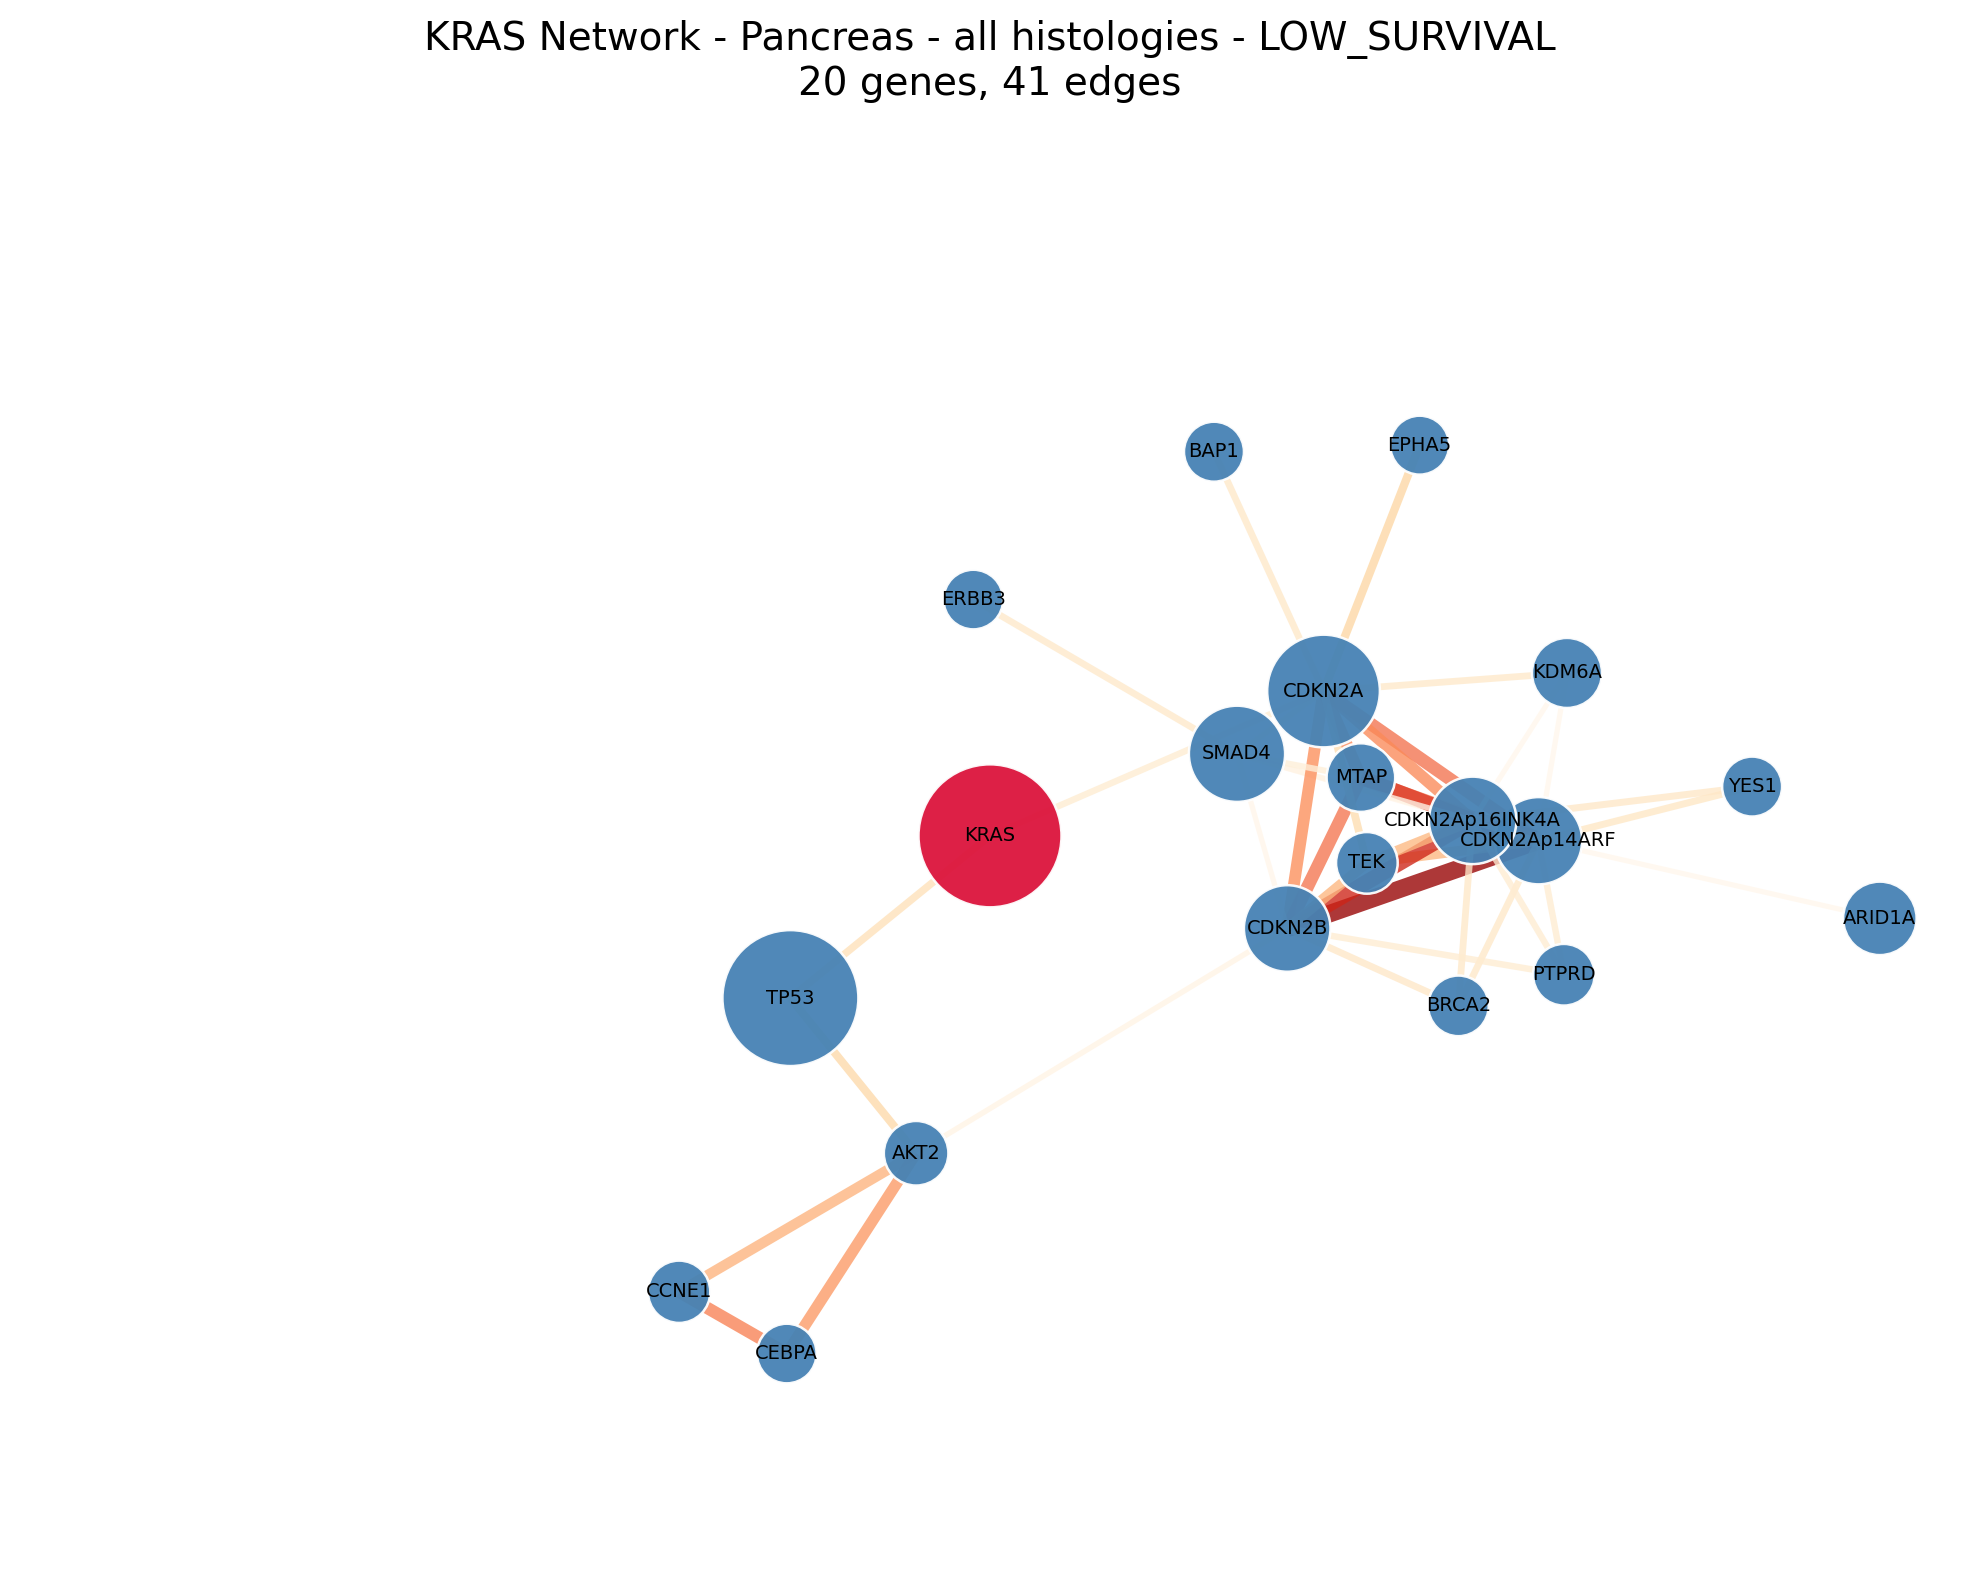


GROUP: PANCREAS_ALL (Pancreas - all histologies)
SURVIVAL GROUP: HIGH_SURVIVAL
Patients: 444
Genes: 475
Edges after filters: 76
KRAS subgraph: 42 genes, 73 edges


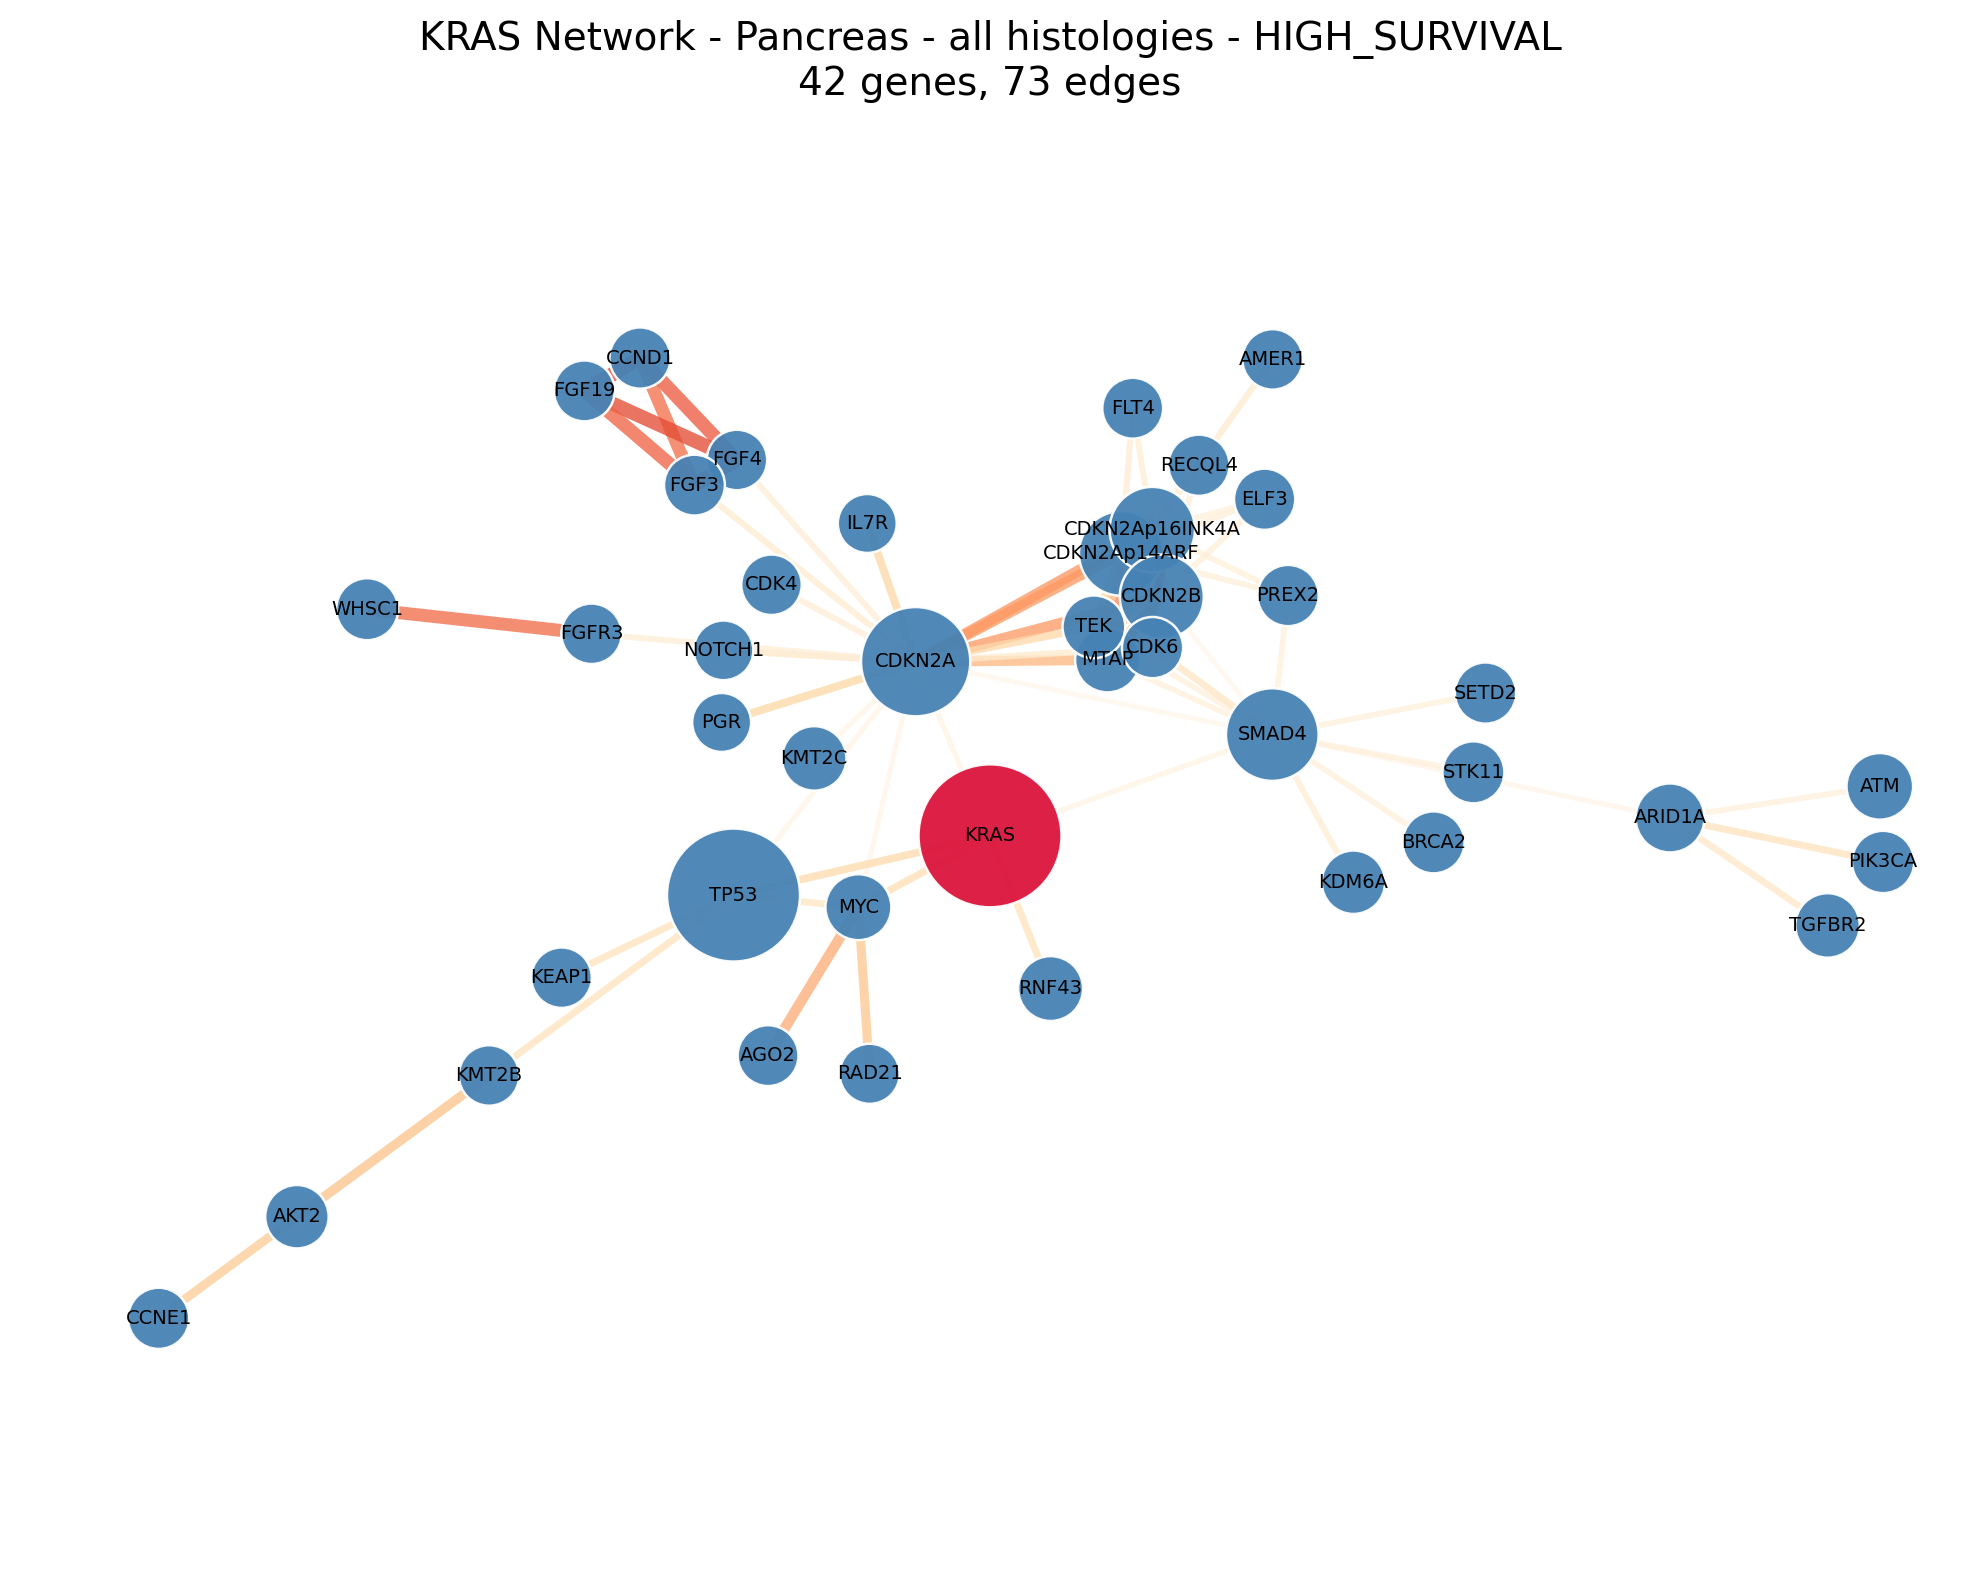


Clinical-to-network summary by survival group - PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,n_rows,n_genes_input,graph_nodes,graph_edges,contains_KRAS
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,3070,475,42,73,True
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,3288,464,20,41,True



Nota finale:
Sono state costruite reti KRAS per PANCREAS_ALL separate solo per survival_group. Non viene fatta nessuna separazione per istologia / Oncotree.
La soglia mediana usata per PANCREAS_ALL è OS_MONTHS = 9.2383 mesi.


In [23]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.stats import fisher_exact


# ============================================================
# SETTINGS
# ============================================================

min_log2_or = 1
max_p_value = 0.05
min_shared = 5
max_hops_from_kras = None

min_patients_for_network = 10

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

# File nuovo, già annotato con survival_group per pancreas generale
file_path_merged = (
        Path("data_pancreas")
        / "CLINICAL_merged_mutations_cna_sv_with_median_survival_groups_PANCREAS_ALL.csv"
)

# Gruppi median survival da analizzare
survival_groups_to_analyze = [
    "LOW_SURVIVAL",
    "HIGH_SURVIVAL"
]


# ============================================================
# Helper
# ============================================================

def assign_survival_group(value, median_value):
    """
    Stratifica i pazienti rispetto alla mediana di OS_MONTHS.

    LOW_SURVIVAL:
        OS_MONTHS < median_value

    HIGH_SURVIVAL:
        OS_MONTHS >= median_value
    """
    if pd.isna(value):
        return np.nan

    if value < median_value:
        return "LOW_SURVIVAL"

    return "HIGH_SURVIVAL"


# ============================================================
# FUNCTION: build KRAS-focused graph for one survival group
# ============================================================

def build_kras_network_for_pancreas_survival_group(
        df,
        group_name,
        group_col="survival_group",
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol",
        min_log2_or=1,
        max_p_value=0.05,
        min_shared=5,
        max_hops_from_kras=None,
        min_patients_for_network=10
):

    df_group = df[
        df[group_col] == group_name
        ].copy()

    tmp = (
        df_group[[patient_col, gene_col]]
        .dropna()
        .drop_duplicates()
    )

    print("\n" + "=" * 90)
    print(f"GROUP: {PANCREAS_GROUP} ({PANCREAS_LABEL})")
    print(f"SURVIVAL GROUP: {group_name}")
    print(f"Patients: {tmp[patient_col].nunique()}")
    print(f"Genes: {tmp[gene_col].nunique()}")

    if tmp[patient_col].nunique() < min_patients_for_network:
        print(f"Skipped: fewer than {min_patients_for_network} patients.")
        return None, None, df_group

    if tmp[gene_col].nunique() < 2:
        print("Skipped: fewer than 2 genes.")
        return None, None, df_group

    patient_gene = pd.crosstab(
        tmp[patient_col],
        tmp[gene_col]
    ).astype(bool).astype(int)

    N = patient_gene.shape[0]
    gene_counts = patient_gene.sum(axis=0)

    co = patient_gene.T @ patient_gene

    co_np = co.to_numpy(copy=True)
    np.fill_diagonal(co_np, 0)

    co = pd.DataFrame(
        co_np,
        index=co.index,
        columns=co.columns
    )

    edges = (
        co.where(np.triu(np.ones(co.shape), k=1).astype(bool))
        .stack()
        .rename("a_both")
        .rename_axis(index=["Gene1", "Gene2"])
        .reset_index()
    )

    edges = edges.dropna(subset=["a_both"]).copy()
    edges["a_both"] = edges["a_both"].astype(int)

    rows = []

    for r in edges.itertuples(index=False):
        g1, g2, a = r.Gene1, r.Gene2, int(r.a_both)

        b = int(gene_counts[g1] - a)
        c = int(gene_counts[g2] - a)
        d = int(N - a - b - c)

        odds_ratio, p_value = fisher_exact(
            [[a, b], [c, d]],
            alternative="greater"
        )

        log2_or = np.log2(
            ((a + 0.5) * (d + 0.5)) /
            ((b + 0.5) * (c + 0.5))
        )

        rows.append([
            g1,
            g2,
            a,
            b,
            c,
            d,
            odds_ratio,
            log2_or,
            p_value
        ])

    results = pd.DataFrame(
        rows,
        columns=[
            "Gene1",
            "Gene2",
            "a_both",
            "b_g1_only",
            "c_g2_only",
            "d_neither",
            "odds_ratio",
            "log2_OR",
            "p_value"
        ]
    )

    results["ONCOTREE_CODE"] = PANCREAS_GROUP
    results["Included_Oncotree_Codes"] = PANCREAS_LABEL
    results["survival_group"] = group_name
    results["n_patients_group"] = N

    edges_plot = (
        results[
            (results["log2_OR"] > min_log2_or)
            & (results["p_value"] < max_p_value)
            & (results["a_both"] >= min_shared)
            ]
        .sort_values(["p_value", "log2_OR"], ascending=[True, False])
        .copy()
    )

    print(f"Edges after filters: {len(edges_plot)}")

    G_plot = nx.Graph()

    for _, row in edges_plot.iterrows():
        G_plot.add_edge(
            row["Gene1"],
            row["Gene2"],
            log2_or=float(row["log2_OR"]),
            p_value=float(row["p_value"]),
            shared=int(row["a_both"]),
            oncotree_code=PANCREAS_GROUP,
            included_oncotree_codes=PANCREAS_LABEL,
            survival_group=group_name
        )

    if G_plot.number_of_nodes() == 0 or G_plot.number_of_edges() == 0:
        print("No edges with current thresholds.")
        return G_plot, results, df_group

    kras_nodes = [
        n for n in G_plot.nodes()
        if str(n).upper() == "KRAS"
    ]

    if not kras_nodes:
        print("KRAS is not present with these thresholds.")
        return G_plot, results, df_group

    kras_node = kras_nodes[0]

    distances = nx.single_source_shortest_path_length(
        G_plot,
        kras_node
    )

    if max_hops_from_kras is None:
        keep_nodes = set(distances.keys())
    else:
        keep_nodes = {
            n for n, d in distances.items()
            if d <= max_hops_from_kras
        }

    G_kras = G_plot.subgraph(keep_nodes).copy()

    print(
        f"KRAS subgraph: "
        f"{G_kras.number_of_nodes()} genes, "
        f"{G_kras.number_of_edges()} edges"
    )

    return G_kras, results, df_group


# ============================================================
# FUNCTION: plot KRAS-focused graph
# ============================================================

def plot_kras_network(
        G_kras,
        df_group,
        group_name,
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol"
):

    if G_kras is None or G_kras.number_of_edges() == 0:
        print(f"No graph to plot for {PANCREAS_GROUP} - {group_name}")
        return

    kras_nodes = [
        n for n in G_kras.nodes()
        if str(n).upper() == "KRAS"
    ]

    if not kras_nodes:
        print(f"KRAS not found in graph for {PANCREAS_GROUP} - {group_name}")
        return

    kras_node = kras_nodes[0]

    tmp = (
        df_group[[patient_col, gene_col]]
        .dropna()
        .drop_duplicates()
    )

    patient_gene = pd.crosstab(
        tmp[patient_col],
        tmp[gene_col]
    ).astype(bool).astype(int)

    gene_support = patient_gene.sum(axis=0).to_dict()

    plt.figure(figsize=(10, 8), dpi=200)

    local_dist = nx.single_source_shortest_path_length(
        G_kras,
        kras_node
    )

    max_d = max(local_dist.values())

    shells = [[kras_node]] + [
        [n for n in G_kras.nodes() if local_dist[n] == d]
        for d in range(1, max_d + 1)
    ]

    pos0 = nx.shell_layout(G_kras, nlist=shells)
    pos0[kras_node] = np.array([0.0, 0.0])

    pos = nx.spring_layout(
        G_kras,
        seed=42,
        k=0.9,
        pos=pos0,
        fixed=[kras_node],
        center=(0, 0),
        iterations=200
    )

    support_vals = [
        float(gene_support.get(n, 1))
        for n in G_kras.nodes()
    ]

    s_min = min(support_vals) if support_vals else 1.0
    s_max = max(support_vals) if support_vals else 1.0

    if s_max == s_min:
        node_sizes = [1000 for _ in G_kras.nodes()]
    else:
        node_sizes = [
            450 + 2200 *
            ((float(gene_support.get(n, s_min)) - s_min) / (s_max - s_min))
            for n in G_kras.nodes()
        ]

    node_colors = [
        "crimson" if str(n).upper() == "KRAS" else "steelblue"
        for n in G_kras.nodes()
    ]

    edge_vals = [
        G_kras[u][v].get("log2_or", 1.0)
        for u, v in G_kras.edges()
    ]

    max_edge = max(edge_vals) if edge_vals else 1.0

    edge_widths = [
        1.4 + 5.2 * (w / max_edge)
        for w in edge_vals
    ]

    nx.draw_networkx_edges(
        G_kras,
        pos,
        width=edge_widths,
        alpha=0.78,
        edge_color=edge_vals,
        edge_cmap=plt.cm.OrRd,
        edge_vmin=min(edge_vals) if edge_vals else 0.0,
        edge_vmax=max(edge_vals) if edge_vals else 1.0
    )

    nx.draw_networkx_nodes(
        G_kras,
        pos,
        node_size=node_sizes,
        node_color=node_colors,
        alpha=0.95,
        linewidths=0.9,
        edgecolors="white"
    )

    labels_all = {n: n for n in G_kras.nodes()}

    nx.draw_networkx_labels(
        G_kras,
        pos,
        labels=labels_all,
        font_size=7
    )

    xy = np.array(list(pos.values()))

    r = float(np.abs(xy).max()) if xy.size else 1.0
    lim = r + (0.08 * r + 0.05)

    plt.xlim(-lim, lim)
    plt.ylim(-lim, lim)

    plt.title(
        f"KRAS Network - {PANCREAS_LABEL} - {group_name}\n"
        f"{G_kras.number_of_nodes()} genes, {G_kras.number_of_edges()} edges",
        fontsize=14
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()


# ============================================================
# LOAD DATA
# ============================================================

df_merge = pd.read_csv(file_path_merged, low_memory=False)
df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

df_merge = df_merge.rename(columns={
    "PATIENT_ID": "Patient_ID",
    "Patient_ID": "Patient_ID",

    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree Code": "ONCOTREE_CODE",
    "Oncotree_Code": "ONCOTREE_CODE",

    "Oncotree_Group": "Oncotree_Group",
    "ONCOTREE_GROUP": "Oncotree_Group",
    "Oncotree Group": "Oncotree_Group",

    "Gene": "Hugo_Symbol",
    "Hugo_Symbol": "Hugo_Symbol",

    "Overall Survival (Months)": "OS_MONTHS",
    "Overall Survival Months": "OS_MONTHS",
    "OS_MONTH": "OS_MONTHS",
    "OS_MONTHS": "OS_MONTHS",

    "Overall Survival Status": "OS_STATUS",
    "OS_STATUS": "OS_STATUS",
    "OS Status": "OS_STATUS",

    "SURVIVAL_GROUP": "survival_group",
    "survival_group": "survival_group",

    "median_group": "median_group"
})

df_merge = df_merge.loc[:, ~df_merge.columns.duplicated()].copy()

required_cols = {
    "Patient_ID",
    "Hugo_Symbol"
}

missing_cols = required_cols - set(df_merge.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti nel file merged clinical-to-network pancreas all: {missing_cols}"
    )

if "survival_group" not in df_merge.columns and "OS_MONTHS" not in df_merge.columns:
    raise ValueError(
        "Colonna survival non trovata nel file merged clinical-to-network pancreas all. "
        "Dovrebbe esserci survival_group oppure OS_MONTHS."
    )

df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str).str.strip()
df_merge["Hugo_Symbol"] = df_merge["Hugo_Symbol"].astype(str).str.strip()

# OS_MONTHS numerico
if "OS_MONTHS" in df_merge.columns:
    df_merge["OS_MONTHS"] = pd.to_numeric(df_merge["OS_MONTHS"], errors="coerce")

# Se OS_STATUS manca, lo creo vuoto per compatibilità
if "OS_STATUS" not in df_merge.columns:
    df_merge["OS_STATUS"] = np.nan

# Creo event per eventuali controlli survival successivi
df_merge["event"] = (
    df_merge["OS_STATUS"]
    .astype(str)
    .str.contains("DECEASED", case=False, na=False)
    .astype(int)
)

# Creo survival_group se non è già presente nel file
if "survival_group" not in df_merge.columns:

    patient_level_survival = (
        df_merge[["Patient_ID", "OS_MONTHS"]]
        .dropna(subset=["Patient_ID", "OS_MONTHS"])
        .drop_duplicates(subset=["Patient_ID"])
        .copy()
    )

    survival_median = patient_level_survival["OS_MONTHS"].median()

    df_merge["survival_group"] = df_merge["OS_MONTHS"].apply(
        lambda x: assign_survival_group(x, survival_median)
    )

else:
    # Recupero la soglia mediana se già presente, altrimenti la ricalcolo
    if "survival_threshold_median_pancreas_all" in df_merge.columns:
        survival_median = (
            pd.to_numeric(
                df_merge["survival_threshold_median_pancreas_all"],
                errors="coerce"
            )
            .dropna()
            .iloc[0]
        )
    else:
        patient_level_survival = (
            df_merge[["Patient_ID", "OS_MONTHS"]]
            .dropna(subset=["Patient_ID", "OS_MONTHS"])
            .drop_duplicates(subset=["Patient_ID"])
            .copy()
        )

        survival_median = patient_level_survival["OS_MONTHS"].median()

df_merge["median_group"] = df_merge["survival_group"]
df_merge["survival_threshold_median_pancreas_all"] = survival_median

# Forzo gruppo unico pancreas
df_merge["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge["Oncotree_Group"] = PANCREAS_GROUP
df_merge["Included_Oncotree_Codes"] = PANCREAS_LABEL

# Se esiste ORIGINAL_ONCOTREE_CODE lo lascio come informazione descrittiva.
# Se non esiste, lo creo come Unknown.
if "ORIGINAL_ONCOTREE_CODE" not in df_merge.columns:
    df_merge["ORIGINAL_ONCOTREE_CODE"] = "Unknown"

df_merge["ORIGINAL_ONCOTREE_CODE"] = (
    df_merge["ORIGINAL_ONCOTREE_CODE"]
    .astype(str)
    .str.strip()
)

df_merge = df_merge.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "survival_group"
    ]
).copy()

df_merge["survival_group"] = df_merge["survival_group"].astype(str)

print("Loaded:")
print(file_path_merged)

print("\nMedian OS_MONTHS - PANCREAS_ALL:")
print(round(survival_median, 4))

print("\nSurvival group distribution - PANCREAS_ALL:")

try:
    display(
        df_merge
        .drop_duplicates(["Patient_ID"])
        .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
        .agg(
            n_patients=("Patient_ID", "nunique"),
            median_OS_MONTHS=("OS_MONTHS", "median"),
            mean_OS_MONTHS=("OS_MONTHS", "mean"),
            min_OS_MONTHS=("OS_MONTHS", "min"),
            max_OS_MONTHS=("OS_MONTHS", "max"),
            n_events=("event", "sum")
        )
        .reset_index()
        .sort_values(["ONCOTREE_CODE", "survival_group"])
    )
except NameError:
    print(
        df_merge
        .drop_duplicates(["Patient_ID"])
        .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
        .agg(
            n_patients=("Patient_ID", "nunique"),
            median_OS_MONTHS=("OS_MONTHS", "median"),
            mean_OS_MONTHS=("OS_MONTHS", "mean"),
            min_OS_MONTHS=("OS_MONTHS", "min"),
            max_OS_MONTHS=("OS_MONTHS", "max"),
            n_events=("event", "sum")
        )
        .reset_index()
        .sort_values(["ONCOTREE_CODE", "survival_group"])
    )


print("\nOriginal Oncotree Code distribution inside PANCREAS_ALL:")

try:
    display(
        df_merge
        .drop_duplicates(["Patient_ID", "ORIGINAL_ONCOTREE_CODE"])
        .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "ORIGINAL_ONCOTREE_CODE"])
        .agg(
            n_patients=("Patient_ID", "nunique")
        )
        .reset_index()
        .sort_values("n_patients", ascending=False)
    )
except NameError:
    print(
        df_merge
        .drop_duplicates(["Patient_ID", "ORIGINAL_ONCOTREE_CODE"])
        .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "ORIGINAL_ONCOTREE_CODE"])
        .agg(
            n_patients=("Patient_ID", "nunique")
        )
        .reset_index()
        .sort_values("n_patients", ascending=False)
    )


# ============================================================
# BUILD AND PLOT NETWORKS BY SURVIVAL GROUP
# ============================================================

graphs_by_survival = {}
results_by_survival = {}
df_by_survival = {}

for group_name in survival_groups_to_analyze:

    G_group, results_group, df_group = build_kras_network_for_pancreas_survival_group(
        df=df_merge,
        group_name=group_name,
        group_col="survival_group",
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol",
        min_log2_or=min_log2_or,
        max_p_value=max_p_value,
        min_shared=min_shared,
        max_hops_from_kras=max_hops_from_kras,
        min_patients_for_network=min_patients_for_network
    )

    graphs_by_survival[group_name] = G_group
    results_by_survival[group_name] = results_group
    df_by_survival[group_name] = df_group

    plot_kras_network(
        G_kras=G_group,
        df_group=df_group,
        group_name=group_name,
        patient_col="Patient_ID",
        gene_col="Hugo_Symbol"
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

summary_rows = []

for group_name, G in graphs_by_survival.items():

    if G is None:
        n_nodes = 0
        n_edges = 0
        has_kras = False
    else:
        n_nodes = G.number_of_nodes()
        n_edges = G.number_of_edges()
        has_kras = any(str(n).upper() == "KRAS" for n in G.nodes())

    df_tmp = df_merge[
        df_merge["survival_group"] == group_name
        ]

    summary_rows.append({
        "ONCOTREE_CODE": PANCREAS_GROUP,
        "Included_Oncotree_Codes": PANCREAS_LABEL,
        "survival_group": group_name,
        "n_patients": df_tmp["Patient_ID"].nunique(),
        "n_rows": df_tmp.shape[0],
        "n_genes_input": df_tmp["Hugo_Symbol"].nunique(),
        "graph_nodes": n_nodes,
        "graph_edges": n_edges,
        "contains_KRAS": has_kras
    })

clinical_network_summary = (
    pd.DataFrame(summary_rows)
    .sort_values(["survival_group"])
    .reset_index(drop=True)
)

print("\nClinical-to-network summary by survival group - PANCREAS_ALL:")

try:
    display(clinical_network_summary)
except NameError:
    print(clinical_network_summary)


# ============================================================
# COMPATIBILITY ALIASES
# ============================================================

graphs_by_pancreas_survival = graphs_by_survival
results_by_pancreas_survival = results_by_survival

# Alias compatibili se celle successive cercano ancora questi nomi
graphs_by_oncotree_survival = {
    PANCREAS_GROUP: graphs_by_survival
}

results_by_oncotree_survival = {
    PANCREAS_GROUP: results_by_survival
}

graphs_by_oncotree_group_survival = graphs_by_oncotree_survival
results_by_oncotree_group_survival = results_by_oncotree_survival

print("\nNota finale:")
print(
    "Sono state costruite reti KRAS per PANCREAS_ALL separate solo per survival_group. "
    "Non viene fatta nessuna separazione per istologia / Oncotree."
)
print(
    f"La soglia mediana usata per PANCREAS_ALL è OS_MONTHS = {survival_median:.4f} mesi."
)

#### 3. Hub analysis e confronto HIGH vs LOW

In [24]:
import pandas as pd
import numpy as np
import networkx as nx
from pathlib import Path
import re

# ============================================================
# HUB ANALYSIS - PANCREAS OVERALL
# MEDIAN SURVIVAL networks within PANCREAS_ALL
#
# Confronto:
#   LOW_SURVIVAL
#   HIGH_SURVIVAL
#
# Nessuna separazione per istologia / ONCOTREE_CODE.
# ============================================================

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"


# ============================================================
# 0. Recupero dei grafi creati nella cella precedente
# ============================================================

if "graphs_by_pancreas_survival" in globals():
    graphs_by_survival = globals()["graphs_by_pancreas_survival"]

elif "graphs_by_survival" in globals():
    graphs_by_survival = globals()["graphs_by_survival"]

elif "graphs_by_oncotree_survival" in globals():
    # Compatibilità con la cella precedente, se hai salvato così:
    # graphs_by_oncotree_survival = {PANCREAS_ALL: graphs_by_survival}
    if PANCREAS_GROUP in graphs_by_oncotree_survival:
        graphs_by_survival = graphs_by_oncotree_survival[PANCREAS_GROUP]
    else:
        raise ValueError(
            f"{PANCREAS_GROUP} non trovato in graphs_by_oncotree_survival. "
            "Esegui prima la cella che costruisce le network per PANCREAS_ALL."
        )

elif "graphs_by_oncotree_group_survival" in globals():
    if PANCREAS_GROUP in graphs_by_oncotree_group_survival:
        graphs_by_survival = graphs_by_oncotree_group_survival[PANCREAS_GROUP]
    else:
        raise ValueError(
            f"{PANCREAS_GROUP} non trovato in graphs_by_oncotree_group_survival. "
            "Esegui prima la cella che costruisce le network per PANCREAS_ALL."
        )

else:
    raise ValueError(
        "Nessuna variabile con i grafi disponibile. "
        "Esegui prima la cella che costruisce le network KRAS per PANCREAS_ALL "
        "separate per survival_group."
    )


survival_groups_to_compare = [
    "LOW_SURVIVAL",
    "HIGH_SURVIVAL"
]

hub_output_dir = (
        Path("data_pancreas")
        / "clinical_to_network_median_pancreas_all"
        / "hub_analysis_pancreas_all_median_survival"
)

hub_output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# Helper
# ============================================================

def safe_filename(text):
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9_-]+", "_", text)
    return text.strip("_")


def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


# ============================================================
# FUNCTION: compute hub table
# ============================================================

def compute_hub_table(
        G,
        group_name,
        weight_col="log2_or"
):
    """
    Calcola le metriche hub per una network specifica:

    - gruppo unico: PANCREAS_ALL
    - survival group: LOW_SURVIVAL / HIGH_SURVIVAL

    Metriche:
    - Degree
    - Node Strength
    - Betweenness
    - Closeness
    - HubScore composito
    """

    if G is None or G.number_of_nodes() == 0 or G.number_of_edges() == 0:
        print(f"No graph available for {PANCREAS_GROUP} - {group_name}")
        return pd.DataFrame()

    degree = dict(G.degree())

    node_strength = {
        n: sum(
            G[n][nbr].get(weight_col, 1.0)
            for nbr in G.neighbors(n)
        )
        for n in G.nodes()
    }

    betweenness = nx.betweenness_centrality(
        G,
        weight=weight_col,
        normalized=True
    )

    closeness = nx.closeness_centrality(G)

    hub_df = pd.DataFrame({
        "ONCOTREE_CODE": PANCREAS_GROUP,
        "Included_Oncotree_Codes": PANCREAS_LABEL,
        "survival_group": group_name,
        "Gene": list(G.nodes()),
        "Degree": [degree.get(g, 0) for g in G.nodes()],
        "Node_Strength": [node_strength.get(g, 0) for g in G.nodes()],
        "Betweenness": [betweenness.get(g, 0) for g in G.nodes()],
        "Closeness": [closeness.get(g, 0) for g in G.nodes()],
        "Graph_nodes": G.number_of_nodes(),
        "Graph_edges": G.number_of_edges(),
        "Graph_density": nx.density(G)
    })

    # HubScore composito
    hub_df["HubScore"] = (
            hub_df["Degree"].rank(pct=True) * 0.25
            + hub_df["Node_Strength"].rank(pct=True) * 0.25
            + hub_df["Betweenness"].rank(pct=True) * 0.25
            + hub_df["Closeness"].rank(pct=True) * 0.25
    )

    hub_df = hub_df.sort_values(
        "HubScore",
        ascending=False
    ).reset_index(drop=True)

    hub_df["Rank_in_network"] = hub_df.index + 1

    return hub_df


# ============================================================
# 1. Compute hub tables for each survival group
# ============================================================

hub_tables_by_pancreas_survival = {}
all_hub_tables_survival = []

for group_name in survival_groups_to_compare:

    G = graphs_by_survival.get(group_name, None)

    hub_df = compute_hub_table(
        G=G,
        group_name=group_name
    )

    hub_tables_by_pancreas_survival[group_name] = hub_df

    if not hub_df.empty:
        all_hub_tables_survival.append(hub_df)

        safe_group_name = safe_filename(group_name)

        output_file = (
                hub_output_dir
                / f"hub_genes_{PANCREAS_GROUP}_{safe_group_name}_survival_network.csv"
        )

        hub_df.to_csv(output_file, index=False)

        print(f"Saved: {output_file}")


# ============================================================
# 2. Combined hub table
# ============================================================

if len(all_hub_tables_survival) > 0:
    hub_all_pancreas_survival = pd.concat(
        all_hub_tables_survival,
        ignore_index=True
    )

    hub_all_file = (
            hub_output_dir
            / "hub_genes_all_pancreas_survival_networks.csv"
    )

    hub_all_pancreas_survival.to_csv(
        hub_all_file,
        index=False
    )

    print("\nSaved combined hub table:")
    print(hub_all_file)

else:
    hub_all_pancreas_survival = pd.DataFrame()
    print("No hub tables were created.")


# ============================================================
# 3. Display top hubs per survival group
# ============================================================

top_n = 20

print("\n" + "#" * 100)
print(f"GROUP: {PANCREAS_GROUP} ({PANCREAS_LABEL})")
print("#" * 100)

for group_name in survival_groups_to_compare:

    hub_df = hub_tables_by_pancreas_survival.get(group_name, pd.DataFrame())

    print("\n" + "=" * 90)
    print(
        f"TOP HUB GENES - {PANCREAS_GROUP} ({PANCREAS_LABEL}) - "
        f"{group_name} NETWORK"
    )
    print("=" * 90)

    if hub_df is None or hub_df.empty:
        print(f"No hub table available for {PANCREAS_GROUP} - {group_name}")
        continue

    print(
        f"Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti "
        f"{group_name} del pancreas generale."
    )

    safe_display(
        hub_df[
            [
                "ONCOTREE_CODE",
                "Included_Oncotree_Codes",
                "survival_group",
                "Gene",
                "Degree",
                "Node_Strength",
                "Betweenness",
                "Closeness",
                "HubScore",
                "Rank_in_network"
            ]
        ].head(top_n)
    )


# ============================================================
# 4. Compare LOW_SURVIVAL vs HIGH_SURVIVAL hub scores
# ============================================================

low_label = "LOW_SURVIVAL"
high_label = "HIGH_SURVIVAL"

hub_low = hub_tables_by_pancreas_survival.get(low_label, pd.DataFrame())
hub_high = hub_tables_by_pancreas_survival.get(high_label, pd.DataFrame())

hub_comparison_pancreas_survival = pd.DataFrame()

if hub_low is None or hub_low.empty:
    print(f"[{PANCREAS_GROUP}] {low_label} hub table missing or empty. Skipping comparison.")

elif hub_high is None or hub_high.empty:
    print(f"[{PANCREAS_GROUP}] {high_label} hub table missing or empty. Skipping comparison.")

else:
    hub_low_for_merge = hub_low.copy()
    hub_high_for_merge = hub_high.copy()

    hub_low_for_merge = hub_low_for_merge.drop(
        columns=["survival_group"],
        errors="ignore"
    )

    hub_high_for_merge = hub_high_for_merge.drop(
        columns=["survival_group"],
        errors="ignore"
    )

    hub_comparison_pancreas_survival = hub_low_for_merge.merge(
        hub_high_for_merge,
        on=[
            "ONCOTREE_CODE",
            "Included_Oncotree_Codes",
            "Gene"
        ],
        how="outer",
        suffixes=("_low_survival", "_high_survival")
    )

    hub_comparison_pancreas_survival["Delta_HubScore_low_minus_high"] = (
            hub_comparison_pancreas_survival["HubScore_low_survival"].fillna(0)
            - hub_comparison_pancreas_survival["HubScore_high_survival"].fillna(0)
    )

    hub_comparison_pancreas_survival["Delta_Degree_low_minus_high"] = (
            hub_comparison_pancreas_survival["Degree_low_survival"].fillna(0)
            - hub_comparison_pancreas_survival["Degree_high_survival"].fillna(0)
    )

    hub_comparison_pancreas_survival["Delta_Node_Strength_low_minus_high"] = (
            hub_comparison_pancreas_survival["Node_Strength_low_survival"].fillna(0)
            - hub_comparison_pancreas_survival["Node_Strength_high_survival"].fillna(0)
    )

    output_file = (
            hub_output_dir
            / f"hub_genes_{PANCREAS_GROUP}_low_vs_high_survival_comparison.csv"
    )

    hub_comparison_pancreas_survival.to_csv(output_file, index=False)

    print(f"\nSaved comparison for {PANCREAS_GROUP}:")
    print(output_file)


    # ------------------------------------------------------------
    # Genes more important in LOW_SURVIVAL network
    # ------------------------------------------------------------

    print("\n" + "=" * 90)
    print(f"GENES MORE IMPORTANT IN LOW_SURVIVAL NETWORK - {PANCREAS_GROUP}")
    print("=" * 90)
    print(
        "Delta positivo = il gene è più hub/importante nella rete LOW_SURVIVAL "
        "rispetto alla rete HIGH_SURVIVAL, nel pancreas generale."
    )

    safe_display(
        hub_comparison_pancreas_survival
        .sort_values("Delta_HubScore_low_minus_high", ascending=False)
        [
            [
                "ONCOTREE_CODE",
                "Included_Oncotree_Codes",
                "Gene",
                "HubScore_low_survival",
                "HubScore_high_survival",
                "Delta_HubScore_low_minus_high",
                "Degree_low_survival",
                "Degree_high_survival",
                "Node_Strength_low_survival",
                "Node_Strength_high_survival"
            ]
        ]
        .head(top_n)
    )


    # ------------------------------------------------------------
    # Genes more important in HIGH_SURVIVAL network
    # ------------------------------------------------------------

    print("\n" + "=" * 90)
    print(f"GENES MORE IMPORTANT IN HIGH_SURVIVAL NETWORK - {PANCREAS_GROUP}")
    print("=" * 90)
    print(
        "Delta negativo = il gene è più hub/importante nella rete HIGH_SURVIVAL "
        "rispetto alla rete LOW_SURVIVAL, nel pancreas generale."
    )

    safe_display(
        hub_comparison_pancreas_survival
        .sort_values("Delta_HubScore_low_minus_high", ascending=True)
        [
            [
                "ONCOTREE_CODE",
                "Included_Oncotree_Codes",
                "Gene",
                "HubScore_low_survival",
                "HubScore_high_survival",
                "Delta_HubScore_low_minus_high",
                "Degree_low_survival",
                "Degree_high_survival",
                "Node_Strength_low_survival",
                "Node_Strength_high_survival"
            ]
        ]
        .head(top_n)
    )


# ============================================================
# 5. Combined comparison table
# ============================================================

if hub_comparison_pancreas_survival is not None and not hub_comparison_pancreas_survival.empty:

    combined_comparison_file = (
            hub_output_dir
            / "hub_genes_low_vs_high_survival_comparison_pancreas_all.csv"
    )

    hub_comparison_pancreas_survival.to_csv(
        combined_comparison_file,
        index=False
    )

    print("\nSaved combined survival group comparison:")
    print(combined_comparison_file)

    print("\nCombined comparison preview:")

    safe_display(
        hub_comparison_pancreas_survival
        .sort_values(
            "Delta_HubScore_low_minus_high",
            ascending=False
        )
        .head(40)
    )

else:
    print("No survival group comparison table was created.")


# ============================================================
# OPTIONAL COMPATIBILITY ALIASES
# ============================================================

hub_tables_by_survival = hub_tables_by_pancreas_survival
hub_tables_by_pancreas_survival = hub_tables_by_pancreas_survival

hub_comparison_all_pancreas_survival = hub_comparison_pancreas_survival
hub_comparison_all_oncotree = hub_comparison_pancreas_survival
hub_comparison_all_oncotree_groups = hub_comparison_pancreas_survival
hub_comparison_all_oncotree_survival = hub_comparison_pancreas_survival

hub_all_oncotree_survival = hub_all_pancreas_survival
hub_all_pancreas_survival = hub_all_pancreas_survival

# Alias compatibile se celle successive si aspettano struttura nested per Oncotree
hub_tables_by_oncotree_survival = {
    PANCREAS_GROUP: hub_tables_by_pancreas_survival
}

hub_tables_by_oncotree_group_survival = hub_tables_by_oncotree_survival

print("\nNota finale:")
print(
    "La hub analysis è stata eseguita su PANCREAS_ALL, separando solo per survival_group. "
    "Non viene fatta nessuna separazione per istologia / Oncotree."
)

Saved: data_pancreas\clinical_to_network_median_pancreas_all\hub_analysis_pancreas_all_median_survival\hub_genes_PANCREAS_ALL_LOW_SURVIVAL_survival_network.csv
Saved: data_pancreas\clinical_to_network_median_pancreas_all\hub_analysis_pancreas_all_median_survival\hub_genes_PANCREAS_ALL_HIGH_SURVIVAL_survival_network.csv

Saved combined hub table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_analysis_pancreas_all_median_survival\hub_genes_all_pancreas_survival_networks.csv

####################################################################################################
GROUP: PANCREAS_ALL (Pancreas - all histologies)
####################################################################################################

TOP HUB GENES - PANCREAS_ALL (Pancreas - all histologies) - LOW_SURVIVAL NETWORK
Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti LOW_SURVIVAL del pancreas generale.


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,CDKN2Ap14ARF,11,49.909539,0.298246,0.633333,0.94375,1
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,CDKN2B,9,43.891574,0.315789,0.655172,0.91250,2
2,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,CDKN2A,10,39.490822,0.327485,0.633333,0.91250,3
3,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,CDKN2Ap16INK4A,10,48.154454,0.052632,0.612903,0.86875,4
4,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,SMAD4,6,8.796310,0.578947,0.542857,0.78750,5
5,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,AKT2,4,15.215952,0.257310,0.475000,0.70625,6
6,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,MTAP,5,29.910350,0.000000,0.527778,0.65625,7
7,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,TEK,4,17.712271,0.000000,0.500000,0.61250,8
8,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,KDM6A,3,4.294483,0.011696,0.452381,0.50000,9
9,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,BRCA2,3,6.808071,0.000000,0.452381,0.48125,10



TOP HUB GENES - PANCREAS_ALL (Pancreas - all histologies) - HIGH_SURVIVAL NETWORK
Questa tabella mostra i geni più centrali nella rete costruita solo sui pazienti HIGH_SURVIVAL del pancreas generale.


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,CDKN2A,18,58.700757,0.697561,0.585714,1.000000,1
1,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,SMAD4,12,20.189035,0.539024,0.488095,0.922619,2
2,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,CDKN2Ap16INK4A,11,55.414807,0.101220,0.431579,0.916667,3
3,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,CDKN2B,9,45.828932,0.080488,0.460674,0.892857,4
4,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,CDKN2Ap14ARF,10,52.823583,0.001220,0.427083,0.827381,5
5,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,TP53,5,13.827804,0.184146,0.422680,0.812500,6
6,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,CDK6,5,10.941333,0.099797,0.440860,0.800595,7
7,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,MYC,5,18.807234,0.096341,0.414141,0.788690,8
8,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,KRAS,5,12.849473,0.048780,0.455556,0.782738,9
9,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,FGF3,4,30.099571,0.092683,0.390476,0.776786,10



Saved comparison for PANCREAS_ALL:
data_pancreas\clinical_to_network_median_pancreas_all\hub_analysis_pancreas_all_median_survival\hub_genes_PANCREAS_ALL_low_vs_high_survival_comparison.csv

GENES MORE IMPORTANT IN LOW_SURVIVAL NETWORK - PANCREAS_ALL
Delta positivo = il gene è più hub/importante nella rete LOW_SURVIVAL rispetto alla rete HIGH_SURVIVAL, nel pancreas generale.


,ONCOTREE_CODE,Included_Oncotree_Codes,Gene,HubScore_low_survival,HubScore_high_survival,Delta_HubScore_low_minus_high,Degree_low_survival,Degree_high_survival,Node_Strength_low_survival,Node_Strength_high_survival
36,PANCREAS_ALL,Pancreas - all histologies,PTPRD,0.45625,NaN,0.456250,3.0,NaN,5.853403,NaN
47,PANCREAS_ALL,Pancreas - all histologies,YES1,0.35625,NaN,0.356250,2.0,NaN,4.718091,NaN
15,PANCREAS_ALL,Pancreas - all histologies,CEBPA,0.35000,NaN,0.350000,2.0,NaN,12.195506,NaN
17,PANCREAS_ALL,Pancreas - all histologies,EPHA5,0.23750,NaN,0.237500,1.0,NaN,3.373767,NaN
1,PANCREAS_ALL,Pancreas - all histologies,AKT2,0.70625,0.473214,0.233036,4.0,2.0,15.215952,10.206393
5,PANCREAS_ALL,Pancreas - all histologies,BAP1,0.22500,NaN,0.225000,1.0,NaN,2.242311,NaN
6,PANCREAS_ALL,Pancreas - all histologies,BRCA2,0.48125,0.261905,0.219345,3.0,1.0,6.808071,1.764819
25,PANCREAS_ALL,Pancreas - all histologies,KDM6A,0.50000,0.288690,0.211310,3.0,1.0,4.294483,2.079392
18,PANCREAS_ALL,Pancreas - all histologies,ERBB3,0.17500,NaN,0.175000,1.0,NaN,2.194969,NaN
12,PANCREAS_ALL,Pancreas - all histologies,CDKN2Ap14ARF,0.94375,0.827381,0.116369,11.0,10.0,49.909539,52.823583



GENES MORE IMPORTANT IN HIGH_SURVIVAL NETWORK - PANCREAS_ALL
Delta negativo = il gene è più hub/importante nella rete HIGH_SURVIVAL rispetto alla rete LOW_SURVIVAL, nel pancreas generale.


,ONCOTREE_CODE,Included_Oncotree_Codes,Gene,HubScore_low_survival,HubScore_high_survival,Delta_HubScore_low_minus_high,Degree_low_survival,Degree_high_survival,Node_Strength_low_survival,Node_Strength_high_survival
10,PANCREAS_ALL,Pancreas - all histologies,CDK6,NaN,0.800595,-0.800595,NaN,5.0,NaN,10.941333
31,PANCREAS_ALL,Pancreas - all histologies,MYC,NaN,0.788690,-0.788690,NaN,5.0,NaN,18.807234
20,PANCREAS_ALL,Pancreas - all histologies,FGF3,NaN,0.776786,-0.776786,NaN,4.0,NaN,30.099571
21,PANCREAS_ALL,Pancreas - all histologies,FGF4,NaN,0.657738,-0.657738,NaN,4.0,NaN,31.391674
22,PANCREAS_ALL,Pancreas - all histologies,FGFR3,NaN,0.639881,-0.639881,NaN,2.0,NaN,10.851990
35,PANCREAS_ALL,Pancreas - all histologies,PREX2,NaN,0.595238,-0.595238,NaN,3.0,NaN,5.512927
27,PANCREAS_ALL,Pancreas - all histologies,KMT2B,NaN,0.556548,-0.556548,NaN,2.0,NaN,8.392674
38,PANCREAS_ALL,Pancreas - all histologies,RECQL4,NaN,0.550595,-0.550595,NaN,3.0,NaN,5.660277
16,PANCREAS_ALL,Pancreas - all histologies,ELF3,NaN,0.550595,-0.550595,NaN,3.0,NaN,5.660277
19,PANCREAS_ALL,Pancreas - all histologies,FGF19,NaN,0.485119,-0.485119,NaN,3.0,NaN,29.238217



Saved combined survival group comparison:
data_pancreas\clinical_to_network_median_pancreas_all\hub_analysis_pancreas_all_median_survival\hub_genes_low_vs_high_survival_comparison_pancreas_all.csv

Combined comparison preview:


,ONCOTREE_CODE,Included_Oncotree_Codes,Gene,Degree_low_survival,Node_Strength_low_survival,Betweenness_low_survival,Closeness_low_survival,Graph_nodes_low_survival,Graph_edges_low_survival,Graph_density_low_survival,...,Betweenness_high_survival,Closeness_high_survival,Graph_nodes_high_survival,Graph_edges_high_survival,Graph_density_high_survival,HubScore_high_survival,Rank_in_network_high_survival,Delta_HubScore_low_minus_high,Delta_Degree_low_minus_high,Delta_Node_Strength_low_minus_high
36,PANCREAS_ALL,Pancreas - all histologies,PTPRD,3.0,5.853403,0.000000,0.452381,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.456250,3.0,5.853403
47,PANCREAS_ALL,Pancreas - all histologies,YES1,2.0,4.718091,0.000000,0.404255,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.356250,2.0,4.718091
15,PANCREAS_ALL,Pancreas - all histologies,CEBPA,2.0,12.195506,0.000000,0.333333,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.350000,2.0,12.195506
17,PANCREAS_ALL,Pancreas - all histologies,EPHA5,1.0,3.373767,0.000000,0.395833,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.237500,1.0,3.373767
1,PANCREAS_ALL,Pancreas - all histologies,AKT2,4.0,15.215952,0.257310,0.475000,20.0,41.0,0.215789,...,0.048780,0.239766,42.0,73.0,0.084785,0.473214,22.0,0.233036,2.0,5.009559
5,PANCREAS_ALL,Pancreas - all histologies,BAP1,1.0,2.242311,0.000000,0.395833,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.225000,1.0,2.242311
6,PANCREAS_ALL,Pancreas - all histologies,BRCA2,3.0,6.808071,0.000000,0.452381,20.0,41.0,0.215789,...,0.000000,0.330645,42.0,73.0,0.084785,0.261905,37.0,0.219345,2.0,5.043252
25,PANCREAS_ALL,Pancreas - all histologies,KDM6A,3.0,4.294483,0.011696,0.452381,20.0,41.0,0.215789,...,0.000000,0.330645,42.0,73.0,0.084785,0.288690,33.0,0.211310,2.0,2.215091
18,PANCREAS_ALL,Pancreas - all histologies,ERBB3,1.0,2.194969,0.000000,0.358491,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.175000,1.0,2.194969
12,PANCREAS_ALL,Pancreas - all histologies,CDKN2Ap14ARF,11.0,49.909539,0.298246,0.633333,20.0,41.0,0.215789,...,0.001220,0.427083,42.0,73.0,0.084785,0.827381,5.0,0.116369,1.0,-2.914043



Nota finale:
La hub analysis è stata eseguita su PANCREAS_ALL, separando solo per survival_group. Non viene fatta nessuna separazione per istologia / Oncotree.


#### 4. Plot degli hub e differenze HIGH vs LOW


####################################################################################################
GROUP: PANCREAS_ALL (Pancreas - all histologies)
####################################################################################################


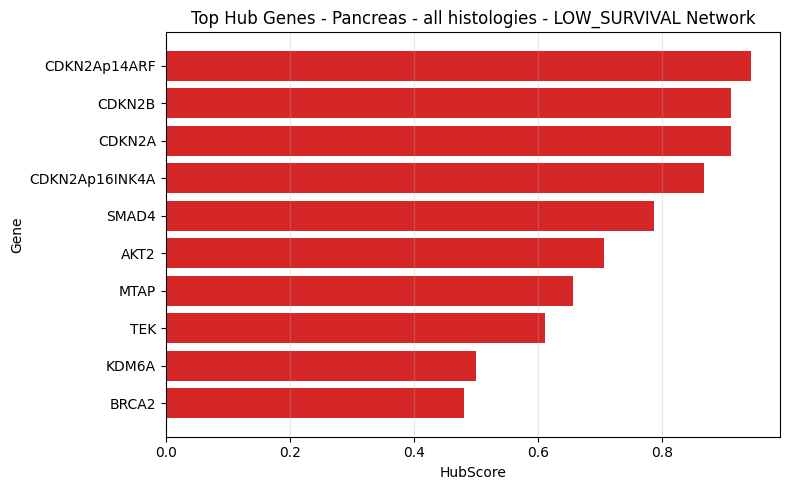

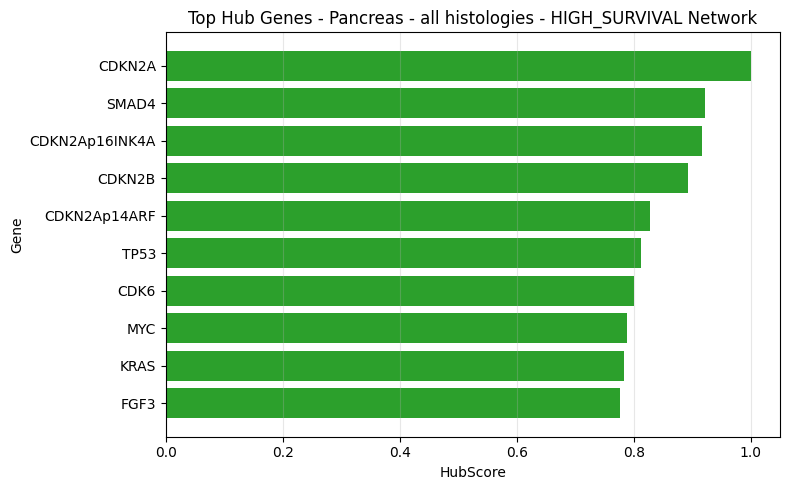

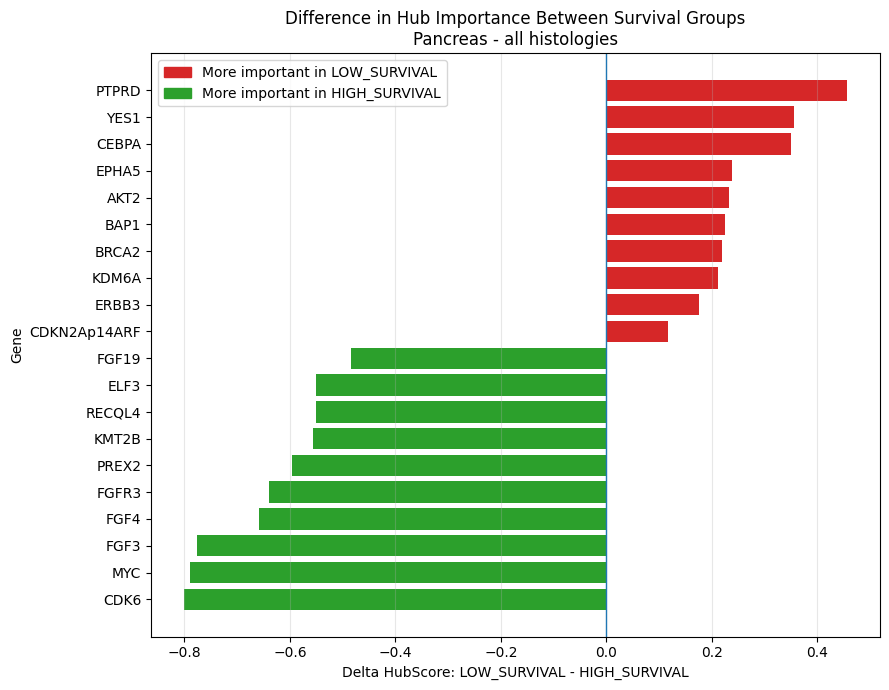


Top hubs - LOW_SURVIVAL:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,CDKN2Ap14ARF,11,49.909539,0.298246,0.633333,0.94375,1
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,CDKN2B,9,43.891574,0.315789,0.655172,0.91250,2
2,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,CDKN2A,10,39.490822,0.327485,0.633333,0.91250,3
3,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,CDKN2Ap16INK4A,10,48.154454,0.052632,0.612903,0.86875,4
4,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,SMAD4,6,8.796310,0.578947,0.542857,0.78750,5
5,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,AKT2,4,15.215952,0.257310,0.475000,0.70625,6
6,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,MTAP,5,29.910350,0.000000,0.527778,0.65625,7
7,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,TEK,4,17.712271,0.000000,0.500000,0.61250,8
8,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,KDM6A,3,4.294483,0.011696,0.452381,0.50000,9
9,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,BRCA2,3,6.808071,0.000000,0.452381,0.48125,10



Top hubs - HIGH_SURVIVAL:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,Gene,Degree,Node_Strength,Betweenness,Closeness,HubScore,Rank_in_network
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,CDKN2A,18,58.700757,0.697561,0.585714,1.000000,1
1,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,SMAD4,12,20.189035,0.539024,0.488095,0.922619,2
2,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,CDKN2Ap16INK4A,11,55.414807,0.101220,0.431579,0.916667,3
3,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,CDKN2B,9,45.828932,0.080488,0.460674,0.892857,4
4,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,CDKN2Ap14ARF,10,52.823583,0.001220,0.427083,0.827381,5
5,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,TP53,5,13.827804,0.184146,0.422680,0.812500,6
6,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,CDK6,5,10.941333,0.099797,0.440860,0.800595,7
7,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,MYC,5,18.807234,0.096341,0.414141,0.788690,8
8,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,KRAS,5,12.849473,0.048780,0.455556,0.782738,9
9,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,FGF3,4,30.099571,0.092683,0.390476,0.776786,10



Hub difference LOW_SURVIVAL vs HIGH_SURVIVAL:


,ONCOTREE_CODE,Included_Oncotree_Codes,Gene,Degree_low_survival,Node_Strength_low_survival,Betweenness_low_survival,Closeness_low_survival,Graph_nodes_low_survival,Graph_edges_low_survival,Graph_density_low_survival,...,Betweenness_high_survival,Closeness_high_survival,Graph_nodes_high_survival,Graph_edges_high_survival,Graph_density_high_survival,HubScore_high_survival,Rank_in_network_high_survival,Delta_HubScore_low_minus_high,Delta_Degree_low_minus_high,Delta_Node_Strength_low_minus_high
36,PANCREAS_ALL,Pancreas - all histologies,PTPRD,3.0,5.853403,0.000000,0.452381,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.456250,3.0,5.853403
47,PANCREAS_ALL,Pancreas - all histologies,YES1,2.0,4.718091,0.000000,0.404255,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.356250,2.0,4.718091
15,PANCREAS_ALL,Pancreas - all histologies,CEBPA,2.0,12.195506,0.000000,0.333333,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.350000,2.0,12.195506
17,PANCREAS_ALL,Pancreas - all histologies,EPHA5,1.0,3.373767,0.000000,0.395833,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.237500,1.0,3.373767
1,PANCREAS_ALL,Pancreas - all histologies,AKT2,4.0,15.215952,0.257310,0.475000,20.0,41.0,0.215789,...,0.048780,0.239766,42.0,73.0,0.084785,0.473214,22.0,0.233036,2.0,5.009559
5,PANCREAS_ALL,Pancreas - all histologies,BAP1,1.0,2.242311,0.000000,0.395833,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.225000,1.0,2.242311
6,PANCREAS_ALL,Pancreas - all histologies,BRCA2,3.0,6.808071,0.000000,0.452381,20.0,41.0,0.215789,...,0.000000,0.330645,42.0,73.0,0.084785,0.261905,37.0,0.219345,2.0,5.043252
25,PANCREAS_ALL,Pancreas - all histologies,KDM6A,3.0,4.294483,0.011696,0.452381,20.0,41.0,0.215789,...,0.000000,0.330645,42.0,73.0,0.084785,0.288690,33.0,0.211310,2.0,2.215091
18,PANCREAS_ALL,Pancreas - all histologies,ERBB3,1.0,2.194969,0.000000,0.358491,20.0,41.0,0.215789,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.175000,1.0,2.194969
12,PANCREAS_ALL,Pancreas - all histologies,CDKN2Ap14ARF,11.0,49.909539,0.298246,0.633333,20.0,41.0,0.215789,...,0.001220,0.427083,42.0,73.0,0.084785,0.827381,5.0,0.116369,1.0,-2.914043



Nota finale:
I grafici mostrano la hub importance per PANCREAS_ALL, separando solo i pazienti LOW_SURVIVAL e HIGH_SURVIVAL. Non viene fatta nessuna separazione per istologia / Oncotree.


In [25]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np

# ============================================================
# HUB PLOTS - PANCREAS OVERALL
# LOW_SURVIVAL vs HIGH_SURVIVAL networks
#
# Gruppo unico:
#   PANCREAS_ALL
#
# Nessuna separazione per istologia / ONCOTREE_CODE.
# ============================================================

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

top_n = 10

# Gruppi survival
LOW_GROUP = "LOW_SURVIVAL"
HIGH_GROUP = "HIGH_SURVIVAL"

# Colori survival groups
LOW_COLOR = "tab:red"       # LOW_SURVIVAL
HIGH_COLOR = "tab:green"    # HIGH_SURVIVAL


# ============================================================
# 0. Compatibilità con i nomi creati nella cella precedente
# ============================================================

if "hub_tables_by_pancreas_survival" in globals():
    hub_tables_by_survival_plot = hub_tables_by_pancreas_survival

elif "hub_tables_by_survival" in globals():
    hub_tables_by_survival_plot = hub_tables_by_survival

elif "hub_tables_by_oncotree_survival" in globals():
    if PANCREAS_GROUP in hub_tables_by_oncotree_survival:
        hub_tables_by_survival_plot = hub_tables_by_oncotree_survival[PANCREAS_GROUP]
    else:
        raise ValueError(
            f"{PANCREAS_GROUP} non trovato in hub_tables_by_oncotree_survival. "
            "Esegui prima la hub analysis per PANCREAS_ALL."
        )

elif "hub_tables_by_oncotree_group_survival" in globals():
    if PANCREAS_GROUP in hub_tables_by_oncotree_group_survival:
        hub_tables_by_survival_plot = hub_tables_by_oncotree_group_survival[PANCREAS_GROUP]
    else:
        raise ValueError(
            f"{PANCREAS_GROUP} non trovato in hub_tables_by_oncotree_group_survival. "
            "Esegui prima la hub analysis per PANCREAS_ALL."
        )

else:
    raise ValueError(
        "Nessuna tabella hub disponibile. "
        "Esegui prima la cella di hub analysis per PANCREAS_ALL e survival_group."
    )


# Recupero confronto LOW_SURVIVAL vs HIGH_SURVIVAL
if "hub_comparison_pancreas_survival" in globals():
    hub_comparison = hub_comparison_pancreas_survival.copy()

elif "hub_comparison_all_pancreas_survival" in globals():
    hub_comparison = hub_comparison_all_pancreas_survival.copy()

elif "hub_comparison_all_oncotree_survival" in globals():
    hub_comparison = hub_comparison_all_oncotree_survival.copy()

elif "hub_comparison_all_oncotree" in globals():
    hub_comparison = hub_comparison_all_oncotree.copy()

else:
    raise ValueError(
        "Tabella di confronto hub non disponibile. "
        "Esegui prima la cella di confronto hub LOW_SURVIVAL vs HIGH_SURVIVAL per PANCREAS_ALL."
    )


# Se la tabella contiene più gruppi, tengo solo PANCREAS_ALL
if "ONCOTREE_CODE" in hub_comparison.columns:
    hub_comparison = hub_comparison[
        hub_comparison["ONCOTREE_CODE"] == PANCREAS_GROUP
        ].copy()

elif "Oncotree_Group" in hub_comparison.columns:
    hub_comparison = hub_comparison[
        hub_comparison["Oncotree_Group"] == PANCREAS_GROUP
        ].copy()


# ============================================================
# 1. Recupero hub tables LOW_SURVIVAL e HIGH_SURVIVAL
# ============================================================

hub_low = hub_tables_by_survival_plot.get(LOW_GROUP, pd.DataFrame())
hub_high = hub_tables_by_survival_plot.get(HIGH_GROUP, pd.DataFrame())


print("\n" + "#" * 100)
print(f"GROUP: {PANCREAS_GROUP} ({PANCREAS_LABEL})")
print("#" * 100)


# ============================================================
# 2. Top hubs LOW_SURVIVAL
# ============================================================

if hub_low is None or hub_low.empty:
    print(f"[{PANCREAS_GROUP}] Nessuna hub table LOW_SURVIVAL disponibile.")

else:
    top_low = (
        hub_low
        .sort_values("HubScore", ascending=False)
        .head(top_n)
        .copy()
    )

    plt.figure(figsize=(8, 5))

    plt.barh(
        top_low["Gene"][::-1],
        top_low["HubScore"][::-1],
        color=LOW_COLOR
    )

    plt.title(
        f"Top Hub Genes - {PANCREAS_LABEL} - LOW_SURVIVAL Network"
    )
    plt.xlabel("HubScore")
    plt.ylabel("Gene")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# 3. Top hubs HIGH_SURVIVAL
# ============================================================

if hub_high is None or hub_high.empty:
    print(f"[{PANCREAS_GROUP}] Nessuna hub table HIGH_SURVIVAL disponibile.")

else:
    top_high = (
        hub_high
        .sort_values("HubScore", ascending=False)
        .head(top_n)
        .copy()
    )

    plt.figure(figsize=(8, 5))

    plt.barh(
        top_high["Gene"][::-1],
        top_high["HubScore"][::-1],
        color=HIGH_COLOR
    )

    plt.title(
        f"Top Hub Genes - {PANCREAS_LABEL} - HIGH_SURVIVAL Network"
    )
    plt.xlabel("HubScore")
    plt.ylabel("Gene")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# 4. Difference LOW_SURVIVAL vs HIGH_SURVIVAL
# ============================================================

if hub_comparison is None or hub_comparison.empty:
    print(
        f"[{PANCREAS_GROUP}] Nessun confronto LOW_SURVIVAL "
        f"vs HIGH_SURVIVAL disponibile."
    )

else:
    delta_col = "Delta_HubScore_low_minus_high"

    if delta_col not in hub_comparison.columns:
        raise ValueError(
            f"Colonna {delta_col} mancante. "
            "Controlla la cella precedente di hub comparison."
        )

    delta_low = (
        hub_comparison
        .sort_values(delta_col, ascending=False)
        .head(top_n)
        .copy()
    )

    delta_high = (
        hub_comparison
        .sort_values(delta_col, ascending=True)
        .head(top_n)
        .copy()
    )

    delta_plot = pd.concat(
        [delta_high, delta_low],
        axis=0
    ).drop_duplicates(
        subset=["Gene"]
    )

    delta_plot = delta_plot.sort_values(delta_col)

    colors = [
        LOW_COLOR if val > 0 else HIGH_COLOR
        for val in delta_plot[delta_col]
    ]

    plt.figure(figsize=(9, 7))

    plt.barh(
        delta_plot["Gene"],
        delta_plot[delta_col],
        color=colors
    )

    plt.axvline(0, linewidth=1)

    plt.title(
        f"Difference in Hub Importance Between Survival Groups\n"
        f"{PANCREAS_LABEL}"
    )

    plt.xlabel("Delta HubScore: LOW_SURVIVAL - HIGH_SURVIVAL")
    plt.ylabel("Gene")
    plt.grid(axis="x", alpha=0.3)

    low_patch = mpatches.Patch(
        color=LOW_COLOR,
        label="More important in LOW_SURVIVAL"
    )

    high_patch = mpatches.Patch(
        color=HIGH_COLOR,
        label="More important in HIGH_SURVIVAL"
    )

    plt.legend(handles=[low_patch, high_patch])

    plt.tight_layout()
    plt.show()


# ============================================================
# 5. Optional summary tables
# ============================================================

print("\nTop hubs - LOW_SURVIVAL:")

if hub_low is not None and not hub_low.empty:
    display(
        hub_low[
            [
                "ONCOTREE_CODE",
                "Included_Oncotree_Codes",
                "survival_group",
                "Gene",
                "Degree",
                "Node_Strength",
                "Betweenness",
                "Closeness",
                "HubScore",
                "Rank_in_network"
            ]
        ]
        .sort_values("HubScore", ascending=False)
        .head(top_n)
    )
else:
    print("No data.")


print("\nTop hubs - HIGH_SURVIVAL:")

if hub_high is not None and not hub_high.empty:
    display(
        hub_high[
            [
                "ONCOTREE_CODE",
                "Included_Oncotree_Codes",
                "survival_group",
                "Gene",
                "Degree",
                "Node_Strength",
                "Betweenness",
                "Closeness",
                "HubScore",
                "Rank_in_network"
            ]
        ]
        .sort_values("HubScore", ascending=False)
        .head(top_n)
    )
else:
    print("No data.")


print("\nHub difference LOW_SURVIVAL vs HIGH_SURVIVAL:")

if hub_comparison is not None and not hub_comparison.empty:
    display(
        hub_comparison
        .sort_values(
            "Delta_HubScore_low_minus_high",
            ascending=False
        )
        .head(top_n * 2)
    )
else:
    print("No comparison data.")


print("\nNota finale:")
print(
    "I grafici mostrano la hub importance per PANCREAS_ALL, "
    "separando solo i pazienti LOW_SURVIVAL e HIGH_SURVIVAL. "
    "Non viene fatta nessuna separazione per istologia / Oncotree."
)

In [26]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# MAP MEDIAN SURVIVAL HUB GENES TO LEIDEN CLUSTERS
# PANCREAS_ALL
#
# Obiettivo:
# - prendere i geni hub più rappresentativi di LOW_SURVIVAL vs HIGH_SURVIVAL
# - vedere in quali cluster Leiden cadono
# - riassumere quali cluster sono più rappresentati
#
# Nessuna separazione per istologia / ONCOTREE_CODE.
# ============================================================


# ============================================================
# 0. Paths and parameters
# ============================================================

data_dir = Path("data_pancreas")

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

LOW_LABEL = "LOW_SURVIVAL"
HIGH_LABEL = "HIGH_SURVIVAL"

LOW_SAFE = "low_survival"
HIGH_SAFE = "high_survival"

survival_base_dir = (
        data_dir
        / "clinical_to_network_median_pancreas_all"
)

hub_analysis_dir = (
        survival_base_dir
        / "hub_analysis_pancreas_all_median_survival"
)

output_dir = (
        survival_base_dir
        / "hub_genes_cluster_mapping"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Numero di geni da prendere per ciascun gruppo
top_n = 20


# ============================================================
# 1. Helper functions
# ============================================================

def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def clean_gene_name(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip().upper()


def find_existing_file(candidate_paths, search_dir=None, patterns=None, description="file"):
    """
    Cerca un file in questo ordine:
    1. path candidati espliciti;
    2. ricerca automatica con glob nella cartella indicata.
    """

    print(f"\nSearching for {description}...")

    for path in candidate_paths:
        print("Candidate:", path)
        if path.exists():
            print("Found:", path)
            return path

    if search_dir is not None and search_dir.exists() and patterns is not None:
        print(f"\nTrying automatic search in: {search_dir}")

        matches = []

        for pattern in patterns:
            found = sorted(search_dir.glob(pattern))
            matches.extend(found)

        unique_matches = []
        seen = set()

        for path in matches:
            if path not in seen:
                unique_matches.append(path)
                seen.add(path)

        if len(unique_matches) > 0:
            print("Found by automatic search:")
            for path in unique_matches:
                print(path)

            return unique_matches[0]

    print(f"\nNo {description} found.")
    return None


def load_leiden_clusters():
    """
    Carica il file dei cluster Leiden per PANCREAS_ALL.

    Prima prova path espliciti probabili.
    Se non li trova, cerca automaticamente dentro data_pancreas.
    """

    candidate_paths = [
        data_dir
        / "leiden_clusters_PANCREAS_ALL.csv",
    ]

    patterns = [
        "**/leiden_clusters_PANCREAS_ALL.csv",
        "**/*PANCREAS_ALL*leiden*.csv",
        "**/leiden_clusters_all*.csv",
        "**/*leiden*clusters*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=data_dir,
        patterns=patterns,
        description="Leiden clusters for PANCREAS_ALL"
    )

    if found_path is None:
        raise FileNotFoundError(
            "Non trovo il file dei cluster Leiden per PANCREAS_ALL.\n"
            "Controlla dove hai salvato il file dei cluster della rete pancreas generale."
        )

    clusters_df = pd.read_csv(found_path, low_memory=False)
    clusters_df = clusters_df.loc[:, ~clusters_df.columns.duplicated()].copy()

    clusters_df = clusters_df.rename(columns={
        "Hugo_Symbol": "Gene",
        "gene": "Gene",
        "GENE": "Gene",
        "cluster": "Cluster",
        "Leiden_Cluster": "Cluster",
        "leiden_cluster": "Cluster",
        "ONCOTREE_CODE": "ONCOTREE_CODE",
        "Oncotree_Group": "ONCOTREE_CODE"
    })

    required_cluster_cols = {
        "Gene",
        "Cluster"
    }

    missing_cluster_cols = required_cluster_cols - set(clusters_df.columns)

    if missing_cluster_cols:
        raise ValueError(
            f"Colonne mancanti nel file Leiden clusters: {missing_cluster_cols}\n"
            f"File caricato: {found_path}\n"
            f"Colonne disponibili: {clusters_df.columns.tolist()}"
        )

    # Se il file contiene più gruppi, tengo solo PANCREAS_ALL.
    if "ONCOTREE_CODE" in clusters_df.columns:
        clusters_tmp = clusters_df[
            clusters_df["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
            ].copy()

        if not clusters_tmp.empty:
            clusters_df = clusters_tmp.copy()

    clusters_df["Gene"] = clusters_df["Gene"].astype(str)
    clusters_df["Gene_clean"] = clusters_df["Gene"].apply(clean_gene_name)

    print("Loaded Leiden clusters:")
    print(found_path)
    print("Rows:", clusters_df.shape[0])
    print("Genes:", clusters_df["Gene_clean"].nunique())
    print("Clusters:", sorted(clusters_df["Cluster"].dropna().unique()))

    return clusters_df, found_path


def load_hub_comparison():
    """
    Carica la tabella di confronto LOW_SURVIVAL vs HIGH_SURVIVAL.
    Prima prova a usare la variabile già in memoria.
    Se non esiste, cerca il CSV salvato.
    """

    possible_memory_vars = [
        "hub_comparison_pancreas_survival",
        "hub_comparison_all_pancreas_survival",
        "hub_comparison_all_oncotree_survival",
        "hub_comparison_all_oncotree_groups",
        "hub_comparison_all_oncotree"
    ]

    for var_name in possible_memory_vars:
        if var_name in globals():
            print(f"Uso {var_name} già presente in memoria.")
            return globals()[var_name].copy()

    candidate_paths = [
        hub_analysis_dir
        / "hub_genes_low_vs_high_survival_comparison_pancreas_all.csv",

        hub_analysis_dir
        / "hub_genes_PANCREAS_ALL_low_vs_high_survival_comparison.csv",

        hub_analysis_dir
        / "hub_genes_survival_comparison_pancreas_all.csv",

        hub_analysis_dir
        / "hub_genes_survival_group_comparison_pancreas_all.csv",
    ]

    patterns = [
        "*low*high*survival*comparison*pancreas*.csv",
        "*PANCREAS_ALL*survival*comparison*.csv",
        "*hub*survival*comparison*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=hub_analysis_dir,
        patterns=patterns,
        description="hub comparison LOW_SURVIVAL vs HIGH_SURVIVAL for PANCREAS_ALL"
    )

    if found_path is not None:
        print("\nCarico hub comparison da CSV:")
        print(found_path)
        return pd.read_csv(found_path, low_memory=False)

    raise FileNotFoundError(
        "Non trovo la tabella di confronto LOW_SURVIVAL vs HIGH_SURVIVAL.\n"
        "Controlla che sia stata eseguita prima la cella di hub comparison survival per PANCREAS_ALL.\n"
        f"Cartella cercata:\n{hub_analysis_dir}"
    )


def load_hub_all():
    """
    Carica la tabella con gli hub separati LOW_SURVIVAL e HIGH_SURVIVAL.
    Prima prova a usare la variabile già in memoria.
    Se non esiste, cerca il CSV salvato.
    """

    possible_memory_vars = [
        "hub_all_pancreas_survival",
        "hub_all_oncotree_survival",
        "hub_all_oncotree",
    ]

    for var_name in possible_memory_vars:
        if var_name in globals():
            print(f"Uso {var_name} già presente in memoria.")
            return globals()[var_name].copy()

    candidate_paths = [
        hub_analysis_dir
        / "hub_genes_all_pancreas_survival_networks.csv",

        hub_analysis_dir
        / "hub_genes_all_oncotree_group_survival_networks.csv",

        hub_analysis_dir
        / "hub_genes_all_oncotree_survival_networks.csv",
    ]

    patterns = [
        "*hub_genes_all*pancreas*survival*network*.csv",
        "*hub_genes_all*survival*network*.csv",
        "*hub*all*survival*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=hub_analysis_dir,
        patterns=patterns,
        description="separate hub table LOW_SURVIVAL / HIGH_SURVIVAL for PANCREAS_ALL"
    )

    if found_path is not None:
        print("\nCarico hub all da CSV:")
        print(found_path)
        return pd.read_csv(found_path, low_memory=False)

    print(
        "\nTabella hub separata non trovata. "
        "Salto l'analisi alternativa sui top hub separati."
    )
    return None


def map_genes_to_clusters(gene_table, cluster_table):
    """
    Associa ogni gene alla sua informazione di cluster Leiden.
    """

    gene_table = gene_table.copy()
    cluster_table = cluster_table.copy()

    gene_table["Gene_clean"] = gene_table["Gene"].apply(clean_gene_name)
    cluster_table["Gene_clean"] = cluster_table["Gene"].apply(clean_gene_name)

    cluster_cols = [
        "Gene_clean",
        "Cluster",
        "Rank_in_cluster",
        "HubScore",
        "Degree",
        "Node Strength",
        "Node_Strength",
        "Betweenness",
        "Closeness"
    ]

    cluster_cols = [
        col for col in cluster_cols
        if col in cluster_table.columns
    ]

    cluster_gene_map = (
        cluster_table[cluster_cols]
        .drop_duplicates("Gene_clean")
        .copy()
    )

    mapped = gene_table.merge(
        cluster_gene_map,
        on="Gene_clean",
        how="left",
        suffixes=("", "_cluster")
    )

    mapped["Found_in_Leiden_clusters"] = mapped["Cluster"].notna()

    return mapped


def summarize_cluster_distribution(mapped_df, group_col):
    """
    Riassume quanti geni di ciascun gruppo cadono in ciascun cluster.
    """

    if mapped_df.empty:
        return pd.DataFrame()

    mapped_valid = mapped_df.dropna(subset=["Cluster"]).copy()

    if mapped_valid.empty:
        return pd.DataFrame()

    agg_dict = {
        "n_genes": ("Gene", "nunique"),
        "genes": ("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))),
        "mean_cluster_rank": ("Rank_in_cluster", "mean")
    }

    if "Abs_Delta_HubScore" in mapped_valid.columns:
        agg_dict["mean_abs_delta"] = ("Abs_Delta_HubScore", "mean")

    summary = (
        mapped_valid
        .groupby([group_col, "Cluster"])
        .agg(**agg_dict)
        .reset_index()
    )

    totals = (
        mapped_valid
        .groupby(group_col)
        .agg(total_mapped_genes=("Gene", "nunique"))
        .reset_index()
    )

    summary = summary.merge(
        totals,
        on=group_col,
        how="left"
    )

    summary["percentage"] = (
            summary["n_genes"]
            / summary["total_mapped_genes"]
            * 100
    ).round(2)

    summary = summary.sort_values(
        [group_col, "n_genes", "percentage"],
        ascending=[True, False, False]
    ).reset_index(drop=True)

    return summary


# ============================================================
# 2. Load Leiden cluster table
# ============================================================

clusters, clusters_path = load_leiden_clusters()

print("\nCluster size summary:")

cluster_size_summary = (
    clusters
    .groupby("Cluster")
    .agg(
        n_genes=("Gene", "nunique"),
        top_cluster_genes=(
            "Gene",
            lambda x: ", ".join(x.dropna().astype(str).head(10))
        )
    )
    .reset_index()
    .sort_values("n_genes", ascending=False)
)

safe_display(cluster_size_summary)


# ============================================================
# 3. ANALISI PRINCIPALE:
#    uso i geni differenziali LOW_SURVIVAL vs HIGH_SURVIVAL
# ============================================================

hub_comparison = load_hub_comparison()
hub_comparison = hub_comparison.loc[:, ~hub_comparison.columns.duplicated()].copy()

# Normalizzo eventuale nome gruppo
if "ONCOTREE_CODE" not in hub_comparison.columns:
    if "Oncotree_Group" in hub_comparison.columns:
        hub_comparison = hub_comparison.rename(
            columns={"Oncotree_Group": "ONCOTREE_CODE"}
        )
    else:
        hub_comparison["ONCOTREE_CODE"] = PANCREAS_GROUP

# Tengo solo PANCREAS_ALL se la colonna gruppo esiste
hub_comparison = hub_comparison[
    hub_comparison["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
    ].copy()

if hub_comparison.empty:
    raise ValueError(
        f"La tabella hub_comparison è vuota dopo il filtro su {PANCREAS_GROUP}."
    )

delta_col = "Delta_HubScore_low_minus_high"

required_comparison_cols = {
    "ONCOTREE_CODE",
    "Gene",
    delta_col
}

missing_comparison_cols = required_comparison_cols - set(hub_comparison.columns)

if missing_comparison_cols:
    print("\nColonne disponibili nella tabella hub_comparison:")
    print(hub_comparison.columns.tolist())

    raise ValueError(
        f"Colonne mancanti nella tabella di confronto hub survival: {missing_comparison_cols}"
    )

hub_comparison["Gene"] = hub_comparison["Gene"].astype(str)

hub_comparison[delta_col] = pd.to_numeric(
    hub_comparison[delta_col],
    errors="coerce"
)

hub_comparison = hub_comparison.dropna(
    subset=["Gene", delta_col]
).copy()


# Geni più rappresentativi della rete LOW_SURVIVAL
low_genes = (
    hub_comparison
    .sort_values(delta_col, ascending=False)
    .head(top_n)
    .copy()
)

low_genes["Signature_Group"] = "LOW_SURVIVAL-enriched hub genes"


# Geni più rappresentativi della rete HIGH_SURVIVAL
high_genes = (
    hub_comparison
    .sort_values(delta_col, ascending=True)
    .head(top_n)
    .copy()
)

high_genes["Signature_Group"] = "HIGH_SURVIVAL-enriched hub genes"


differential_genes = pd.concat(
    [low_genes, high_genes],
    ignore_index=True
)

differential_genes["Abs_Delta_HubScore"] = (
    differential_genes[delta_col]
    .abs()
)

differential_mapped = map_genes_to_clusters(
    gene_table=differential_genes,
    cluster_table=clusters
)

print("\n" + "=" * 100)
print("DIFFERENTIAL SURVIVAL HUB GENES MAPPED TO LEIDEN CLUSTERS - PANCREAS_ALL")
print("=" * 100)

cols_to_show = [
    "Signature_Group",
    "Gene",
    delta_col,
    "Abs_Delta_HubScore",
    "HubScore_low_survival",
    "HubScore_high_survival",
    "Degree_low_survival",
    "Degree_high_survival",
    "Node_Strength_low_survival",
    "Node_Strength_high_survival",
    "Cluster",
    "Rank_in_cluster",
    "HubScore",
    "HubScore_cluster",
    "Degree",
    "Node Strength",
    "Node_Strength",
    "Found_in_Leiden_clusters"
]

cols_to_show = [
    col for col in cols_to_show
    if col in differential_mapped.columns
]

safe_display(
    differential_mapped[cols_to_show]
    .sort_values(
        ["Signature_Group", "Abs_Delta_HubScore"],
        ascending=[True, False]
    )
)


differential_cluster_summary = summarize_cluster_distribution(
    mapped_df=differential_mapped,
    group_col="Signature_Group"
)

print("\n" + "=" * 100)
print("CLUSTER DISTRIBUTION OF DIFFERENTIAL SURVIVAL HUB GENES - PANCREAS_ALL")
print("=" * 100)

safe_display(differential_cluster_summary)


# ============================================================
# 4. Dominant cluster per gruppo differenziale
# ============================================================

if not differential_cluster_summary.empty:
    dominant_clusters = (
        differential_cluster_summary
        .sort_values(
            ["Signature_Group", "n_genes", "percentage"],
            ascending=[True, False, False]
        )
        .groupby("Signature_Group")
        .head(1)
        .reset_index(drop=True)
    )
else:
    dominant_clusters = pd.DataFrame()

print("\n" + "=" * 100)
print("DOMINANT LEIDEN CLUSTER FOR EACH DIFFERENTIAL SURVIVAL HUB SIGNATURE - PANCREAS_ALL")
print("=" * 100)

safe_display(dominant_clusters)


# ============================================================
# 5. ANALISI ALTERNATIVA:
#    uso le top hub list separate LOW_SURVIVAL e HIGH_SURVIVAL
# ============================================================

hub_all = load_hub_all()

if hub_all is not None:

    hub_all = hub_all.loc[:, ~hub_all.columns.duplicated()].copy()

    # Normalizzo eventuale nome gruppo
    if "ONCOTREE_CODE" not in hub_all.columns:
        if "Oncotree_Group" in hub_all.columns:
            hub_all = hub_all.rename(columns={"Oncotree_Group": "ONCOTREE_CODE"})
        else:
            hub_all["ONCOTREE_CODE"] = PANCREAS_GROUP

    # Normalizzo survival_group
    if "survival_group" not in hub_all.columns:
        if "SURVIVAL_GROUP" in hub_all.columns:
            hub_all = hub_all.rename(columns={"SURVIVAL_GROUP": "survival_group"})
        elif "Survival_Group" in hub_all.columns:
            hub_all = hub_all.rename(columns={"Survival_Group": "survival_group"})

    required_hub_all_cols = {
        "ONCOTREE_CODE",
        "survival_group",
        "Gene",
        "HubScore"
    }

    missing_hub_all_cols = required_hub_all_cols - set(hub_all.columns)

    if missing_hub_all_cols:
        print(
            "\nColonne mancanti nella tabella hub separata. "
            f"Salto analisi alternativa. Mancano: {missing_hub_all_cols}"
        )
        print("\nColonne disponibili:")
        print(hub_all.columns.tolist())

        separate_mapped = pd.DataFrame()
        separate_cluster_summary = pd.DataFrame()

    else:
        hub_all = hub_all[
            hub_all["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
            ].copy()

        hub_all["Gene"] = hub_all["Gene"].astype(str)
        hub_all["HubScore"] = pd.to_numeric(
            hub_all["HubScore"],
            errors="coerce"
        )

        low_top_hubs = (
            hub_all[
                hub_all["survival_group"].astype(str) == LOW_LABEL
                ]
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        low_top_hubs["Hub_List_Group"] = "Top LOW_SURVIVAL hub genes"

        high_top_hubs = (
            hub_all[
                hub_all["survival_group"].astype(str) == HIGH_LABEL
                ]
            .sort_values("HubScore", ascending=False)
            .head(top_n)
            .copy()
        )

        high_top_hubs["Hub_List_Group"] = "Top HIGH_SURVIVAL hub genes"

        separate_top_hubs = pd.concat(
            [low_top_hubs, high_top_hubs],
            ignore_index=True
        )

        separate_mapped = map_genes_to_clusters(
            gene_table=separate_top_hubs,
            cluster_table=clusters
        )

        print("\n" + "=" * 100)
        print("SEPARATE SURVIVAL TOP HUB LISTS MAPPED TO LEIDEN CLUSTERS - PANCREAS_ALL")
        print("=" * 100)

        cols_to_show_sep = [
            "Hub_List_Group",
            "survival_group",
            "Gene",
            "HubScore",
            "Degree",
            "Node_Strength",
            "Betweenness",
            "Closeness",
            "Cluster",
            "Rank_in_cluster",
            "HubScore_cluster",
            "Found_in_Leiden_clusters"
        ]

        cols_to_show_sep = [
            col for col in cols_to_show_sep
            if col in separate_mapped.columns
        ]

        safe_display(
            separate_mapped[cols_to_show_sep]
            .sort_values(["Hub_List_Group", "HubScore"], ascending=[True, False])
        )

        separate_cluster_summary = (
            separate_mapped
            .dropna(subset=["Cluster"])
            .groupby(["Hub_List_Group", "Cluster"])
            .agg(
                n_genes=("Gene", "nunique"),
                genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))),
                mean_hubscore=("HubScore", "mean"),
                mean_cluster_rank=("Rank_in_cluster", "mean")
            )
            .reset_index()
        )

        separate_totals = (
            separate_mapped
            .dropna(subset=["Cluster"])
            .groupby("Hub_List_Group")
            .agg(total_mapped_genes=("Gene", "nunique"))
            .reset_index()
        )

        separate_cluster_summary = separate_cluster_summary.merge(
            separate_totals,
            on="Hub_List_Group",
            how="left"
        )

        separate_cluster_summary["percentage"] = (
                separate_cluster_summary["n_genes"]
                / separate_cluster_summary["total_mapped_genes"]
                * 100
        ).round(2)

        separate_cluster_summary = separate_cluster_summary.sort_values(
            ["Hub_List_Group", "n_genes", "percentage"],
            ascending=[True, False, False]
        ).reset_index(drop=True)

        print("\n" + "=" * 100)
        print("CLUSTER DISTRIBUTION OF SEPARATE SURVIVAL TOP HUB LISTS - PANCREAS_ALL")
        print("=" * 100)

        safe_display(separate_cluster_summary)

else:
    separate_mapped = pd.DataFrame()
    separate_cluster_summary = pd.DataFrame()


# ============================================================
# 6. Save outputs
# ============================================================

differential_mapped_file = (
        output_dir
        / f"{PANCREAS_GROUP}_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv"
)

differential_summary_file = (
        output_dir
        / f"{PANCREAS_GROUP}_differential_low_vs_high_survival_cluster_distribution.csv"
)

dominant_clusters_file = (
        output_dir
        / f"{PANCREAS_GROUP}_dominant_clusters_for_differential_survival_hub_signatures.csv"
)

differential_mapped.to_csv(
    differential_mapped_file,
    index=False
)

differential_cluster_summary.to_csv(
    differential_summary_file,
    index=False
)

dominant_clusters.to_csv(
    dominant_clusters_file,
    index=False
)

print("\nSaved differential mapped table:")
print(differential_mapped_file)

print("\nSaved differential cluster summary:")
print(differential_summary_file)

print("\nSaved dominant clusters table:")
print(dominant_clusters_file)

if not separate_mapped.empty:

    separate_mapped_file = (
            output_dir
            / f"{PANCREAS_GROUP}_separate_low_high_survival_top_hub_genes_mapped_to_leiden_clusters.csv"
    )

    separate_summary_file = (
            output_dir
            / f"{PANCREAS_GROUP}_separate_low_high_survival_top_hub_cluster_distribution.csv"
    )

    separate_mapped.to_csv(
        separate_mapped_file,
        index=False
    )

    separate_cluster_summary.to_csv(
        separate_summary_file,
        index=False
    )

    print("\nSaved separate top hub mapped table:")
    print(separate_mapped_file)

    print("\nSaved separate top hub cluster summary:")
    print(separate_summary_file)


# ============================================================
# 7. Compatibility aliases
# ============================================================

differential_mapped_pancreas_survival = differential_mapped
differential_cluster_summary_pancreas_survival = differential_cluster_summary
dominant_clusters_pancreas_survival = dominant_clusters

separate_mapped_pancreas_survival = separate_mapped
separate_cluster_summary_pancreas_survival = separate_cluster_summary


# ============================================================
# 8. Final interpretation helper
# ============================================================

print("\n" + "=" * 100)
print("INTERPRETATION GUIDE")
print("=" * 100)

print(
    "1. Usa soprattutto la tabella 'differential_cluster_summary' per il report.\n"
    "   Questa indica in quali cluster cadono maggiormente i geni più specifici\n"
    "   della rete LOW_SURVIVAL oppure HIGH_SURVIVAL nel pancreas generale.\n"
)

print(
    f"2. {delta_col} > 0 significa che il gene è più hub\n"
    "   nella rete LOW_SURVIVAL rispetto alla rete HIGH_SURVIVAL.\n"
)

print(
    f"3. {delta_col} < 0 significa che il gene è più hub\n"
    "   nella rete HIGH_SURVIVAL rispetto alla rete LOW_SURVIVAL.\n"
)

print(
    "4. La tabella 'dominant_clusters' ti dà direttamente il cluster principale\n"
    "   per ciascuna signature differenziale.\n"
)

print(
    "5. L'analisi alternativa con le top hub list separate è utile come controllo,\n"
    "   ma è meno specifica perché un gene può essere molto hub in entrambi i gruppi.\n"
)

print(
    "6. I file salvati da questa cella sono quelli usati poi dalla cella successiva\n"
    "   per contare numero e percentuale di hub LOW_SURVIVAL / HIGH_SURVIVAL nei cluster.\n"
)

print(
    "7. Tutta l'analisi è su PANCREAS_ALL: l'eventuale istologia originale non viene\n"
    "   usata per separare i pazienti."
)


Searching for Leiden clusters for PANCREAS_ALL...
Candidate: data_pancreas\leiden_clusters_PANCREAS_ALL.csv

Trying automatic search in: data_pancreas
Found by automatic search:
data_pancreas\clinical_to_network_age_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_age_lt_65_vs_age_ge_65_hub_genes_mapped_to_leiden_clusters.csv
data_pancreas\clinical_to_network_age_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_separate_age_lt_65_age_ge_65_top_hub_genes_mapped_to_leiden_clusters.csv
data_pancreas\leiden_clusters.csv
Loaded Leiden clusters:
data_pancreas\clinical_to_network_age_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_age_lt_65_vs_age_ge_65_hub_genes_mapped_to_leiden_clusters.csv
Rows: 40
Genes: 40
Clusters: [0.0, 1.0, 2.0, 3.0, 5.0, 6.0]

Cluster size summary:


,Cluster,n_genes,top_cluster_genes
0,0.0,13,"BRCA2, CDK6, CDKN2Ap14ARF, PTPRD, ATM, CDKN2Ap..."
1,1.0,6,"KEAP1, AKT2, CEBPA, KMT2B, CCNE1, TP53"
2,2.0,4,"ARID1A, KDM6A, RNF43, KMT2D"
3,3.0,4,"SMAD4, MGA, STK11, PREX2"
4,5.0,4,"RECQL4, AGO2, RAD21, MYC"
5,6.0,2,"GLI1, CDK4"


Uso hub_comparison_pancreas_survival già presente in memoria.

DIFFERENTIAL SURVIVAL HUB GENES MAPPED TO LEIDEN CLUSTERS - PANCREAS_ALL


,Signature_Group,Gene,Delta_HubScore_low_minus_high,Abs_Delta_HubScore,HubScore_low_survival,HubScore_high_survival,Degree_low_survival,Degree_high_survival,Node_Strength_low_survival,Node_Strength_high_survival,Cluster,Rank_in_cluster,HubScore,Degree,Node Strength,Found_in_Leiden_clusters
20,HIGH_SURVIVAL-enriched hub genes,CDK6,-0.800595,0.800595,NaN,0.800595,NaN,5.0,NaN,10.941333,0.0,7.0,0.604508,5.0,8.027199,True
21,HIGH_SURVIVAL-enriched hub genes,MYC,-0.788690,0.788690,NaN,0.788690,NaN,5.0,NaN,18.807234,5.0,1.0,0.797131,7.0,21.964389,True
22,HIGH_SURVIVAL-enriched hub genes,FGF3,-0.776786,0.776786,NaN,0.776786,NaN,4.0,NaN,30.099571,NaN,NaN,NaN,NaN,NaN,False
23,HIGH_SURVIVAL-enriched hub genes,FGF4,-0.657738,0.657738,NaN,0.657738,NaN,4.0,NaN,31.391674,NaN,NaN,NaN,NaN,NaN,False
24,HIGH_SURVIVAL-enriched hub genes,FGFR3,-0.639881,0.639881,NaN,0.639881,NaN,2.0,NaN,10.851990,NaN,NaN,NaN,NaN,NaN,False
25,HIGH_SURVIVAL-enriched hub genes,PREX2,-0.595238,0.595238,NaN,0.595238,NaN,3.0,NaN,5.512927,3.0,6.0,0.213115,1.0,1.592672,True
26,HIGH_SURVIVAL-enriched hub genes,KMT2B,-0.556548,0.556548,NaN,0.556548,NaN,2.0,NaN,8.392674,1.0,5.0,0.655738,4.0,18.930008,True
27,HIGH_SURVIVAL-enriched hub genes,RECQL4,-0.550595,0.550595,NaN,0.550595,NaN,3.0,NaN,5.660277,5.0,2.0,0.694672,4.0,12.452037,True
28,HIGH_SURVIVAL-enriched hub genes,ELF3,-0.550595,0.550595,NaN,0.550595,NaN,3.0,NaN,5.660277,NaN,NaN,NaN,NaN,NaN,False
29,HIGH_SURVIVAL-enriched hub genes,FGF19,-0.485119,0.485119,NaN,0.485119,NaN,3.0,NaN,29.238217,NaN,NaN,NaN,NaN,NaN,False



CLUSTER DISTRIBUTION OF DIFFERENTIAL SURVIVAL HUB GENES - PANCREAS_ALL


,Signature_Group,Cluster,n_genes,genes,mean_cluster_rank,mean_abs_delta,total_mapped_genes,percentage
0,HIGH_SURVIVAL-enriched hub genes,5.0,3,"AGO2, MYC, RECQL4",2.0,0.554563,10,30.00
1,HIGH_SURVIVAL-enriched hub genes,0.0,2,"CDK6, FLT4",11.0,0.589286,10,20.00
2,HIGH_SURVIVAL-enriched hub genes,1.0,2,"KMT2B, TP53",3.0,0.518899,10,20.00
3,HIGH_SURVIVAL-enriched hub genes,2.0,1,ARID1A,3.0,0.484524,10,10.00
4,HIGH_SURVIVAL-enriched hub genes,3.0,1,PREX2,6.0,0.595238,10,10.00
5,HIGH_SURVIVAL-enriched hub genes,6.0,1,CDK4,1.0,0.327381,10,10.00
6,LOW_SURVIVAL-enriched hub genes,0.0,10,"ATM, BAP1, BRCA2, CDKN2A, CDKN2Ap14ARF, CDKN2A...",8.0,0.155208,15,66.67
7,LOW_SURVIVAL-enriched hub genes,1.0,3,"AKT2, CCNE1, CEBPA",3.0,0.225496,15,20.00
8,LOW_SURVIVAL-enriched hub genes,2.0,1,KDM6A,2.0,0.211310,15,6.67
9,LOW_SURVIVAL-enriched hub genes,3.0,1,SMAD4,1.0,0.135119,15,6.67


... (3 outputs left out)

,Hub_List_Group,survival_group,Gene,HubScore,Degree,Node_Strength,Betweenness,Closeness,Cluster,Rank_in_cluster,HubScore_cluster,Found_in_Leiden_clusters
20,Top HIGH_SURVIVAL hub genes,HIGH_SURVIVAL,CDKN2A,1.000000,18,58.700757,0.697561,0.585714,0.0,1.0,0.981557,True
21,Top HIGH_SURVIVAL hub genes,HIGH_SURVIVAL,SMAD4,0.922619,12,20.189035,0.539024,0.488095,3.0,1.0,0.932377,True
22,Top HIGH_SURVIVAL hub genes,HIGH_SURVIVAL,CDKN2Ap16INK4A,0.916667,11,55.414807,0.101220,0.431579,0.0,2.0,0.969262,True
23,Top HIGH_SURVIVAL hub genes,HIGH_SURVIVAL,CDKN2B,0.892857,9,45.828932,0.080488,0.460674,0.0,4.0,0.944672,True
24,Top HIGH_SURVIVAL hub genes,HIGH_SURVIVAL,CDKN2Ap14ARF,0.827381,10,52.823583,0.001220,0.427083,0.0,3.0,0.965164,True
25,Top HIGH_SURVIVAL hub genes,HIGH_SURVIVAL,TP53,0.812500,5,13.827804,0.184146,0.422680,1.0,1.0,0.915984,True
26,Top HIGH_SURVIVAL hub genes,HIGH_SURVIVAL,CDK6,0.800595,5,10.941333,0.099797,0.440860,0.0,7.0,0.604508,True
27,Top HIGH_SURVIVAL hub genes,HIGH_SURVIVAL,MYC,0.788690,5,18.807234,0.096341,0.414141,5.0,1.0,0.797131,True
28,Top HIGH_SURVIVAL hub genes,HIGH_SURVIVAL,KRAS,0.782738,5,12.849473,0.048780,0.455556,NaN,NaN,NaN,False
29,Top HIGH_SURVIVAL hub genes,HIGH_SURVIVAL,FGF3,0.776786,4,30.099571,0.092683,0.390476,NaN,NaN,NaN,False



CLUSTER DISTRIBUTION OF SEPARATE SURVIVAL TOP HUB LISTS - PANCREAS_ALL


,Hub_List_Group,Cluster,n_genes,genes,mean_hubscore,mean_cluster_rank,total_mapped_genes,percentage
0,Top HIGH_SURVIVAL hub genes,0.0,7,"CDK6, CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CD...",0.842262,4.000000,14,50.00
1,Top HIGH_SURVIVAL hub genes,1.0,2,"KMT2B, TP53",0.684524,3.000000,14,14.29
2,Top HIGH_SURVIVAL hub genes,3.0,2,"PREX2, SMAD4",0.758929,3.500000,14,14.29
3,Top HIGH_SURVIVAL hub genes,5.0,2,"MYC, RECQL4",0.669643,1.500000,14,14.29
4,Top HIGH_SURVIVAL hub genes,2.0,1,ARID1A,0.684524,3.000000,14,7.14
5,Top LOW_SURVIVAL hub genes,0.0,9,"BAP1, BRCA2, CDKN2A, CDKN2Ap14ARF, CDKN2Ap16IN...",0.674306,6.888889,16,56.25
6,Top LOW_SURVIVAL hub genes,1.0,4,"AKT2, CCNE1, CEBPA, TP53",0.431250,2.500000,16,25.00
7,Top LOW_SURVIVAL hub genes,2.0,2,"ARID1A, KDM6A",0.350000,2.500000,16,12.50
8,Top LOW_SURVIVAL hub genes,3.0,1,SMAD4,0.787500,1.000000,16,6.25



Saved differential mapped table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv

Saved differential cluster summary:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_low_vs_high_survival_cluster_distribution.csv

Saved dominant clusters table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_dominant_clusters_for_differential_survival_hub_signatures.csv

Saved separate top hub mapped table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_separate_low_high_survival_top_hub_genes_mapped_to_leiden_clusters.csv

Saved separate top hub cluster summary:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_separate_low_high_survival_top_hub_cluster_distribution.csv

INTERPRETATION GUIDE
1. U

Uso clusters già presente in memoria.

Searching for differential mapped hub genes for PANCREAS_ALL...
Candidate: data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv
Found: data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv
Loaded clusters file:
memory: clusters

Loaded mapped hub file:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv

Clusters loaded:
Rows: 40
Genes: 40
Clusters: [0, 1, 2, 3, 5, 6]

Mapped hub genes loaded:
Rows: 40
Genes: 40

HUB COUNTS BY CLUSTER - DIFFERENTIAL HUB LIST - PANCREAS_ALL


,Cluster,cluster_size_genes,Low_Survival_n_hubs,Low_Survival_pct_of_group_hubs,High_Survival_n_hubs,High_Survival_pct_of_group_hubs,Delta_n_hubs_Low_minus_High,Delta_pct_group_Low_minus_High,Low_Survival_genes,High_Survival_genes
0,0,13,10,66.67,2,20.0,8,46.67,"ATM, BAP1, BRCA2, CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B, MTAP, PTPRD, TEK","CDK6, FLT4"
1,1,6,3,20.00,2,20.0,1,0.00,"AKT2, CCNE1, CEBPA","KMT2B, TP53"
2,2,4,1,6.67,1,10.0,0,-3.33,KDM6A,ARID1A
3,3,4,1,6.67,1,10.0,0,-3.33,SMAD4,PREX2
4,5,4,0,0.00,3,30.0,-3,-30.00,-,"AGO2, MYC, RECQL4"
5,6,2,0,0.00,1,10.0,-1,-10.00,-,CDK4



FOCUS ON PROGNOSTIC CLUSTERS 1 AND 2


,Cluster,cluster_size_genes,Low_Survival_n_hubs,Low_Survival_pct_of_group_hubs,High_Survival_n_hubs,High_Survival_pct_of_group_hubs,Delta_n_hubs_Low_minus_High,Delta_pct_group_Low_minus_High,Low_Survival_genes,High_Survival_genes
1,1,6,3,20.00,2,20.0,1,0.00,"AKT2, CCNE1, CEBPA","KMT2B, TP53"
2,2,4,1,6.67,1,10.0,0,-3.33,KDM6A,ARID1A


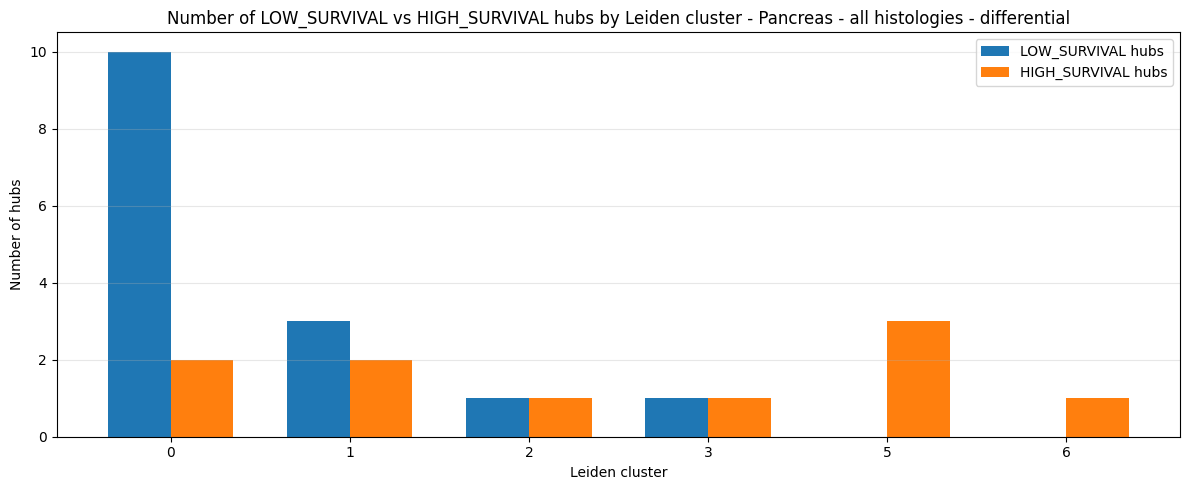

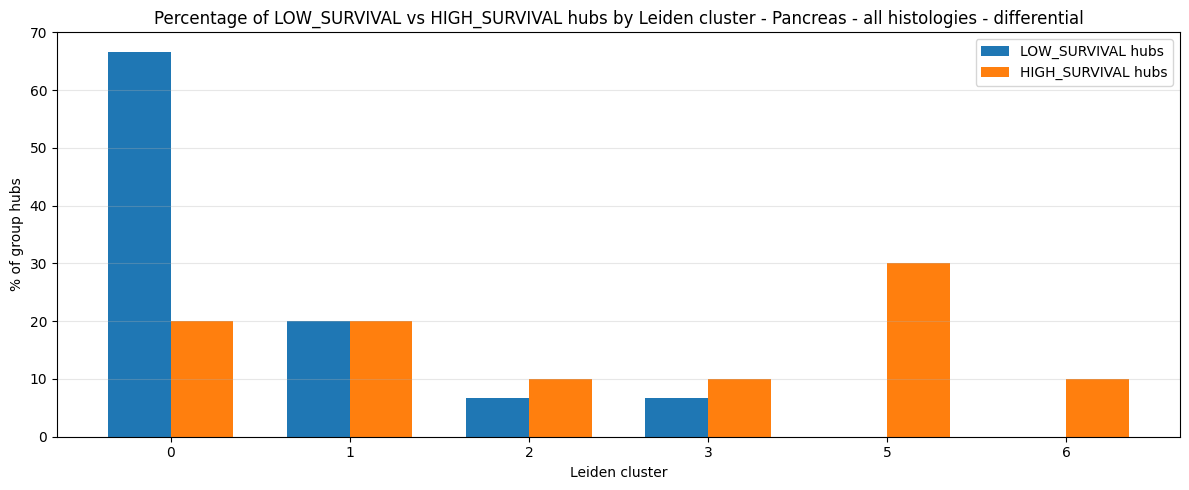


Saved long table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\readable_hub_counts_by_cluster\PANCREAS_ALL_differential_survival_hub_counts_by_cluster_long.csv

Saved wide readable table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\readable_hub_counts_by_cluster\PANCREAS_ALL_differential_survival_hub_counts_by_cluster_wide.csv

Saved focus table for clusters 1 and 2:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\readable_hub_counts_by_cluster\PANCREAS_ALL_differential_survival_hub_counts_clusters_1_2.csv

Nota finale:
La tabella conta gli hub LOW_SURVIVAL e HIGH_SURVIVAL nei cluster Leiden usando PANCREAS_ALL. L'istologia originale non viene usata per dividere i pazienti.


In [27]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# HUB COUNTS AND PERCENTAGES BY LEIDEN CLUSTER
# LOW_SURVIVAL vs HIGH_SURVIVAL
# PANCREAS_ALL
#
# Obiettivo:
# - contare quanti hub LOW_SURVIVAL e HIGH_SURVIVAL cadono in ogni cluster Leiden
# - calcolare le percentuali rispetto al totale degli hub del gruppo
# - calcolare le percentuali rispetto alla dimensione del cluster
#
# Nessuna separazione per istologia / ONCOTREE_CODE.
# ============================================================


# ============================================================
# 0. Parameters
# ============================================================

data_dir = Path("data_pancreas")

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

LOW_LABEL = "LOW_SURVIVAL"
HIGH_LABEL = "HIGH_SURVIVAL"

survival_groups = [
    LOW_LABEL,
    HIGH_LABEL
]

# Scegli quale analisi usare:
# "differential" = geni più rappresentativi LOW_SURVIVAL vs HIGH_SURVIVAL
# "separate" = top hub genes presi separatamente da LOW_SURVIVAL e HIGH_SURVIVAL
ANALYSIS_MODE = "differential"
# ANALYSIS_MODE = "separate"


base_dir = (
        data_dir
        / "clinical_to_network_median_pancreas_all"
)

mapping_dir = (
        base_dir
        / "hub_genes_cluster_mapping"
)

output_dir = (
        mapping_dir
        / "readable_hub_counts_by_cluster"
)

output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Helper functions
# ============================================================

def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def find_existing_file(candidate_paths, search_dir=None, patterns=None, description="file"):
    """
    Cerca un file in questo ordine:
    1. path candidati espliciti;
    2. ricerca automatica con glob nella cartella indicata.
    """

    print(f"\nSearching for {description}...")

    for path in candidate_paths:
        print("Candidate:", path)
        if path.exists():
            print("Found:", path)
            return path

    if search_dir is not None and search_dir.exists() and patterns is not None:
        print(f"\nTrying automatic search in: {search_dir}")

        matches = []

        for pattern in patterns:
            matches.extend(sorted(search_dir.glob(pattern)))

        unique_matches = []
        seen = set()

        for path in matches:
            if path not in seen:
                unique_matches.append(path)
                seen.add(path)

        if len(unique_matches) > 0:
            print("Found by automatic search:")
            for path in unique_matches:
                print(path)

            return unique_matches[0]

    print(f"\nNo {description} found.")
    return None


def load_leiden_clusters():
    """
    Carica i cluster Leiden per PANCREAS_ALL.
    Prima prova a usare la variabile clusters già in memoria.
    Altrimenti cerca il CSV salvato.
    """

    if "clusters" in globals():
        print("Uso clusters già presente in memoria.")
        clusters_df = globals()["clusters"].copy()
        return clusters_df, "memory: clusters"

    candidate_paths = [
        data_dir
        / "networks_by_pancreas_all"
        / "leiden_clusters"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_pancreas_all"
        / "leiden_clusters_by_pancreas_all"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_oncotree_groups"
        / "leiden_clusters_by_oncotree_groups"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_oncotree_groups"
        / "leiden_clusters_by_oncotree_groups"
        / "leiden_clusters_all_oncotree_groups.csv",

        data_dir
        / "leiden_clusters_PANCREAS_ALL.csv",
    ]

    patterns = [
        "**/leiden_clusters_PANCREAS_ALL.csv",
        "**/*PANCREAS_ALL*leiden*.csv",
        "**/leiden_clusters_all*.csv",
        "**/*leiden*clusters*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=data_dir,
        patterns=patterns,
        description="Leiden clusters for PANCREAS_ALL"
    )

    if found_path is None:
        raise FileNotFoundError(
            "Non trovo il file dei cluster Leiden per PANCREAS_ALL.\n"
            "Controlla dove hai salvato il file dei cluster della rete pancreas generale."
        )

    clusters_df = pd.read_csv(found_path, low_memory=False)
    return clusters_df, found_path


def load_mapped_hub_file():
    """
    Carica il file già prodotto dalla cella precedente:
    hub genes -> Leiden clusters.
    """

    if ANALYSIS_MODE == "differential":

        candidate_mapped_paths = [
            mapping_dir
            / f"{PANCREAS_GROUP}_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_differential_survival_hub_genes_mapped_to_leiden_clusters.csv",
        ]

        patterns = [
            f"*{PANCREAS_GROUP}*differential*low*high*survival*hub*genes*mapped*leiden*.csv",
            "*differential*survival*hub*genes*mapped*leiden*.csv",
            "*differential*low*high*survival*mapped*leiden*.csv",
        ]

    elif ANALYSIS_MODE == "separate":

        candidate_mapped_paths = [
            mapping_dir
            / f"{PANCREAS_GROUP}_separate_low_high_survival_top_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_separate_low_vs_high_survival_top_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_separate_survival_top_hub_genes_mapped_to_leiden_clusters.csv",
        ]

        patterns = [
            f"*{PANCREAS_GROUP}*separate*low*high*survival*top*hub*genes*mapped*leiden*.csv",
            "*separate*survival*top*hub*genes*mapped*leiden*.csv",
            "*separate*low*high*survival*mapped*leiden*.csv",
        ]

    else:
        raise ValueError("ANALYSIS_MODE deve essere 'differential' oppure 'separate'.")

    found_path = find_existing_file(
        candidate_paths=candidate_mapped_paths,
        search_dir=mapping_dir,
        patterns=patterns,
        description=f"{ANALYSIS_MODE} mapped hub genes for PANCREAS_ALL"
    )

    if found_path is None:
        print("Nessun file mapped trovato. Ho cercato questi path:")
        for path in candidate_mapped_paths:
            print(path)

        raise FileNotFoundError(
            "File di mapping hub genes -> Leiden clusters non trovato. "
            "Controlla il nome del file nella cartella hub_genes_cluster_mapping."
        )

    mapped_df = pd.read_csv(found_path, low_memory=False)
    return mapped_df, found_path


# ============================================================
# 2. Load files
# ============================================================

clusters, clusters_path = load_leiden_clusters()
mapped, mapped_path = load_mapped_hub_file()

clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()
mapped = mapped.loc[:, ~mapped.columns.duplicated()].copy()


# ============================================================
# 3. Normalize columns
# ============================================================

clusters = clusters.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree_Group": "ONCOTREE_CODE"
})

mapped = mapped.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "Oncotree_Group": "ONCOTREE_CODE",
    "SURVIVAL_GROUP": "survival_group",
    "Survival_Group": "survival_group"
})

required_cluster_cols = {
    "Gene",
    "Cluster"
}

missing_cluster_cols = required_cluster_cols - set(clusters.columns)

if missing_cluster_cols:
    raise ValueError(
        f"Colonne mancanti nel file clusters: {missing_cluster_cols}\n"
        f"Colonne disponibili: {clusters.columns.tolist()}"
    )

required_mapped_cols = {
    "Gene",
    "Cluster"
}

missing_mapped_cols = required_mapped_cols - set(mapped.columns)

if missing_mapped_cols:
    raise ValueError(
        f"Colonne mancanti nel file mapped: {missing_mapped_cols}\n"
        f"Colonne disponibili: {mapped.columns.tolist()}"
    )


# Se il file clusters contiene più gruppi, tengo PANCREAS_ALL se disponibile
if "ONCOTREE_CODE" in clusters.columns:
    clusters_pancreas = clusters[
        clusters["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
        ].copy()

    if not clusters_pancreas.empty:
        clusters = clusters_pancreas.copy()

# Se il file mapped contiene più gruppi, tengo PANCREAS_ALL se disponibile
if "ONCOTREE_CODE" in mapped.columns:
    mapped_pancreas = mapped[
        mapped["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
        ].copy()

    if not mapped_pancreas.empty:
        mapped = mapped_pancreas.copy()

clusters["Cluster"] = pd.to_numeric(clusters["Cluster"], errors="coerce")
mapped["Cluster"] = pd.to_numeric(mapped["Cluster"], errors="coerce")

clusters["Gene"] = clusters["Gene"].astype(str)
mapped["Gene"] = mapped["Gene"].astype(str)

print("Loaded clusters file:")
print(clusters_path)

print("\nLoaded mapped hub file:")
print(mapped_path)

print("\nClusters loaded:")
print("Rows:", clusters.shape[0])
print("Genes:", clusters["Gene"].nunique())
print("Clusters:", sorted(clusters["Cluster"].dropna().astype(int).unique()))

print("\nMapped hub genes loaded:")
print("Rows:", mapped.shape[0])
print("Genes:", mapped["Gene"].nunique())


# ============================================================
# 4. Identify hub group: LOW_SURVIVAL or HIGH_SURVIVAL
# ============================================================

def infer_hub_group(row):
    """
    Ricava se il gene appartiene al gruppo LOW_SURVIVAL oppure HIGH_SURVIVAL.

    Funziona con colonne come:
    - Signature_Group
    - Hub_List_Group
    - survival_group
    - Network_Group
    - Signature
    - Delta_HubScore_low_minus_high
    """

    text_parts = []

    possible_text_cols = [
        "Signature_Group",
        "Hub_List_Group",
        "survival_group",
        "Survival_Group",
        "Network_Group",
        "Group",
        "Signature",
        "signature_name",
        "Source_Group"
    ]

    for col in possible_text_cols:
        if col in row.index:
            text_parts.append(str(row[col]))

    text = " ".join(text_parts).lower()

    # LOW_SURVIVAL
    low_patterns = [
        "low_survival-enriched",
        "low survival enriched",
        "low_survival enriched",
        "top low_survival",
        "top low survival",
        "low_survival hub",
        "low survival hub",
        "low_survival network",
        "low survival network",
        "low_survival",
        "low survival"
    ]

    # HIGH_SURVIVAL
    high_patterns = [
        "high_survival-enriched",
        "high survival enriched",
        "high_survival enriched",
        "top high_survival",
        "top high survival",
        "high_survival hub",
        "high survival hub",
        "high_survival network",
        "high survival network",
        "high_survival",
        "high survival"
    ]

    has_low = any(pattern in text for pattern in low_patterns)
    has_high = any(pattern in text for pattern in high_patterns)

    if has_low and not has_high:
        return LOW_LABEL

    if has_high and not has_low:
        return HIGH_LABEL

    # Fallback per tabelle differential:
    # se è presente il delta, il segno indica il gruppo.
    delta_col = "Delta_HubScore_low_minus_high"

    if delta_col in row.index:
        delta_value = pd.to_numeric(row[delta_col], errors="coerce")

        if pd.notna(delta_value):
            if delta_value > 0:
                return LOW_LABEL
            elif delta_value < 0:
                return HIGH_LABEL

    return np.nan


mapped["Hub_Group"] = mapped.apply(infer_hub_group, axis=1)

mapped = mapped.dropna(
    subset=["Gene", "Hub_Group"]
).copy()

# Tengo solo geni effettivamente trovati nei cluster Leiden
mapped_in_clusters = mapped.dropna(subset=["Cluster"]).copy()
mapped_in_clusters["Cluster"] = mapped_in_clusters["Cluster"].astype(int)


# ============================================================
# 5. Cluster size
# ============================================================

cluster_sizes = (
    clusters
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)


# ============================================================
# 6. Count hubs by survival group and cluster
# ============================================================

# Totale hub per gruppo, considerando solo quelli mappati nei cluster
total_hubs_by_group = (
    mapped_in_clusters
    .groupby("Hub_Group")
    .agg(
        total_hubs_group=("Gene", "nunique")
    )
    .reset_index()
)

hub_counts_long = (
    mapped_in_clusters
    .groupby(["Hub_Group", "Cluster"])
    .agg(
        n_hubs=("Gene", "nunique"),
        genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique())))
    )
    .reset_index()
)

hub_counts_long = hub_counts_long.merge(
    total_hubs_by_group,
    on="Hub_Group",
    how="left"
)

hub_counts_long = hub_counts_long.merge(
    cluster_sizes,
    on="Cluster",
    how="left"
)

# Percentuale rispetto al totale degli hub del gruppo
# Esempio: quanti hub LOW_SURVIVAL cadono nel cluster 1 rispetto a tutti gli hub LOW_SURVIVAL?
hub_counts_long["pct_of_group_hubs"] = np.where(
    hub_counts_long["total_hubs_group"] > 0,
    hub_counts_long["n_hubs"] / hub_counts_long["total_hubs_group"] * 100,
    0
).round(2)

# Percentuale rispetto alla dimensione del cluster
# Esempio: quanti geni del cluster 1 sono hub LOW_SURVIVAL?
hub_counts_long["pct_of_cluster_genes"] = np.where(
    hub_counts_long["cluster_size_genes"] > 0,
    hub_counts_long["n_hubs"] / hub_counts_long["cluster_size_genes"] * 100,
    0
).round(2)

hub_counts_long = hub_counts_long.sort_values(
    ["Cluster", "Hub_Group"]
).reset_index(drop=True)


# ============================================================
# 7. Wide table: easier to read LOW_SURVIVAL vs HIGH_SURVIVAL
# ============================================================

all_clusters = sorted(clusters["Cluster"].dropna().astype(int).unique())

all_combinations = pd.MultiIndex.from_product(
    [survival_groups, all_clusters],
    names=["Hub_Group", "Cluster"]
).to_frame(index=False)

hub_counts_complete = all_combinations.merge(
    hub_counts_long,
    on=["Hub_Group", "Cluster"],
    how="left"
)

hub_counts_complete = hub_counts_complete.merge(
    cluster_sizes,
    on="Cluster",
    how="left",
    suffixes=("", "_from_clusters")
)

hub_counts_complete["cluster_size_genes"] = (
    hub_counts_complete["cluster_size_genes"]
    .fillna(hub_counts_complete["cluster_size_genes_from_clusters"])
)

hub_counts_complete = hub_counts_complete.drop(
    columns=["cluster_size_genes_from_clusters"],
    errors="ignore"
)

hub_counts_complete["n_hubs"] = hub_counts_complete["n_hubs"].fillna(0).astype(int)
hub_counts_complete["genes"] = hub_counts_complete["genes"].fillna("-")

# Riaggiungo i totali per calcolare percentuali anche dove n_hubs = 0
hub_counts_complete = hub_counts_complete.drop(
    columns=["total_hubs_group"],
    errors="ignore"
).merge(
    total_hubs_by_group,
    on="Hub_Group",
    how="left"
)

hub_counts_complete["total_hubs_group"] = (
    hub_counts_complete["total_hubs_group"]
    .fillna(0)
)

hub_counts_complete["pct_of_group_hubs"] = np.where(
    hub_counts_complete["total_hubs_group"] > 0,
    hub_counts_complete["n_hubs"] / hub_counts_complete["total_hubs_group"] * 100,
    0
).round(2)

hub_counts_complete["pct_of_cluster_genes"] = np.where(
    hub_counts_complete["cluster_size_genes"] > 0,
    hub_counts_complete["n_hubs"] / hub_counts_complete["cluster_size_genes"] * 100,
    0
).round(2)


# ============================================================
# 8. Build wide table with clean column names
# ============================================================

group_prefix = {
    LOW_LABEL: "Low_Survival",
    HIGH_LABEL: "High_Survival"
}

wide_parts = []

for group in survival_groups:

    prefix = group_prefix[group]

    tmp = hub_counts_complete[
        hub_counts_complete["Hub_Group"] == group
        ][
        [
            "Cluster",
            "n_hubs",
            "pct_of_group_hubs",
            "pct_of_cluster_genes",
            "genes"
        ]
    ].copy()

    tmp = tmp.rename(columns={
        "n_hubs": f"{prefix}_n_hubs",
        "pct_of_group_hubs": f"{prefix}_pct_of_group_hubs",
        "pct_of_cluster_genes": f"{prefix}_pct_of_cluster_genes",
        "genes": f"{prefix}_genes"
    })

    wide_parts.append(tmp)

hub_counts_wide = cluster_sizes.copy()

for tmp in wide_parts:
    hub_counts_wide = hub_counts_wide.merge(
        tmp,
        on="Cluster",
        how="left"
    )

hub_counts_wide = hub_counts_wide.fillna({
    "Low_Survival_n_hubs": 0,
    "Low_Survival_pct_of_group_hubs": 0,
    "Low_Survival_pct_of_cluster_genes": 0,
    "Low_Survival_genes": "-",
    "High_Survival_n_hubs": 0,
    "High_Survival_pct_of_group_hubs": 0,
    "High_Survival_pct_of_cluster_genes": 0,
    "High_Survival_genes": "-"
})

hub_counts_wide["Low_Survival_n_hubs"] = (
    hub_counts_wide["Low_Survival_n_hubs"]
    .astype(int)
)

hub_counts_wide["High_Survival_n_hubs"] = (
    hub_counts_wide["High_Survival_n_hubs"]
    .astype(int)
)

hub_counts_wide["Delta_n_hubs_Low_minus_High"] = (
        hub_counts_wide["Low_Survival_n_hubs"]
        - hub_counts_wide["High_Survival_n_hubs"]
)

hub_counts_wide["Delta_pct_group_Low_minus_High"] = (
        hub_counts_wide["Low_Survival_pct_of_group_hubs"]
        - hub_counts_wide["High_Survival_pct_of_group_hubs"]
).round(2)

hub_counts_wide = hub_counts_wide.sort_values("Cluster").reset_index(drop=True)


# ============================================================
# 9. Focus on prognostic clusters 1 and 2
# ============================================================

clusters_of_interest = [1, 2]

hub_counts_focus = hub_counts_wide[
    hub_counts_wide["Cluster"].isin(clusters_of_interest)
].copy()


# ============================================================
# 10. Display results
# ============================================================

pd.set_option("display.max_colwidth", 200)

display_cols = [
    "Cluster",
    "cluster_size_genes",
    "Low_Survival_n_hubs",
    "Low_Survival_pct_of_group_hubs",
    "High_Survival_n_hubs",
    "High_Survival_pct_of_group_hubs",
    "Delta_n_hubs_Low_minus_High",
    "Delta_pct_group_Low_minus_High",
    "Low_Survival_genes",
    "High_Survival_genes"
]

print("\n" + "=" * 120)
print(f"HUB COUNTS BY CLUSTER - {ANALYSIS_MODE.upper()} HUB LIST - {PANCREAS_GROUP}")
print("=" * 120)

safe_display(hub_counts_wide[display_cols])

print("\n" + "=" * 120)
print("FOCUS ON PROGNOSTIC CLUSTERS 1 AND 2")
print("=" * 120)

safe_display(hub_counts_focus[display_cols])


# ============================================================
# 11. Plot: number of hubs by cluster
# ============================================================
# Questo grafico resta GENERALE, quindi mostra tutti i cluster.

plot_df = hub_counts_wide[
    [
        "Cluster",
        "Low_Survival_n_hubs",
        "High_Survival_n_hubs"
    ]
].copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_df["Low_Survival_n_hubs"],
    width,
    label="LOW_SURVIVAL hubs"
)

plt.bar(
    x + width / 2,
    plot_df["High_Survival_n_hubs"],
    width,
    label="HIGH_SURVIVAL hubs"
)

plt.xticks(x, plot_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("Number of hubs")
plt.title(
    f"Number of LOW_SURVIVAL vs HIGH_SURVIVAL hubs "
    f"by Leiden cluster - {PANCREAS_LABEL} - {ANALYSIS_MODE}"
)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 12. Plot: percentage of group hubs by cluster
# ============================================================
# Anche questo grafico resta GENERALE, quindi mostra tutti i cluster.

plot_pct_df = hub_counts_wide[
    [
        "Cluster",
        "Low_Survival_pct_of_group_hubs",
        "High_Survival_pct_of_group_hubs"
    ]
].copy()

x = np.arange(len(plot_pct_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_pct_df["Low_Survival_pct_of_group_hubs"],
    width,
    label="LOW_SURVIVAL hubs"
)

plt.bar(
    x + width / 2,
    plot_pct_df["High_Survival_pct_of_group_hubs"],
    width,
    label="HIGH_SURVIVAL hubs"
)

plt.xticks(x, plot_pct_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("% of group hubs")
plt.title(
    f"Percentage of LOW_SURVIVAL vs HIGH_SURVIVAL hubs "
    f"by Leiden cluster - {PANCREAS_LABEL} - {ANALYSIS_MODE}"
)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 13. Save outputs
# ============================================================

long_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_survival_hub_counts_by_cluster_long.csv"
)

wide_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_survival_hub_counts_by_cluster_wide.csv"
)

focus_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_survival_hub_counts_clusters_1_2.csv"
)

hub_counts_long.to_csv(long_output, index=False)
hub_counts_wide.to_csv(wide_output, index=False)
hub_counts_focus.to_csv(focus_output, index=False)

print("\nSaved long table:")
print(long_output)

print("\nSaved wide readable table:")
print(wide_output)

print("\nSaved focus table for clusters 1 and 2:")
print(focus_output)


# ============================================================
# 14. Compatibility aliases
# ============================================================

hub_counts_long_pancreas_survival = hub_counts_long
hub_counts_wide_pancreas_survival = hub_counts_wide
hub_counts_focus_pancreas_survival = hub_counts_focus

print("\nNota finale:")
print(
    "La tabella conta gli hub LOW_SURVIVAL e HIGH_SURVIVAL nei cluster Leiden "
    "usando PANCREAS_ALL. L'istologia originale non viene usata per dividere i pazienti."
)

Uso clusters già presente in memoria.

Searching for differential survival mapped hub genes for PANCREAS_ALL...
Candidate: data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv
Found: data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv

Loaded clusters:
memory: clusters

Loaded mapped hub file:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\PANCREAS_ALL_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv

Clusters loaded:
Rows: 40
Genes: 40
Clusters: [0, 1, 2, 3, 5, 6]

Mapped hub genes loaded:
Rows: 40
Genes: 40

WEIGHTED HUB DISTRIBUTION BY CLUSTER - PANCREAS_ALL - DIFFERENTIAL - RANK_INVERSE


,Cluster,cluster_size_genes,Low_Survival_n_hubs,Low_Survival_weighted_pct,High_Survival_n_hubs,High_Survival_weighted_pct,Delta_weighted_pct_Low_minus_High,Low_Survival_best_rank,High_Survival_best_rank,Low_Survival_genes,High_Survival_genes
0,0,13,10,80.77,2,21.34,59.43,1.0,2.0,"ATM, BAP1, BRCA2, CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B, MTAP, PTPRD, TEK","CDK6, FLT4"
1,1,6,3,9.85,2,39.83,-29.98,6.0,1.0,"AKT2, CCNE1, CEBPA","KMT2B, TP53"
2,2,4,1,3.35,1,8.54,-5.19,9.0,4.0,KDM6A,ARID1A
3,3,4,1,6.03,1,6.83,-0.80,5.0,5.0,SMAD4,PREX2
4,5,4,0,0.00,3,19.67,-19.67,NaN,3.0,-,"AGO2, MYC, RECQL4"
5,6,2,0,0.00,1,3.79,-3.79,NaN,9.0,-,CDK4



FOCUS ON PROGNOSTIC CLUSTERS 1 AND 2


,Cluster,cluster_size_genes,Low_Survival_n_hubs,Low_Survival_weighted_pct,High_Survival_n_hubs,High_Survival_weighted_pct,Delta_weighted_pct_Low_minus_High,Low_Survival_best_rank,High_Survival_best_rank,Low_Survival_genes,High_Survival_genes
1,1,6,3,9.85,2,39.83,-29.98,6.0,1.0,"AKT2, CCNE1, CEBPA","KMT2B, TP53"
2,2,4,1,3.35,1,8.54,-5.19,9.0,4.0,KDM6A,ARID1A



WEIGHTED GENE DETAIL - CLUSTERS 1 AND 2


,Hub_Group,Gene,Cluster,HubScore_for_weight,Hub_rank_in_group,raw_weight,normalized_weight,Signature_Group,Delta_HubScore_low_minus_high,Abs_Delta_HubScore,HubScore_low_survival,HubScore_high_survival,Degree_low_survival,Degree_high_survival,Node_Strength_low_survival,Node_Strength_high_survival
0,HIGH_SURVIVAL,TP53,1,0.812500,1,1.000000,34.1417,HIGH_SURVIVAL-enriched hub genes,-0.481250,0.481250,0.33125,0.812500,2.0,5.0,5.921908,13.827804
3,HIGH_SURVIVAL,ARID1A,2,0.684524,4,0.250000,8.5354,HIGH_SURVIVAL-enriched hub genes,-0.484524,0.484524,0.20000,0.684524,1.0,4.0,1.013655,8.703719
5,HIGH_SURVIVAL,KMT2B,1,0.556548,6,0.166667,5.6903,HIGH_SURVIVAL-enriched hub genes,-0.556548,0.556548,NaN,0.556548,NaN,2.0,NaN,8.392674
15,LOW_SURVIVAL,AKT2,1,0.706250,6,0.166667,5.0228,LOW_SURVIVAL-enriched hub genes,0.233036,0.233036,0.70625,0.473214,4.0,2.0,15.215952,10.206393
18,LOW_SURVIVAL,KDM6A,2,0.500000,9,0.111111,3.3485,LOW_SURVIVAL-enriched hub genes,0.211310,0.211310,0.50000,0.288690,3.0,1.0,4.294483,2.079392
21,LOW_SURVIVAL,CEBPA,1,0.350000,12,0.083333,2.5114,LOW_SURVIVAL-enriched hub genes,0.350000,0.350000,0.35000,NaN,2.0,NaN,12.195506,NaN
22,LOW_SURVIVAL,CCNE1,1,0.337500,13,0.076923,2.3182,LOW_SURVIVAL-enriched hub genes,0.093452,0.093452,0.33750,0.244048,2.0,1.0,11.492536,4.834525


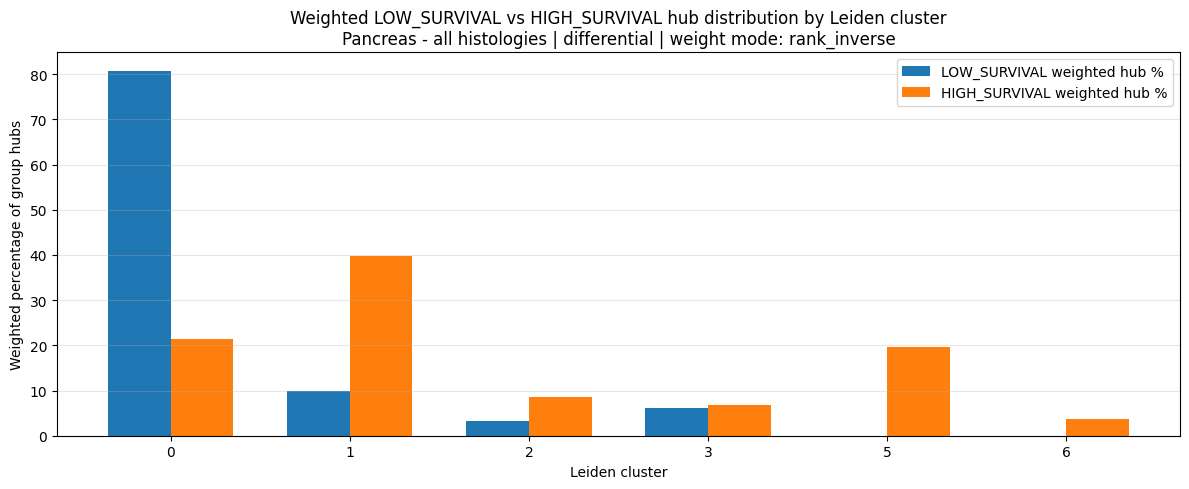

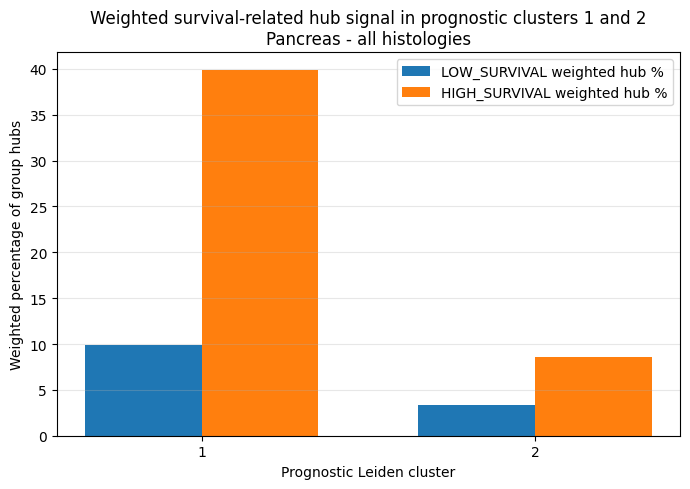


Saved weighted long table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\PANCREAS_ALL_differential_rank_inverse_survival_weighted_hub_distribution_long.csv

Saved weighted wide table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\PANCREAS_ALL_differential_rank_inverse_survival_weighted_hub_distribution_wide.csv

Saved weighted focus table for clusters 1 and 2:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\PANCREAS_ALL_differential_rank_inverse_survival_weighted_hub_distribution_clusters_1_2.csv

Saved weighted gene detail:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\PANCREAS_ALL_differential_rank_inverse_survival_weighted_gene_detail.csv

Saved weighted gene detail for clusters 1 and 2:
data_pancreas\cli

In [28]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# WEIGHTED HUB DISTRIBUTION BY LEIDEN CLUSTER
# LOW_SURVIVAL vs HIGH_SURVIVAL
# PANCREAS_ALL
#
# Idea:
# - non conto solo quanti hub cadono in ogni cluster
# - do più peso agli hub più importanti
# - il peso diminuisce man mano che l'HubScore/rank peggiora
#
# Nessuna separazione per istologia / ONCOTREE_CODE.
# ============================================================


# ============================================================
# 0. Settings
# ============================================================

data_dir = Path("data_pancreas")

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

LOW_LABEL = "LOW_SURVIVAL"
HIGH_LABEL = "HIGH_SURVIVAL"

SURVIVAL_GROUPS = [
    LOW_LABEL,
    HIGH_LABEL
]

# Scegli quale lista usare:
# "differential" = geni più rappresentativi LOW_SURVIVAL vs HIGH_SURVIVAL
# "separate" = top hub presi separatamente da LOW_SURVIVAL e HIGH_SURVIVAL
ANALYSIS_MODE = "differential"
# ANALYSIS_MODE = "separate"

# Tipo di peso:
# "hubscore" = usa direttamente HubScore normalizzato
# "rank_inverse" = peso = 1 / rank, quindi il primo pesa molto più degli ultimi
# "rank_linear" = peso decresce linearmente dal primo all'ultimo
WEIGHT_MODE = "rank_inverse"
# WEIGHT_MODE = "hubscore"
# WEIGHT_MODE = "rank_linear"

survival_base_dir = (
        data_dir
        / "clinical_to_network_median_pancreas_all"
)

mapping_dir = (
        survival_base_dir
        / "hub_genes_cluster_mapping"
)

output_dir = (
        mapping_dir
        / "weighted_hub_distribution_by_cluster"
)

output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# Helper functions
# ============================================================

def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def find_existing_file(candidate_paths, search_dir=None, patterns=None, description="file"):
    print(f"\nSearching for {description}...")

    for path in candidate_paths:
        print("Candidate:", path)
        if path.exists():
            print("Found:", path)
            return path

    if search_dir is not None and search_dir.exists() and patterns is not None:
        print(f"\nTrying automatic search in: {search_dir}")

        matches = []

        for pattern in patterns:
            matches.extend(sorted(search_dir.glob(pattern)))

        unique_matches = []
        seen = set()

        for path in matches:
            if path not in seen:
                unique_matches.append(path)
                seen.add(path)

        if len(unique_matches) > 0:
            print("Found by automatic search:")
            for path in unique_matches:
                print(path)

            return unique_matches[0]

    print(f"\nNo {description} found.")
    return None


def load_leiden_clusters():
    """
    Carica i cluster Leiden per PANCREAS_ALL.
    Prima prova a usare la variabile clusters già in memoria.
    Altrimenti cerca automaticamente il CSV salvato.
    """

    if "clusters" in globals():
        print("Uso clusters già presente in memoria.")
        clusters_df = globals()["clusters"].copy()
        return clusters_df, "memory: clusters"

    candidate_paths = [
        data_dir
        / "networks_by_pancreas_all"
        / "leiden_clusters"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_pancreas_all"
        / "leiden_clusters_by_pancreas_all"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_oncotree_groups"
        / "leiden_clusters_by_oncotree_groups"
        / "leiden_clusters_PANCREAS_ALL.csv",

        data_dir
        / "networks_by_oncotree_groups"
        / "leiden_clusters_by_oncotree_groups"
        / "leiden_clusters_all_oncotree_groups.csv",

        data_dir
        / "leiden_clusters_PANCREAS_ALL.csv",
    ]

    patterns = [
        "**/leiden_clusters_PANCREAS_ALL.csv",
        "**/*PANCREAS_ALL*leiden*.csv",
        "**/leiden_clusters_all*.csv",
        "**/*leiden*clusters*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=data_dir,
        patterns=patterns,
        description="Leiden clusters for PANCREAS_ALL"
    )

    if found_path is None:
        raise FileNotFoundError(
            "Non trovo il file dei cluster Leiden per PANCREAS_ALL.\n"
            "Controlla dove hai salvato il file dei cluster della rete pancreas generale."
        )

    clusters_df = pd.read_csv(found_path, low_memory=False)
    return clusters_df, found_path


def load_mapped_hub_file():
    """
    Carica il file mapped hub genes -> Leiden clusters
    prodotto dalla cella precedente.
    """

    if ANALYSIS_MODE == "differential":

        candidate_mapped_paths = [
            mapping_dir
            / f"{PANCREAS_GROUP}_differential_low_vs_high_survival_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_differential_survival_hub_genes_mapped_to_leiden_clusters.csv",
        ]

        mapped_patterns = [
            f"*{PANCREAS_GROUP}*differential*low*high*survival*hub_genes_mapped_to_leiden_clusters.csv",
            f"*{PANCREAS_GROUP}*differential*survival*hub_genes_mapped_to_leiden_clusters.csv",
            "*differential*survival*hub_genes_mapped_to_leiden_clusters.csv",
            "*differential*low*high*survival*clusters*.csv",
            "*differential*survival*clusters*.csv",
        ]

    elif ANALYSIS_MODE == "separate":

        candidate_mapped_paths = [
            mapping_dir
            / f"{PANCREAS_GROUP}_separate_low_high_survival_top_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_separate_low_vs_high_survival_top_hub_genes_mapped_to_leiden_clusters.csv",

            mapping_dir
            / f"{PANCREAS_GROUP}_separate_survival_top_hub_genes_mapped_to_leiden_clusters.csv",
        ]

        mapped_patterns = [
            f"*{PANCREAS_GROUP}*separate*low*high*survival*top_hub_genes_mapped_to_leiden_clusters.csv",
            f"*{PANCREAS_GROUP}*separate*survival*top_hub_genes_mapped_to_leiden_clusters.csv",
            "*separate*survival*top_hub_genes_mapped_to_leiden_clusters.csv",
            "*separate*low*high*survival*clusters*.csv",
            "*separate*survival*clusters*.csv",
        ]

    else:
        raise ValueError("ANALYSIS_MODE deve essere 'differential' oppure 'separate'.")

    mapped_path = find_existing_file(
        candidate_paths=candidate_mapped_paths,
        search_dir=mapping_dir,
        patterns=mapped_patterns,
        description=f"{ANALYSIS_MODE} survival mapped hub genes for PANCREAS_ALL"
    )

    if mapped_path is None:
        raise FileNotFoundError(
            "Non trovo il file mapped hub genes -> Leiden clusters per survival.\n"
            "Prima devi eseguire la cella che mappa gli hub survival sui cluster Leiden.\n"
            f"Cartella cercata:\n{mapping_dir}"
        )

    mapped_df = pd.read_csv(mapped_path, low_memory=False)

    return mapped_df, mapped_path


# ============================================================
# 1. Load files
# ============================================================

clusters, clusters_path = load_leiden_clusters()
mapped, mapped_path = load_mapped_hub_file()

clusters = clusters.loc[:, ~clusters.columns.duplicated()].copy()
mapped = mapped.loc[:, ~mapped.columns.duplicated()].copy()


# ============================================================
# 2. Normalize columns
# ============================================================

clusters = clusters.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "ONCOTREE_CODE": "ONCOTREE_CODE",
    "Oncotree_Group": "ONCOTREE_CODE"
})

mapped = mapped.rename(columns={
    "Hugo_Symbol": "Gene",
    "gene": "Gene",
    "GENE": "Gene",
    "cluster": "Cluster",
    "Leiden_Cluster": "Cluster",
    "leiden_cluster": "Cluster",
    "Oncotree_Group": "ONCOTREE_CODE",
    "SURVIVAL_GROUP": "survival_group",
    "Survival_Group": "survival_group"
})

required_cluster_cols = {
    "Gene",
    "Cluster"
}

missing_cluster_cols = required_cluster_cols - set(clusters.columns)

if missing_cluster_cols:
    raise ValueError(
        f"Colonne mancanti nel file clusters: {missing_cluster_cols}\n"
        f"Colonne disponibili: {clusters.columns.tolist()}"
    )

required_mapped_cols = {
    "Gene",
    "Cluster"
}

missing_mapped_cols = required_mapped_cols - set(mapped.columns)

if missing_mapped_cols:
    raise ValueError(
        f"Colonne mancanti nel file mapped: {missing_mapped_cols}\n"
        f"Colonne disponibili: {mapped.columns.tolist()}"
    )


# Se il file clusters contiene più gruppi, tengo PANCREAS_ALL se disponibile
if "ONCOTREE_CODE" in clusters.columns:
    clusters_pancreas = clusters[
        clusters["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
        ].copy()

    if not clusters_pancreas.empty:
        clusters = clusters_pancreas.copy()

# Se il file mapped contiene più gruppi, tengo PANCREAS_ALL se disponibile
if "ONCOTREE_CODE" in mapped.columns:
    mapped_pancreas = mapped[
        mapped["ONCOTREE_CODE"].astype(str) == PANCREAS_GROUP
        ].copy()

    if not mapped_pancreas.empty:
        mapped = mapped_pancreas.copy()


clusters["Cluster"] = pd.to_numeric(clusters["Cluster"], errors="coerce")
mapped["Cluster"] = pd.to_numeric(mapped["Cluster"], errors="coerce")

clusters["Gene"] = clusters["Gene"].astype(str)
mapped["Gene"] = mapped["Gene"].astype(str)

print("\nLoaded clusters:")
print(clusters_path)

print("\nLoaded mapped hub file:")
print(mapped_path)

print("\nClusters loaded:")
print("Rows:", clusters.shape[0])
print("Genes:", clusters["Gene"].nunique())
print("Clusters:", sorted(clusters["Cluster"].dropna().astype(int).unique()))

print("\nMapped hub genes loaded:")
print("Rows:", mapped.shape[0])
print("Genes:", mapped["Gene"].nunique())


# ============================================================
# 3. Identify LOW_SURVIVAL / HIGH_SURVIVAL group
# ============================================================

def infer_hub_group(row):
    """
    Ricava se il gene appartiene al gruppo LOW_SURVIVAL oppure HIGH_SURVIVAL.
    Funziona sia per:
    - differential mapped table
    - separate top hub mapped table
    """

    text_parts = []

    possible_text_cols = [
        "Signature_Group",
        "Hub_List_Group",
        "survival_group",
        "Survival_Group",
        "Network_Group",
        "Group",
        "Signature",
        "signature_name",
        "Source_Group"
    ]

    for col in possible_text_cols:
        if col in row.index:
            text_parts.append(str(row[col]))

    text = " ".join(text_parts).lower()

    low_patterns = [
        "low_survival-enriched",
        "low survival enriched",
        "low_survival enriched",
        "top low_survival",
        "top low survival",
        "low_survival hub",
        "low survival hub",
        "low_survival network",
        "low survival network",
        "low_survival",
        "low survival"
    ]

    high_patterns = [
        "high_survival-enriched",
        "high survival enriched",
        "high_survival enriched",
        "top high_survival",
        "top high survival",
        "high_survival hub",
        "high survival hub",
        "high_survival network",
        "high survival network",
        "high_survival",
        "high survival"
    ]

    has_low = any(pattern in text for pattern in low_patterns)
    has_high = any(pattern in text for pattern in high_patterns)

    if has_low and not has_high:
        return LOW_LABEL

    if has_high and not has_low:
        return HIGH_LABEL

    # Fallback per tabelle differential:
    # se è presente il delta, uso il segno del delta
    delta_col = "Delta_HubScore_low_minus_high"

    if delta_col in row.index:
        delta_value = pd.to_numeric(row[delta_col], errors="coerce")

        if pd.notna(delta_value):
            if delta_value > 0:
                return LOW_LABEL
            elif delta_value < 0:
                return HIGH_LABEL

    return np.nan


mapped["Hub_Group"] = mapped.apply(infer_hub_group, axis=1)

mapped = mapped.dropna(
    subset=["Gene", "Hub_Group", "Cluster"]
).copy()

mapped["Cluster"] = mapped["Cluster"].astype(int)


# ============================================================
# 4. Select correct HubScore for each row
# ============================================================

def get_group_hubscore(row):
    """
    Per differential:
    - LOW_SURVIVAL usa HubScore_low_survival
    - HIGH_SURVIVAL usa HubScore_high_survival

    Per separate:
    - usa HubScore
    """

    group = row["Hub_Group"]

    if group == LOW_LABEL:
        if "HubScore_low_survival" in row.index and pd.notna(row["HubScore_low_survival"]):
            return row["HubScore_low_survival"]

    if group == HIGH_LABEL:
        if "HubScore_high_survival" in row.index and pd.notna(row["HubScore_high_survival"]):
            return row["HubScore_high_survival"]

    if "HubScore" in row.index and pd.notna(row["HubScore"]):
        return row["HubScore"]

    if "Abs_Delta_HubScore" in row.index and pd.notna(row["Abs_Delta_HubScore"]):
        return row["Abs_Delta_HubScore"]

    return np.nan


mapped["HubScore_for_weight"] = mapped.apply(get_group_hubscore, axis=1)

mapped["HubScore_for_weight"] = pd.to_numeric(
    mapped["HubScore_for_weight"],
    errors="coerce"
)

mapped = mapped.dropna(
    subset=["HubScore_for_weight"]
).copy()

if mapped.empty:
    raise ValueError(
        "Dopo il filtro HubScore_for_weight, la tabella mapped è vuota. "
        "Controlla che il file mapped contenga HubScore_low_survival / "
        "HubScore_high_survival oppure HubScore."
    )


# ============================================================
# 5. Rank hubs within each group and assign weight
# ============================================================

mapped = mapped.sort_values(
    ["Hub_Group", "HubScore_for_weight"],
    ascending=[True, False]
).copy()

mapped["Hub_rank_in_group"] = (
    mapped
    .groupby("Hub_Group")["HubScore_for_weight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

mapped["n_hubs_in_group"] = (
    mapped
    .groupby("Hub_Group")["Gene"]
    .transform("nunique")
)


def assign_weight(row):
    rank = row["Hub_rank_in_group"]
    n = row["n_hubs_in_group"]
    hubscore = row["HubScore_for_weight"]

    if WEIGHT_MODE == "hubscore":
        return hubscore

    if WEIGHT_MODE == "rank_inverse":
        return 1 / rank

    if WEIGHT_MODE == "rank_linear":
        if n <= 1:
            return 1
        return (n - rank + 1) / n

    raise ValueError("WEIGHT_MODE non valido.")


mapped["raw_weight"] = mapped.apply(assign_weight, axis=1)

# Normalizzo i pesi dentro ciascun gruppo:
# la somma dei pesi LOW_SURVIVAL = 100
# la somma dei pesi HIGH_SURVIVAL = 100
mapped["normalized_weight"] = (
        mapped["raw_weight"]
        / mapped.groupby("Hub_Group")["raw_weight"].transform("sum")
        * 100
)

mapped["normalized_weight"] = mapped["normalized_weight"].round(4)


# ============================================================
# 6. Cluster sizes
# ============================================================

cluster_sizes = (
    clusters
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)


# ============================================================
# 7. Weighted summary by group and cluster
# ============================================================

weighted_long = (
    mapped
    .groupby(["Hub_Group", "Cluster"])
    .agg(
        n_hubs=("Gene", "nunique"),
        weighted_hub_score=("normalized_weight", "sum"),
        mean_hubscore=("HubScore_for_weight", "mean"),
        max_hubscore=("HubScore_for_weight", "max"),
        best_rank=("Hub_rank_in_group", "min"),
        genes=(
            "Gene",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
)

weighted_long["weighted_hub_score"] = weighted_long["weighted_hub_score"].round(2)
weighted_long["mean_hubscore"] = weighted_long["mean_hubscore"].round(4)
weighted_long["max_hubscore"] = weighted_long["max_hubscore"].round(4)

weighted_long = weighted_long.merge(
    cluster_sizes,
    on="Cluster",
    how="left"
)

weighted_long["pct_cluster_covered_by_hubs"] = np.where(
    weighted_long["cluster_size_genes"] > 0,
    weighted_long["n_hubs"] / weighted_long["cluster_size_genes"] * 100,
    0
).round(2)

weighted_long = weighted_long.sort_values(
    ["Hub_Group", "weighted_hub_score"],
    ascending=[True, False]
).reset_index(drop=True)


# ============================================================
# 8. Wide readable table
# ============================================================

all_clusters = sorted(clusters["Cluster"].dropna().astype(int).unique())

all_combinations = pd.MultiIndex.from_product(
    [SURVIVAL_GROUPS, all_clusters],
    names=["Hub_Group", "Cluster"]
).to_frame(index=False)

weighted_complete = all_combinations.merge(
    weighted_long,
    on=["Hub_Group", "Cluster"],
    how="left"
)

weighted_complete = weighted_complete.merge(
    cluster_sizes,
    on="Cluster",
    how="left",
    suffixes=("", "_from_clusters")
)

weighted_complete["cluster_size_genes"] = (
    weighted_complete["cluster_size_genes"]
    .fillna(weighted_complete["cluster_size_genes_from_clusters"])
)

weighted_complete = weighted_complete.drop(
    columns=["cluster_size_genes_from_clusters"],
    errors="ignore"
)

fill_zero_cols = [
    "n_hubs",
    "weighted_hub_score",
    "mean_hubscore",
    "max_hubscore",
    "pct_cluster_covered_by_hubs"
]

for col in fill_zero_cols:
    if col in weighted_complete.columns:
        weighted_complete[col] = weighted_complete[col].fillna(0)

weighted_complete["best_rank"] = weighted_complete["best_rank"].fillna(np.nan)
weighted_complete["genes"] = weighted_complete["genes"].fillna("-")


group_prefix = {
    LOW_LABEL: "Low_Survival",
    HIGH_LABEL: "High_Survival"
}

wide_parts = []

for group in SURVIVAL_GROUPS:

    prefix = group_prefix[group]

    tmp = weighted_complete[
        weighted_complete["Hub_Group"] == group
        ][
        [
            "Cluster",
            "n_hubs",
            "weighted_hub_score",
            "mean_hubscore",
            "max_hubscore",
            "best_rank",
            "pct_cluster_covered_by_hubs",
            "genes"
        ]
    ].copy()

    tmp = tmp.rename(columns={
        "n_hubs": f"{prefix}_n_hubs",
        "weighted_hub_score": f"{prefix}_weighted_pct",
        "mean_hubscore": f"{prefix}_mean_hubscore",
        "max_hubscore": f"{prefix}_max_hubscore",
        "best_rank": f"{prefix}_best_rank",
        "pct_cluster_covered_by_hubs": f"{prefix}_pct_cluster_covered",
        "genes": f"{prefix}_genes"
    })

    wide_parts.append(tmp)

weighted_wide = cluster_sizes.copy()

for tmp in wide_parts:
    weighted_wide = weighted_wide.merge(
        tmp,
        on="Cluster",
        how="left"
    )

weighted_wide = weighted_wide.fillna({
    "Low_Survival_n_hubs": 0,
    "Low_Survival_weighted_pct": 0,
    "Low_Survival_mean_hubscore": 0,
    "Low_Survival_max_hubscore": 0,
    "Low_Survival_pct_cluster_covered": 0,
    "Low_Survival_genes": "-",
    "High_Survival_n_hubs": 0,
    "High_Survival_weighted_pct": 0,
    "High_Survival_mean_hubscore": 0,
    "High_Survival_max_hubscore": 0,
    "High_Survival_pct_cluster_covered": 0,
    "High_Survival_genes": "-"
})

weighted_wide["Low_Survival_n_hubs"] = weighted_wide["Low_Survival_n_hubs"].astype(int)

weighted_wide["High_Survival_n_hubs"] = (
    weighted_wide["High_Survival_n_hubs"]
    .astype(int)
)

weighted_wide["Delta_weighted_pct_Low_minus_High"] = (
        weighted_wide["Low_Survival_weighted_pct"]
        - weighted_wide["High_Survival_weighted_pct"]
).round(2)

weighted_wide["Delta_n_hubs_Low_minus_High"] = (
        weighted_wide["Low_Survival_n_hubs"]
        - weighted_wide["High_Survival_n_hubs"]
)

weighted_wide = weighted_wide.sort_values("Cluster").reset_index(drop=True)


# ============================================================
# 9. Add ranked genes with weights for easier inspection
# ============================================================

weighted_gene_detail = mapped[
    [
        "Hub_Group",
        "Gene",
        "Cluster",
        "HubScore_for_weight",
        "Hub_rank_in_group",
        "raw_weight",
        "normalized_weight"
    ]
].copy()

extra_cols = [
    "Signature_Group",
    "Hub_List_Group",
    "Delta_HubScore_low_minus_high",
    "Abs_Delta_HubScore",
    "HubScore_low_survival",
    "HubScore_high_survival",
    "Degree_low_survival",
    "Degree_high_survival",
    "Node_Strength_low_survival",
    "Node_Strength_high_survival"
]

for col in extra_cols:
    if col in mapped.columns:
        weighted_gene_detail[col] = mapped[col]

weighted_gene_detail = weighted_gene_detail.sort_values(
    ["Hub_Group", "Hub_rank_in_group"]
).reset_index(drop=True)


# ============================================================
# 10. Focus on prognostic clusters 1 and 2
# ============================================================

clusters_of_interest = [1, 2]

weighted_focus = weighted_wide[
    weighted_wide["Cluster"].isin(clusters_of_interest)
].copy()

weighted_gene_focus = weighted_gene_detail[
    weighted_gene_detail["Cluster"].isin(clusters_of_interest)
].copy()


# ============================================================
# 11. Display results
# ============================================================

pd.set_option("display.max_colwidth", 220)

display_cols = [
    "Cluster",
    "cluster_size_genes",
    "Low_Survival_n_hubs",
    "Low_Survival_weighted_pct",
    "High_Survival_n_hubs",
    "High_Survival_weighted_pct",
    "Delta_weighted_pct_Low_minus_High",
    "Low_Survival_best_rank",
    "High_Survival_best_rank",
    "Low_Survival_genes",
    "High_Survival_genes"
]

print("\n" + "=" * 120)
print(
    f"WEIGHTED HUB DISTRIBUTION BY CLUSTER - "
    f"{PANCREAS_GROUP} - {ANALYSIS_MODE.upper()} - {WEIGHT_MODE.upper()}"
)
print("=" * 120)

safe_display(weighted_wide[display_cols])

print("\n" + "=" * 120)
print("FOCUS ON PROGNOSTIC CLUSTERS 1 AND 2")
print("=" * 120)

safe_display(weighted_focus[display_cols])

print("\n" + "=" * 120)
print("WEIGHTED GENE DETAIL - CLUSTERS 1 AND 2")
print("=" * 120)

safe_display(weighted_gene_focus)


# ============================================================
# 12. Plot weighted percentage by cluster
# ============================================================
# Questo grafico resta generale: mostra tutti i cluster.

plot_df = weighted_wide[
    [
        "Cluster",
        "Low_Survival_weighted_pct",
        "High_Survival_weighted_pct"
    ]
].copy()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width / 2,
    plot_df["Low_Survival_weighted_pct"],
    width,
    label="LOW_SURVIVAL weighted hub %"
)

plt.bar(
    x + width / 2,
    plot_df["High_Survival_weighted_pct"],
    width,
    label="HIGH_SURVIVAL weighted hub %"
)

plt.xticks(x, plot_df["Cluster"])
plt.xlabel("Leiden cluster")
plt.ylabel("Weighted percentage of group hubs")
plt.title(
    f"Weighted LOW_SURVIVAL vs HIGH_SURVIVAL hub distribution by Leiden cluster\n"
    f"{PANCREAS_LABEL} | {ANALYSIS_MODE} | weight mode: {WEIGHT_MODE}"
)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 13. Plot focus clusters 1 and 2
# ============================================================
# Questo è il secondo grafico, limitato ai cluster 1 e 2.

plot_focus = weighted_focus[
    [
        "Cluster",
        "Low_Survival_weighted_pct",
        "High_Survival_weighted_pct"
    ]
].copy()

if not plot_focus.empty:

    x = np.arange(len(plot_focus))
    width = 0.35

    plt.figure(figsize=(7, 5))

    plt.bar(
        x - width / 2,
        plot_focus["Low_Survival_weighted_pct"],
        width,
        label="LOW_SURVIVAL weighted hub %"
    )

    plt.bar(
        x + width / 2,
        plot_focus["High_Survival_weighted_pct"],
        width,
        label="HIGH_SURVIVAL weighted hub %"
    )

    plt.xticks(x, plot_focus["Cluster"])
    plt.xlabel("Prognostic Leiden cluster")
    plt.ylabel("Weighted percentage of group hubs")
    plt.title(
        "Weighted survival-related hub signal in prognostic clusters 1 and 2\n"
        f"{PANCREAS_LABEL}"
    )
    plt.grid(axis="y", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print("Nessun cluster 1 o 2 trovato nei risultati weighted_focus.")


# ============================================================
# 14. Save outputs
# ============================================================

weighted_long_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{WEIGHT_MODE}_survival_weighted_hub_distribution_long.csv"
)

weighted_wide_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{WEIGHT_MODE}_survival_weighted_hub_distribution_wide.csv"
)

weighted_focus_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{WEIGHT_MODE}_survival_weighted_hub_distribution_clusters_1_2.csv"
)

weighted_gene_detail_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{WEIGHT_MODE}_survival_weighted_gene_detail.csv"
)

weighted_gene_focus_output = (
        output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{WEIGHT_MODE}_survival_weighted_gene_detail_clusters_1_2.csv"
)

weighted_long.to_csv(weighted_long_output, index=False)
weighted_wide.to_csv(weighted_wide_output, index=False)
weighted_focus.to_csv(weighted_focus_output, index=False)
weighted_gene_detail.to_csv(weighted_gene_detail_output, index=False)
weighted_gene_focus.to_csv(weighted_gene_focus_output, index=False)

print("\nSaved weighted long table:")
print(weighted_long_output)

print("\nSaved weighted wide table:")
print(weighted_wide_output)

print("\nSaved weighted focus table for clusters 1 and 2:")
print(weighted_focus_output)

print("\nSaved weighted gene detail:")
print(weighted_gene_detail_output)

print("\nSaved weighted gene detail for clusters 1 and 2:")
print(weighted_gene_focus_output)


# ============================================================
# 15. Compatibility aliases
# ============================================================

weighted_long_pancreas_survival = weighted_long
weighted_wide_pancreas_survival = weighted_wide
weighted_focus_pancreas_survival = weighted_focus
weighted_gene_detail_pancreas_survival = weighted_gene_detail
weighted_gene_focus_pancreas_survival = weighted_gene_focus

print("\nNota finale:")
print(
    "La distribuzione pesata degli hub è stata calcolata su PANCREAS_ALL, "
    "separando solo LOW_SURVIVAL e HIGH_SURVIVAL. "
    "L'eventuale istologia originale non viene usata per dividere i pazienti."
)


Available mapped genes by group:


,Hub_Group,available_genes,max_rank
0,HIGH_SURVIVAL,10,10
1,LOW_SURVIVAL,15,15



ATTENZIONE: almeno un gruppo ha meno geni disponibili del massimo top_n richiesto.
Se il file mapped è stato generato con top_n=20, non puoi fare una vera sensitivity a top_n=30 o top_n=50 senza rigenerare prima il mapping con un top_n più alto.

TOP 3 DOMINANT CLUSTERS BY TOP_N AND GROUP


,top_n,Hub_Group,Cluster,n_hubs,weighted_hub_score,best_rank,genes
0,10,HIGH_SURVIVAL,1,2,39.83,1,"KMT2B, TP53"
1,10,HIGH_SURVIVAL,0,2,21.34,2,"CDK6, FLT4"
2,10,HIGH_SURVIVAL,5,3,19.67,3,"AGO2, MYC, RECQL4"
3,10,LOW_SURVIVAL,0,7,83.69,1,"BRCA2, CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B, MTAP, TEK"
4,10,LOW_SURVIVAL,3,1,6.83,5,SMAD4
5,10,LOW_SURVIVAL,1,1,5.69,6,AKT2
6,20,HIGH_SURVIVAL,1,2,39.83,1,"KMT2B, TP53"
7,20,HIGH_SURVIVAL,0,2,21.34,2,"CDK6, FLT4"
8,20,HIGH_SURVIVAL,5,3,19.67,3,"AGO2, MYC, RECQL4"
9,20,LOW_SURVIVAL,0,10,80.77,1,"ATM, BAP1, BRCA2, CDKN2A, CDKN2Ap14ARF, CDKN2Ap16INK4A, CDKN2B, MTAP, PTPRD, TEK"



SENSITIVITY FOCUS ON CLUSTERS [1, 2]


,top_n,Cluster,cluster_size_genes,Low_Survival_n_hubs,Low_Survival_weighted_pct,High_Survival_n_hubs,High_Survival_weighted_pct,Delta_weighted_pct_Low_minus_High,Low_Survival_genes,High_Survival_genes
1,10,1,6,1,5.69,2,39.83,-34.14,AKT2,"KMT2B, TP53"
2,10,2,4,1,3.79,1,8.54,-4.75,KDM6A,ARID1A
7,20,1,6,3,9.85,2,39.83,-29.98,"AKT2, CCNE1, CEBPA","KMT2B, TP53"
8,20,2,4,1,3.35,1,8.54,-5.19,KDM6A,ARID1A
13,30,1,6,3,9.85,2,39.83,-29.98,"AKT2, CCNE1, CEBPA","KMT2B, TP53"
14,30,2,4,1,3.35,1,8.54,-5.19,KDM6A,ARID1A
19,50,1,6,3,9.85,2,39.83,-29.98,"AKT2, CCNE1, CEBPA","KMT2B, TP53"
20,50,2,4,1,3.35,1,8.54,-5.19,KDM6A,ARID1A


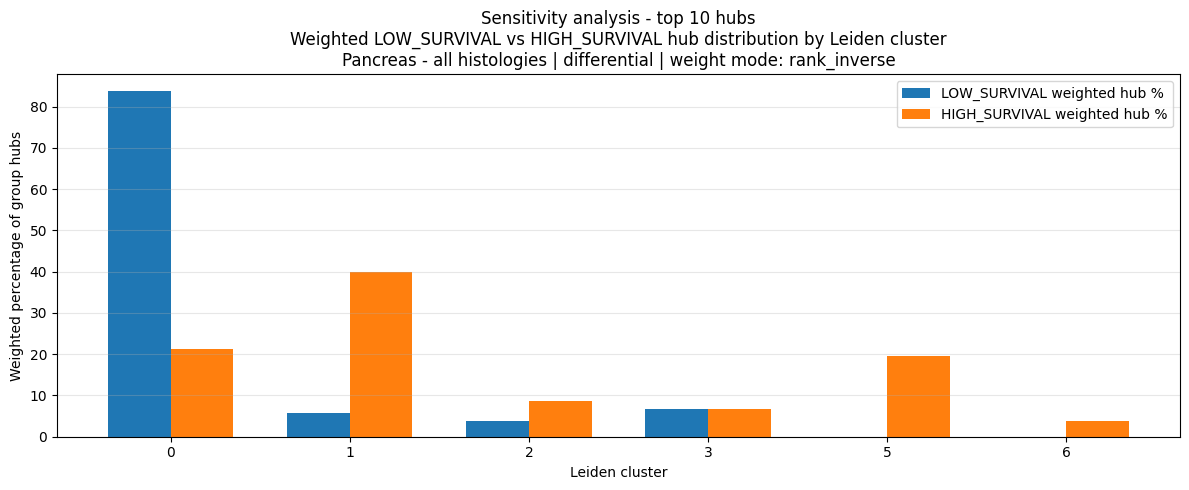

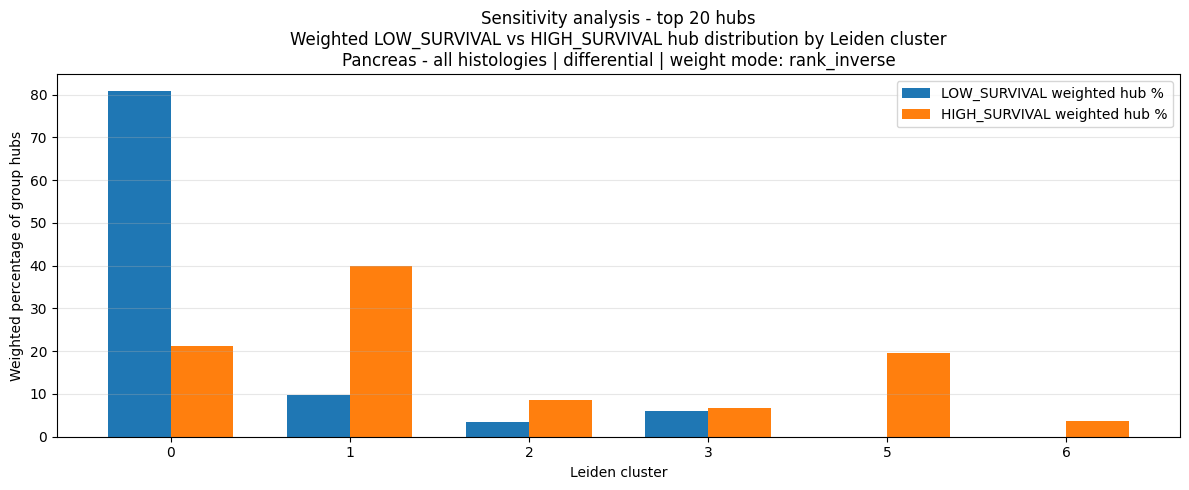

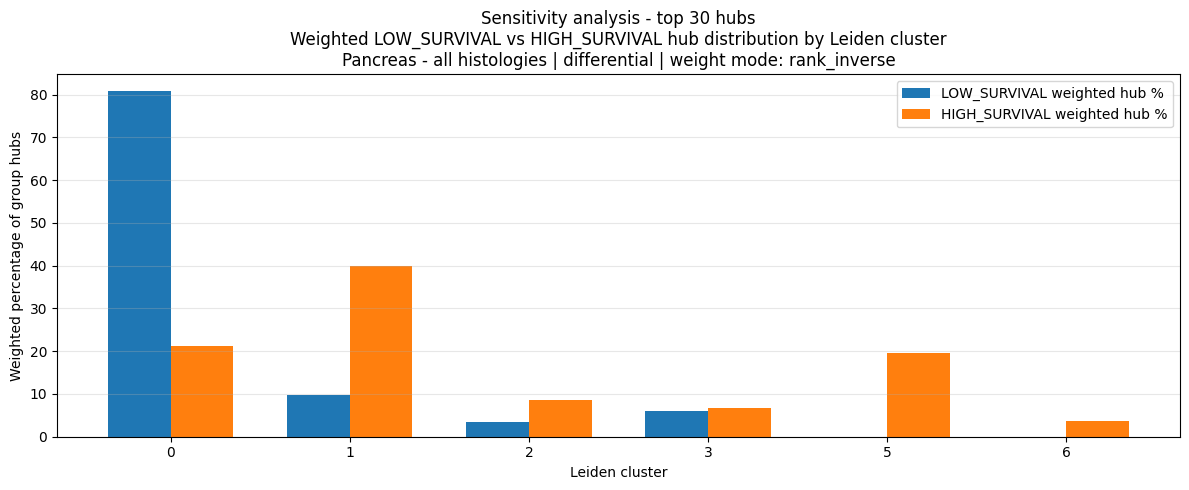

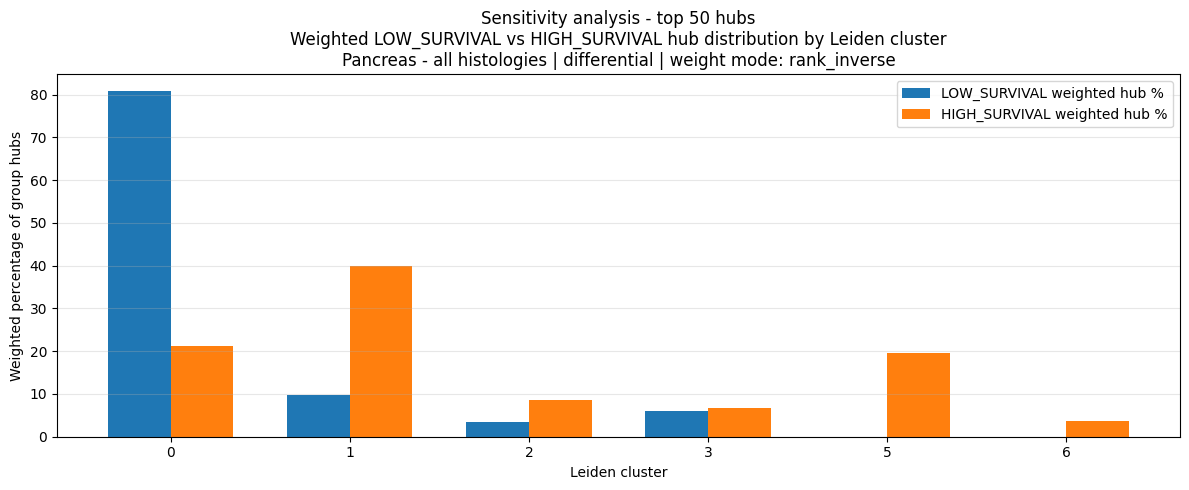

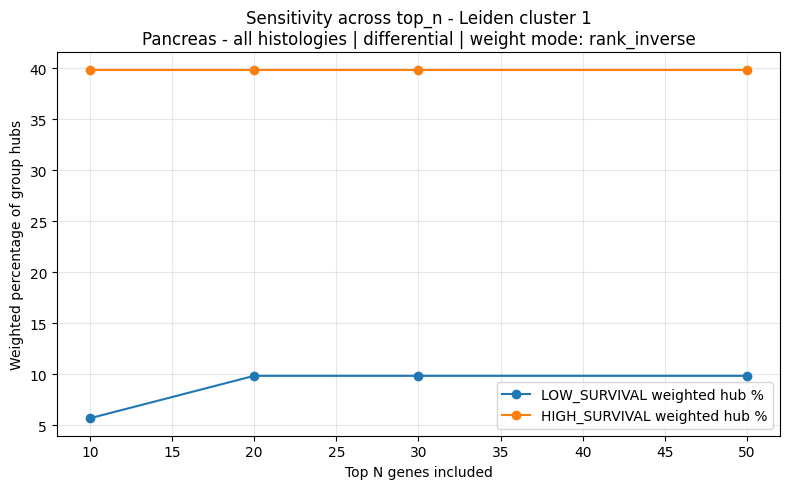

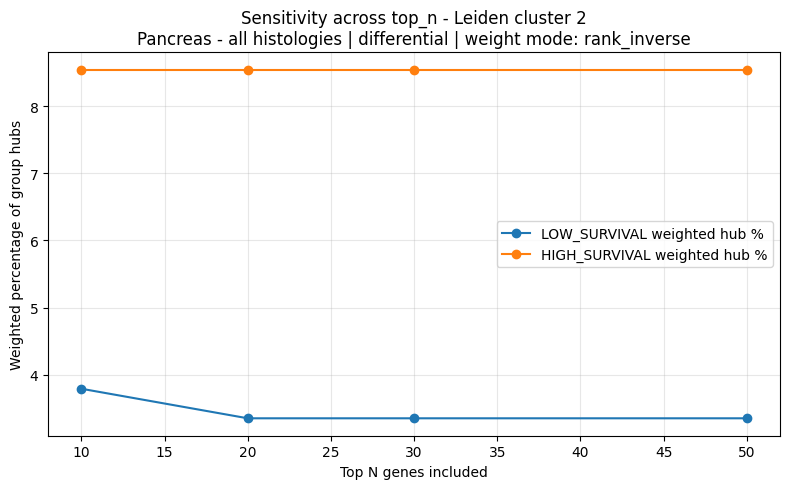


Saved sensitivity long table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\PANCREAS_ALL_differential_rank_inverse_survival_sensitivity_top_n_long.csv

Saved sensitivity wide table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\PANCREAS_ALL_differential_rank_inverse_survival_sensitivity_top_n_wide.csv

Saved sensitivity focus table for clusters 1 and 2:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\PANCREAS_ALL_differential_rank_inverse_survival_sensitivity_top_n_focus_clusters_1_2.csv

Saved dominant clusters table:
data_pancreas\clinical_to_network_median_pancreas_all\hub_genes_cluster_mapping\weighted_hub_distribution_by_cluster\sensitivity_analysis_top_n\PANCREAS_ALL_differential_rank_inverse

In [29]:
# ============================================================
# SENSITIVITY ANALYSIS
# Weighted hub distribution by Leiden cluster
# LOW_SURVIVAL vs HIGH_SURVIVAL
# PANCREAS_ALL
#
# Obiettivo:
# - confrontare la distribuzione pesata degli hub usando diversi top_n
# - capire se il segnale sui cluster è stabile
# - mantenere focus specifico sui cluster 1 e 2
#
# Da eseguire DOPO la cella:
# WEIGHTED HUB DISTRIBUTION BY LEIDEN CLUSTER - PANCREAS_ALL SURVIVAL
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 0. Settings
# ============================================================

TOP_N_VALUES = [10, 20, 30, 50]

# Mantengo lo stesso weight mode della cella precedente
SENSITIVITY_WEIGHT_MODE = WEIGHT_MODE

# Focus sui cluster 1 e 2
clusters_of_interest = [1, 2]

sensitivity_output_dir = (
        output_dir
        / "sensitivity_analysis_top_n"
)

sensitivity_output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Check input variables
# ============================================================

required_vars = [
    "mapped",
    "clusters",
    "PANCREAS_GROUP",
    "PANCREAS_LABEL",
    "LOW_LABEL",
    "HIGH_LABEL",
    "SURVIVAL_GROUPS",
    "ANALYSIS_MODE",
    "WEIGHT_MODE",
    "output_dir"
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    raise ValueError(
        f"Variabili mancanti: {missing_vars}. "
        "Esegui prima la cella della weighted hub distribution PANCREAS_ALL Survival."
    )


# ============================================================
# 2. Prepare base mapped table
# ============================================================

base_mapped = mapped.copy()
base_mapped = base_mapped.loc[:, ~base_mapped.columns.duplicated()].copy()

required_cols = {
    "Gene",
    "Cluster",
    "Hub_Group",
    "HubScore_for_weight"
}

missing_cols = required_cols - set(base_mapped.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti in mapped: {missing_cols}. "
        "Controlla che la cella precedente abbia creato Hub_Group e HubScore_for_weight."
    )

base_mapped["Gene"] = base_mapped["Gene"].astype(str)

base_mapped["Cluster"] = pd.to_numeric(
    base_mapped["Cluster"],
    errors="coerce"
)

base_mapped["HubScore_for_weight"] = pd.to_numeric(
    base_mapped["HubScore_for_weight"],
    errors="coerce"
)

base_mapped = base_mapped.dropna(
    subset=[
        "Gene",
        "Cluster",
        "Hub_Group",
        "HubScore_for_weight"
    ]
).copy()

base_mapped["Cluster"] = base_mapped["Cluster"].astype(int)

# Una riga per gene dentro ciascun gruppo
base_mapped = (
    base_mapped
    .sort_values(
        ["Hub_Group", "HubScore_for_weight"],
        ascending=[True, False]
    )
    .drop_duplicates(["Hub_Group", "Gene"], keep="first")
    .copy()
)

base_mapped["Full_rank_in_group"] = (
    base_mapped
    .groupby("Hub_Group")["HubScore_for_weight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

available_by_group = (
    base_mapped
    .groupby("Hub_Group")
    .agg(
        available_genes=("Gene", "nunique"),
        max_rank=("Full_rank_in_group", "max")
    )
    .reset_index()
)

print("\nAvailable mapped genes by group:")
try:
    display(available_by_group)
except NameError:
    print(available_by_group)

max_requested_top_n = max(TOP_N_VALUES)

if available_by_group["available_genes"].min() < max_requested_top_n:
    print(
        "\nATTENZIONE: almeno un gruppo ha meno geni disponibili del massimo top_n richiesto.\n"
        "Se il file mapped è stato generato con top_n=20, non puoi fare una vera sensitivity "
        "a top_n=30 o top_n=50 senza rigenerare prima il mapping con un top_n più alto."
    )


# ============================================================
# 3. Cluster sizes
# ============================================================

clusters_tmp = clusters.copy()
clusters_tmp = clusters_tmp.loc[:, ~clusters_tmp.columns.duplicated()].copy()

clusters_tmp["Cluster"] = pd.to_numeric(
    clusters_tmp["Cluster"],
    errors="coerce"
)

clusters_tmp["Gene"] = clusters_tmp["Gene"].astype(str)

cluster_sizes_sens = (
    clusters_tmp
    .dropna(subset=["Cluster"])
    .assign(Cluster=lambda x: x["Cluster"].astype(int))
    .groupby("Cluster")
    .agg(
        cluster_size_genes=("Gene", "nunique")
    )
    .reset_index()
)

all_clusters = sorted(
    cluster_sizes_sens["Cluster"]
    .dropna()
    .astype(int)
    .unique()
)


# ============================================================
# 4. Helper functions
# ============================================================

def assign_sensitivity_weight(row, weight_mode):
    rank = row["Hub_rank_in_selected_group"]
    n = row["n_hubs_in_selected_group"]
    hubscore = row["HubScore_for_weight"]

    if weight_mode == "hubscore":
        return hubscore

    if weight_mode == "rank_inverse":
        return 1 / rank

    if weight_mode == "rank_linear":
        if n <= 1:
            return 1
        return (n - rank + 1) / n

    raise ValueError("SENSITIVITY_WEIGHT_MODE non valido.")


def compute_weighted_distribution_for_top_n(top_n):
    """
    Calcola distribuzione pesata per uno specifico top_n.
    """

    selected = (
        base_mapped[
            base_mapped["Full_rank_in_group"] <= top_n
            ]
        .copy()
    )

    if selected.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    selected = selected.sort_values(
        ["Hub_Group", "HubScore_for_weight"],
        ascending=[True, False]
    ).copy()

    selected["Hub_rank_in_selected_group"] = (
        selected
        .groupby("Hub_Group")["HubScore_for_weight"]
        .rank(method="first", ascending=False)
        .astype(int)
    )

    selected["n_hubs_in_selected_group"] = (
        selected
        .groupby("Hub_Group")["Gene"]
        .transform("nunique")
    )

    selected["raw_weight"] = selected.apply(
        lambda row: assign_sensitivity_weight(
            row,
            SENSITIVITY_WEIGHT_MODE
        ),
        axis=1
    )

    selected["normalized_weight"] = (
            selected["raw_weight"]
            / selected.groupby("Hub_Group")["raw_weight"].transform("sum")
            * 100
    )

    selected["normalized_weight"] = selected["normalized_weight"].round(4)

    weighted_long_top = (
        selected
        .groupby(["Hub_Group", "Cluster"])
        .agg(
            n_hubs=("Gene", "nunique"),
            weighted_hub_score=("normalized_weight", "sum"),
            mean_hubscore=("HubScore_for_weight", "mean"),
            best_rank=("Hub_rank_in_selected_group", "min"),
            genes=("Gene", lambda x: ", ".join(sorted(x.dropna().astype(str).unique())))
        )
        .reset_index()
    )

    weighted_long_top["weighted_hub_score"] = (
        weighted_long_top["weighted_hub_score"]
        .round(2)
    )

    weighted_long_top["mean_hubscore"] = (
        weighted_long_top["mean_hubscore"]
        .round(4)
    )

    weighted_long_top = weighted_long_top.merge(
        cluster_sizes_sens,
        on="Cluster",
        how="left"
    )

    weighted_long_top["pct_cluster_covered_by_hubs"] = np.where(
        weighted_long_top["cluster_size_genes"] > 0,
        weighted_long_top["n_hubs"] / weighted_long_top["cluster_size_genes"] * 100,
        0
    ).round(2)

    weighted_long_top["top_n"] = top_n

    # Completo anche i cluster con 0 hub
    all_combinations = pd.MultiIndex.from_product(
        [SURVIVAL_GROUPS, all_clusters],
        names=["Hub_Group", "Cluster"]
    ).to_frame(index=False)

    complete = all_combinations.merge(
        weighted_long_top,
        on=["Hub_Group", "Cluster"],
        how="left"
    )

    complete = complete.merge(
        cluster_sizes_sens,
        on="Cluster",
        how="left",
        suffixes=("", "_from_clusters")
    )

    complete["cluster_size_genes"] = (
        complete["cluster_size_genes"]
        .fillna(complete["cluster_size_genes_from_clusters"])
    )

    complete = complete.drop(
        columns=["cluster_size_genes_from_clusters"],
        errors="ignore"
    )

    fill_zero_cols = [
        "n_hubs",
        "weighted_hub_score",
        "mean_hubscore",
        "pct_cluster_covered_by_hubs"
    ]

    for col in fill_zero_cols:
        complete[col] = complete[col].fillna(0)

    complete["best_rank"] = complete["best_rank"].fillna(np.nan)
    complete["genes"] = complete["genes"].fillna("-")
    complete["top_n"] = top_n

    # Wide table
    group_prefix = {
        LOW_LABEL: "Low_Survival",
        HIGH_LABEL: "High_Survival"
    }

    wide_parts = []

    for group in SURVIVAL_GROUPS:

        prefix = group_prefix[group]

        tmp = complete[
            complete["Hub_Group"] == group
            ][
            [
                "Cluster",
                "n_hubs",
                "weighted_hub_score",
                "mean_hubscore",
                "best_rank",
                "pct_cluster_covered_by_hubs",
                "genes"
            ]
        ].copy()

        tmp = tmp.rename(columns={
            "n_hubs": f"{prefix}_n_hubs",
            "weighted_hub_score": f"{prefix}_weighted_pct",
            "mean_hubscore": f"{prefix}_mean_hubscore",
            "best_rank": f"{prefix}_best_rank",
            "pct_cluster_covered_by_hubs": f"{prefix}_pct_cluster_covered",
            "genes": f"{prefix}_genes"
        })

        wide_parts.append(tmp)

    wide_top = cluster_sizes_sens.copy()

    for tmp in wide_parts:
        wide_top = wide_top.merge(
            tmp,
            on="Cluster",
            how="left"
        )

    wide_top = wide_top.fillna({
        "Low_Survival_n_hubs": 0,
        "Low_Survival_weighted_pct": 0,
        "Low_Survival_mean_hubscore": 0,
        "Low_Survival_pct_cluster_covered": 0,
        "Low_Survival_genes": "-",
        "High_Survival_n_hubs": 0,
        "High_Survival_weighted_pct": 0,
        "High_Survival_mean_hubscore": 0,
        "High_Survival_pct_cluster_covered": 0,
        "High_Survival_genes": "-"
    })

    wide_top["Low_Survival_n_hubs"] = (
        wide_top["Low_Survival_n_hubs"]
        .astype(int)
    )

    wide_top["High_Survival_n_hubs"] = (
        wide_top["High_Survival_n_hubs"]
        .astype(int)
    )

    wide_top["Delta_weighted_pct_Low_minus_High"] = (
            wide_top["Low_Survival_weighted_pct"]
            - wide_top["High_Survival_weighted_pct"]
    ).round(2)

    wide_top["Delta_n_hubs_Low_minus_High"] = (
            wide_top["Low_Survival_n_hubs"]
            - wide_top["High_Survival_n_hubs"]
    )

    wide_top["top_n"] = top_n

    selected_detail = selected[
        [
            "Hub_Group",
            "Gene",
            "Cluster",
            "HubScore_for_weight",
            "Full_rank_in_group",
            "Hub_rank_in_selected_group",
            "raw_weight",
            "normalized_weight"
        ]
    ].copy()

    selected_detail["top_n"] = top_n

    return weighted_long_top, wide_top, selected_detail


# ============================================================
# 5. Run sensitivity analysis
# ============================================================

sensitivity_long_tables = []
sensitivity_wide_tables = []
sensitivity_gene_detail_tables = []

for top_n in TOP_N_VALUES:

    weighted_long_top, wide_top, selected_detail = compute_weighted_distribution_for_top_n(
        top_n=top_n
    )

    if not weighted_long_top.empty:
        sensitivity_long_tables.append(weighted_long_top)

    if not wide_top.empty:
        sensitivity_wide_tables.append(wide_top)

    if not selected_detail.empty:
        sensitivity_gene_detail_tables.append(selected_detail)


sensitivity_long = pd.concat(
    sensitivity_long_tables,
    ignore_index=True
) if sensitivity_long_tables else pd.DataFrame()

sensitivity_wide = pd.concat(
    sensitivity_wide_tables,
    ignore_index=True
) if sensitivity_wide_tables else pd.DataFrame()

sensitivity_gene_detail = pd.concat(
    sensitivity_gene_detail_tables,
    ignore_index=True
) if sensitivity_gene_detail_tables else pd.DataFrame()


# ============================================================
# 6. Dominant clusters by top_n
# ============================================================

if not sensitivity_long.empty:

    dominant_clusters_by_top_n = (
        sensitivity_long
        .sort_values(
            ["top_n", "Hub_Group", "weighted_hub_score"],
            ascending=[True, True, False]
        )
        .groupby(["top_n", "Hub_Group"])
        .head(3)
        .reset_index(drop=True)
    )

    print("\n" + "=" * 120)
    print("TOP 3 DOMINANT CLUSTERS BY TOP_N AND GROUP")
    print("=" * 120)

    try:
        display(
            dominant_clusters_by_top_n[
                [
                    "top_n",
                    "Hub_Group",
                    "Cluster",
                    "n_hubs",
                    "weighted_hub_score",
                    "best_rank",
                    "genes"
                ]
            ]
        )
    except NameError:
        print(
            dominant_clusters_by_top_n[
                [
                    "top_n",
                    "Hub_Group",
                    "Cluster",
                    "n_hubs",
                    "weighted_hub_score",
                    "best_rank",
                    "genes"
                ]
            ]
        )

else:
    dominant_clusters_by_top_n = pd.DataFrame()
    print("No sensitivity results available.")


# ============================================================
# 7. Focus table on clusters 1 and 2
# ============================================================

if not sensitivity_wide.empty:

    sensitivity_focus = sensitivity_wide[
        sensitivity_wide["Cluster"].isin(clusters_of_interest)
    ].copy()

    print("\n" + "=" * 120)
    print(f"SENSITIVITY FOCUS ON CLUSTERS {clusters_of_interest}")
    print("=" * 120)

    display_cols = [
        "top_n",
        "Cluster",
        "cluster_size_genes",
        "Low_Survival_n_hubs",
        "Low_Survival_weighted_pct",
        "High_Survival_n_hubs",
        "High_Survival_weighted_pct",
        "Delta_weighted_pct_Low_minus_High",
        "Low_Survival_genes",
        "High_Survival_genes"
    ]

    try:
        display(sensitivity_focus[display_cols])
    except NameError:
        print(sensitivity_focus[display_cols])

else:
    sensitivity_focus = pd.DataFrame()


# ============================================================
# 8. Plot 1: weighted distribution for each top_n
# General plot over all clusters
# ============================================================

if not sensitivity_wide.empty:

    for top_n in TOP_N_VALUES:

        plot_df = sensitivity_wide[
            sensitivity_wide["top_n"] == top_n
            ][
            [
                "Cluster",
                "Low_Survival_weighted_pct",
                "High_Survival_weighted_pct"
            ]
        ].copy()

        if plot_df.empty:
            continue

        x = np.arange(len(plot_df))
        width = 0.35

        plt.figure(figsize=(12, 5))

        plt.bar(
            x - width / 2,
            plot_df["Low_Survival_weighted_pct"],
            width,
            label="LOW_SURVIVAL weighted hub %"
        )

        plt.bar(
            x + width / 2,
            plot_df["High_Survival_weighted_pct"],
            width,
            label="HIGH_SURVIVAL weighted hub %"
        )

        plt.xticks(x, plot_df["Cluster"])
        plt.xlabel("Leiden cluster")
        plt.ylabel("Weighted percentage of group hubs")
        plt.title(
            f"Sensitivity analysis - top {top_n} hubs\n"
            f"Weighted LOW_SURVIVAL vs HIGH_SURVIVAL hub distribution by Leiden cluster\n"
            f"{PANCREAS_LABEL} | {ANALYSIS_MODE} | weight mode: {SENSITIVITY_WEIGHT_MODE}"
        )
        plt.grid(axis="y", alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


# ============================================================
# 9. Plot 2: stability of clusters 1 and 2 across top_n
# ============================================================

if not sensitivity_wide.empty and not sensitivity_focus.empty:

    for cluster_id in clusters_of_interest:

        plot_cluster = sensitivity_wide[
            sensitivity_wide["Cluster"] == cluster_id
            ].sort_values("top_n").copy()

        if plot_cluster.empty:
            continue

        plt.figure(figsize=(8, 5))

        plt.plot(
            plot_cluster["top_n"],
            plot_cluster["Low_Survival_weighted_pct"],
            marker="o",
            label="LOW_SURVIVAL weighted hub %"
        )

        plt.plot(
            plot_cluster["top_n"],
            plot_cluster["High_Survival_weighted_pct"],
            marker="o",
            label="HIGH_SURVIVAL weighted hub %"
        )

        plt.xlabel("Top N genes included")
        plt.ylabel("Weighted percentage of group hubs")
        plt.title(
            f"Sensitivity across top_n - Leiden cluster {cluster_id}\n"
            f"{PANCREAS_LABEL} | {ANALYSIS_MODE} | weight mode: {SENSITIVITY_WEIGHT_MODE}"
        )
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()


# ============================================================
# 10. Save outputs
# ============================================================

sensitivity_long_output = (
        sensitivity_output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_survival_sensitivity_top_n_long.csv"
)

sensitivity_wide_output = (
        sensitivity_output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_survival_sensitivity_top_n_wide.csv"
)

sensitivity_focus_output = (
        sensitivity_output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_survival_sensitivity_top_n_focus_clusters_1_2.csv"
)

sensitivity_dominant_output = (
        sensitivity_output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_survival_sensitivity_top_n_dominant_clusters.csv"
)

sensitivity_gene_detail_output = (
        sensitivity_output_dir
        / f"{PANCREAS_GROUP}_{ANALYSIS_MODE}_{SENSITIVITY_WEIGHT_MODE}_survival_sensitivity_top_n_gene_detail.csv"
)

sensitivity_long.to_csv(sensitivity_long_output, index=False)
sensitivity_wide.to_csv(sensitivity_wide_output, index=False)
sensitivity_focus.to_csv(sensitivity_focus_output, index=False)
dominant_clusters_by_top_n.to_csv(sensitivity_dominant_output, index=False)
sensitivity_gene_detail.to_csv(sensitivity_gene_detail_output, index=False)

print("\nSaved sensitivity long table:")
print(sensitivity_long_output)

print("\nSaved sensitivity wide table:")
print(sensitivity_wide_output)

print("\nSaved sensitivity focus table for clusters 1 and 2:")
print(sensitivity_focus_output)

print("\nSaved dominant clusters table:")
print(sensitivity_dominant_output)

print("\nSaved sensitivity gene detail:")
print(sensitivity_gene_detail_output)


# ============================================================
# 11. Compatibility aliases
# ============================================================

sensitivity_long_pancreas_survival = sensitivity_long
sensitivity_wide_pancreas_survival = sensitivity_wide
sensitivity_focus_pancreas_survival = sensitivity_focus
sensitivity_dominant_clusters_pancreas_survival = dominant_clusters_by_top_n
sensitivity_gene_detail_pancreas_survival = sensitivity_gene_detail


# ============================================================
# 12. Interpretation helper
# ============================================================

print("\n" + "=" * 120)
print("INTERPRETATION GUIDE")
print("=" * 120)

print(
    "1. Se gli stessi cluster restano dominanti passando da top 10 a top 20, 30 e 50, "
    "il segnale è più robusto."
)

print(
    "2. Se un cluster è dominante solo con top 10 ma scompare con top 30/top 50, "
    "probabilmente il risultato dipende dai primissimi hub."
)

print(
    "3. Se un cluster aumenta usando top_n più grande, significa che il segnale non è limitato "
    "ai primissimi hub ma coinvolge anche hub meno estremi."
)

print(
    "4. Per il report puoi usare top 20 come analisi principale e questa sensitivity analysis "
    "come controllo di robustezza."
)

print(
    "5. In questa versione il focus specifico è sui cluster 1 e 2, mentre i bar chart generali "
    "mostrano comunque tutti i cluster."
)

print(
    "6. Il confronto è LOW_SURVIVAL vs HIGH_SURVIVAL su PANCREAS_ALL, "
    "senza separazione per istologia / Oncotree."
)

Loaded:
data_pancreas\CLINICAL_merged_mutations_cna_sv_with_median_survival_groups_PANCREAS_ALL.csv

Median OS_MONTHS - PANCREAS_ALL:
9.2383

Duplicate columns after cleaning:
[]

Rows: 6358
Patients: 886
Group: PANCREAS_ALL

Patients in PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,n_patients,n_events,median_OS_MONTHS,mean_OS_MONTHS
0,PANCREAS_ALL,Pancreas - all histologies,886,712,9.238346,13.60753



Survival group distribution in PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,survival_group,n_patients,n_events,median_OS_MONTHS,mean_OS_MONTHS,min_OS_MONTHS,max_OS_MONTHS
0,PANCREAS_ALL,Pancreas - all histologies,HIGH_SURVIVAL,444,319,17.819159,22.804936,9.238346,87.813602
1,PANCREAS_ALL,Pancreas - all histologies,LOW_SURVIVAL,442,393,4.076708,4.368507,0.032877,9.205469


Uso hub_comparison_pancreas_survival già presente in memoria.

GROUP: PANCREAS_ALL (Pancreas - all histologies)
Signature: PANCREAS_ALL_LOW_SURVIVAL_hub_signature
Genes: AKT2, BAP1, BRCA2, CDKN2Ap14ARF, CEBPA, EPHA5, ERBB3, KDM6A, PTPRD, YES1
Patients with signature mutation: 307
Patients without signature mutation: 579
Events with signature mutation: 252
Events without signature mutation: 460


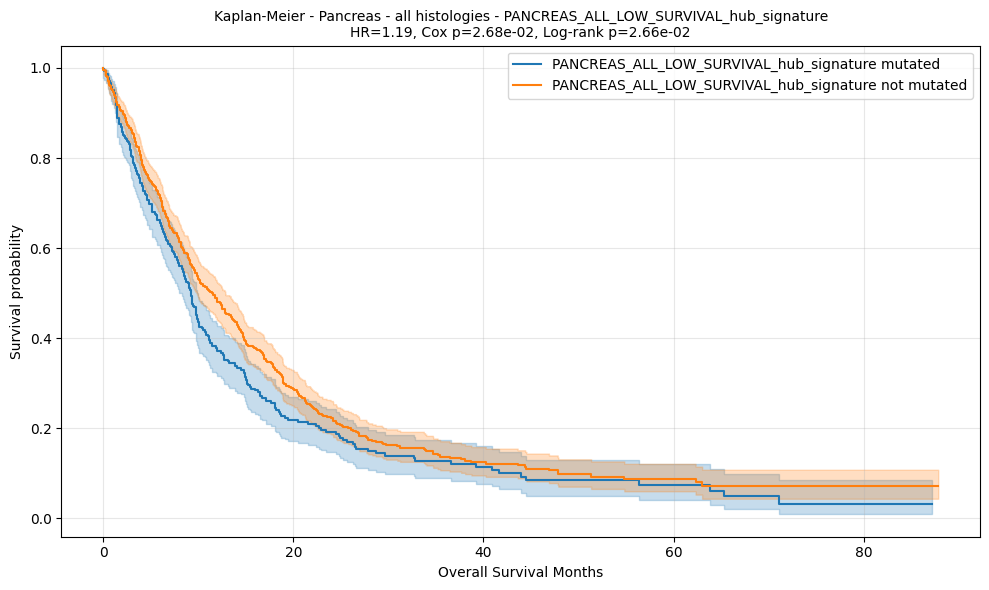

KM plot salvato in: data_pancreas\clinical_to_network_median_pancreas_all\km_hub_signatures_pancreas_all_survival\KM_PANCREAS_ALL_PANCREAS_ALL_LOW_SURVIVAL_hub_signature.png

GROUP: PANCREAS_ALL (Pancreas - all histologies)
Signature: PANCREAS_ALL_HIGH_SURVIVAL_hub_signature
Genes: CDK6, ELF3, FGF19, FGF3, FGF4, FGFR3, KMT2B, MYC, PREX2, RECQL4
Patients with signature mutation: 158
Patients without signature mutation: 728
Events with signature mutation: 128
Events without signature mutation: 584


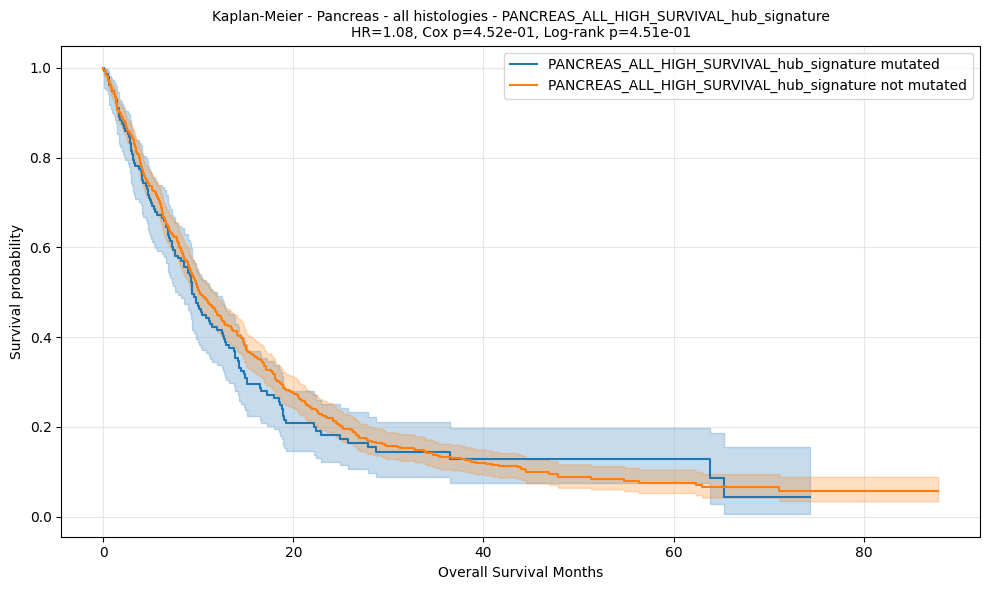

KM plot salvato in: data_pancreas\clinical_to_network_median_pancreas_all\km_hub_signatures_pancreas_all_survival\KM_PANCREAS_ALL_PANCREAS_ALL_HIGH_SURVIVAL_hub_signature.png

KM results - clinical to network survival-derived signatures - PANCREAS_ALL:


,ONCOTREE_CODE,Included_Oncotree_Codes,Signature,Num_genes,Genes,Patients_with_signature,Events_with_signature,Patients_without_signature,Events_without_signature,Logrank_p_value,Hazard_Ratio,Cox_p_value
0,PANCREAS_ALL,Pancreas - all histologies,PANCREAS_ALL_LOW_SURVIVAL_hub_signature,10,"AKT2, BAP1, BRCA2, CDKN2Ap14ARF, CEBPA, EPHA5, ERBB3, KDM6A, PTPRD, YES1",307,252,579,460,0.026647,1.189781,0.026816
1,PANCREAS_ALL,Pancreas - all histologies,PANCREAS_ALL_HIGH_SURVIVAL_hub_signature,10,"CDK6, ELF3, FGF19, FGF3, FGF4, FGFR3, KMT2B, MYC, PREX2, RECQL4",158,128,728,584,0.451438,1.076234,0.451891



KM results salvati in:
data_pancreas\clinical_to_network_median_pancreas_all\km_hub_signatures_pancreas_all_survival\km_results_clinical_to_network_survival_hub_signatures_PANCREAS_ALL.csv

Nota finale:
La Kaplan-Meier è stata eseguita su PANCREAS_ALL, usando le signature derivate dagli hub LOW_SURVIVAL e HIGH_SURVIVAL. Non viene fatta nessuna separazione per istologia / Oncotree.


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test


# ============================================================
# KM ANALYSIS - CLINICAL TO NETWORK
# PANCREAS_ALL
#
# Hub gene signatures:
# - LOW_SURVIVAL-hub signature
# - HIGH_SURVIVAL-hub signature
#
# Nota:
# - la stratificazione di rete viene da survival_group
# - la Kaplan-Meier usa comunque OS_MONTHS ed event
# - non viene fatta nessuna separazione per istologia / ONCOTREE_CODE
# ============================================================

data_dir = Path("data_pancreas")

PANCREAS_GROUP = "PANCREAS_ALL"
PANCREAS_LABEL = "Pancreas - all histologies"

LOW_LABEL = "LOW_SURVIVAL"
HIGH_LABEL = "HIGH_SURVIVAL"

merged_path = (
        data_dir
        / "CLINICAL_merged_mutations_cna_sv_with_median_survival_groups_PANCREAS_ALL.csv"
)

# File clinico originale usato solo come fallback se OS_MONTHS / event
# non sono presenti nel merged survival file.
clinical_fallback_path = data_dir / "filtered_data_PANCREAS.csv"

km_output_dir = (
        data_dir
        / "clinical_to_network_median_pancreas_all"
        / "km_hub_signatures_pancreas_all_survival"
)

km_output_dir.mkdir(parents=True, exist_ok=True)


# ============================================================
# Helpers against duplicate columns
# ============================================================

def collapse_duplicate_columns(df):
    """
    Se ci sono colonne duplicate, le collassa prendendo il primo valore non nullo.
    """
    df = df.copy()

    if not df.columns.duplicated().any():
        return df

    collapsed = pd.DataFrame(index=df.index)

    for col in pd.unique(df.columns):
        same_cols = df.loc[:, df.columns == col]

        if same_cols.shape[1] == 1:
            collapsed[col] = same_cols.iloc[:, 0]
        else:
            collapsed[col] = same_cols.bfill(axis=1).iloc[:, 0]

    return collapsed.copy()


def get_single_column(df, col):
    """
    Restituisce sempre una Series, anche se per errore ci sono colonne duplicate.
    """
    obj = df[col]

    if isinstance(obj, pd.DataFrame):
        return obj.iloc[:, 0]

    return obj


def safe_filename(text):
    text = str(text)
    text = text.replace("+", "_")
    text = text.replace("/", "_")
    text = text.replace(" ", "_")
    text = text.replace("(", "")
    text = text.replace(")", "")
    text = text.replace(",", "")
    text = text.replace("<", "lt")
    text = text.replace(">", "gt")
    text = text.replace("=", "eq")
    return text


def safe_display(df_obj):
    try:
        display(df_obj)
    except NameError:
        print(df_obj)


def assign_survival_group(value, median_value):
    """
    Stratifica i pazienti rispetto alla mediana di OS_MONTHS.

    LOW_SURVIVAL:
        OS_MONTHS < median_value

    HIGH_SURVIVAL:
        OS_MONTHS >= median_value
    """
    if pd.isna(value):
        return np.nan

    if value < median_value:
        return LOW_LABEL

    return HIGH_LABEL


def find_existing_file(candidate_paths, search_dir=None, patterns=None, description="file"):
    """
    Cerca un file:
    1. nei path candidati;
    2. con glob nella cartella indicata.
    """
    print(f"\nSearching for {description}...")

    for path in candidate_paths:
        print("Candidate:", path)
        if path.exists():
            print("Found:", path)
            return path

    if search_dir is not None and search_dir.exists() and patterns is not None:
        print(f"\nTrying automatic search in: {search_dir}")

        matches = []

        for pattern in patterns:
            matches.extend(sorted(search_dir.glob(pattern)))

        unique_matches = []
        seen = set()

        for path in matches:
            if path not in seen:
                unique_matches.append(path)
                seen.add(path)

        if len(unique_matches) > 0:
            print("Found by automatic search:")
            for path in unique_matches:
                print(path)

            return unique_matches[0]

    print(f"No {description} found.")
    return None


def load_hub_comparison_pancreas_survival():
    """
    Carica la tabella di confronto hub LOW_SURVIVAL vs HIGH_SURVIVAL per PANCREAS_ALL.
    Prima prova dalle variabili in memoria, poi dai CSV salvati.
    """

    possible_memory_vars = [
        "hub_comparison_pancreas_survival",
        "hub_comparison_all_pancreas_survival",
        "hub_comparison_all_oncotree_survival",
        "hub_comparison_all_oncotree_groups",
        "hub_comparison_all_oncotree"
    ]

    for var_name in possible_memory_vars:
        if var_name in globals():
            print(f"Uso {var_name} già presente in memoria.")
            return globals()[var_name].copy()

    hub_analysis_dir = (
            data_dir
            / "clinical_to_network_median_pancreas_all"
            / "hub_analysis_pancreas_all_median_survival"
    )

    candidate_paths = [
        hub_analysis_dir
        / "hub_genes_low_vs_high_survival_comparison_pancreas_all.csv",

        hub_analysis_dir
        / "hub_genes_PANCREAS_ALL_low_vs_high_survival_comparison.csv",

        hub_analysis_dir
        / "hub_genes_survival_comparison_pancreas_all.csv",
    ]

    patterns = [
        "*PANCREAS_ALL*low*high*survival*comparison*.csv",
        "*low*high*survival*comparison*pancreas*.csv",
        "*hub*survival*comparison*.csv",
    ]

    found_path = find_existing_file(
        candidate_paths=candidate_paths,
        search_dir=hub_analysis_dir,
        patterns=patterns,
        description="hub comparison LOW_SURVIVAL vs HIGH_SURVIVAL for PANCREAS_ALL"
    )

    if found_path is not None:
        print("\nCarico hub comparison da CSV:")
        print(found_path)
        return pd.read_csv(found_path, low_memory=False)

    raise FileNotFoundError(
        "Non trovo la tabella di confronto hub LOW_SURVIVAL vs HIGH_SURVIVAL.\n"
        "Esegui prima la cella di hub comparison per PANCREAS_ALL survival."
    )


# ============================================================
# Load merged dataset
# ============================================================

df_merge = pd.read_csv(merged_path, low_memory=False)
df_merge = collapse_duplicate_columns(df_merge)


# ------------------------------------------------------------
# Uniform column names safely
# ------------------------------------------------------------

if "PATIENT_ID" in df_merge.columns and "Patient_ID" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"PATIENT_ID": "Patient_ID"})

if "Oncotree Code" in df_merge.columns and "ONCOTREE_CODE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Oncotree Code": "ONCOTREE_CODE"})

if "Oncotree_Group" in df_merge.columns and "ONCOTREE_CODE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Oncotree_Group": "ONCOTREE_CODE"})

if "ONCOTREE_GROUP" in df_merge.columns and "ONCOTREE_CODE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"ONCOTREE_GROUP": "ONCOTREE_CODE"})

if "Oncotree Group" in df_merge.columns and "ONCOTREE_CODE" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Oncotree Group": "ONCOTREE_CODE"})

# Survival columns
if "Overall Survival (Months)" in df_merge.columns and "OS_MONTHS" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Overall Survival (Months)": "OS_MONTHS"})

if "Overall Survival Months" in df_merge.columns and "OS_MONTHS" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Overall Survival Months": "OS_MONTHS"})

if "OS_MONTH" in df_merge.columns and "OS_MONTHS" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"OS_MONTH": "OS_MONTHS"})

if "Overall Survival Status" in df_merge.columns and "OS_STATUS" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Overall Survival Status": "OS_STATUS"})

if "OS Status" in df_merge.columns and "OS_STATUS" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"OS Status": "OS_STATUS"})

if "SURVIVAL_GROUP" in df_merge.columns and "survival_group" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"SURVIVAL_GROUP": "survival_group"})

if "Survival_Group" in df_merge.columns and "survival_group" not in df_merge.columns:
    df_merge = df_merge.rename(columns={"Survival_Group": "survival_group"})

# Gene column
if "Hugo_Symbol" not in df_merge.columns and "Gene" in df_merge.columns:
    df_merge = df_merge.rename(columns={"Gene": "Hugo_Symbol"})
elif "Hugo_Symbol" in df_merge.columns and "Gene" in df_merge.columns:
    df_merge = df_merge.drop(columns=["Gene"])

df_merge = collapse_duplicate_columns(df_merge)


# ============================================================
# Force PANCREAS_ALL group
# ============================================================

df_merge["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge["Included_Oncotree_Codes"] = PANCREAS_LABEL


# ============================================================
# Fallback: add OS_MONTHS / OS_STATUS / event if missing
# ============================================================

needs_survival_fallback = (
        "OS_MONTHS" not in df_merge.columns
        or "event" not in df_merge.columns
)

if needs_survival_fallback:
    print(
        "OS_MONTHS/event non presenti nel merged survival file. "
        "Li recupero da filtered_data_PANCREAS.csv."
    )

    clinical_surv = pd.read_csv(clinical_fallback_path, low_memory=False)
    clinical_surv = collapse_duplicate_columns(clinical_surv)

    clinical_surv = clinical_surv.rename(columns={
        "PATIENT_ID": "Patient_ID",
        "Patient_ID": "Patient_ID",
        "Overall Survival (Months)": "OS_MONTHS",
        "Overall Survival Status": "OS_STATUS"
    })

    required_surv_cols = {
        "Patient_ID",
        "OS_MONTHS",
        "OS_STATUS"
    }

    missing_surv_cols = required_surv_cols - set(clinical_surv.columns)

    if missing_surv_cols:
        raise ValueError(
            f"Colonne mancanti nel file clinico fallback per survival: {missing_surv_cols}"
        )

    clinical_surv["Patient_ID"] = clinical_surv["Patient_ID"].astype(str).str.strip()

    clinical_surv["OS_MONTHS"] = pd.to_numeric(
        clinical_surv["OS_MONTHS"],
        errors="coerce"
    )

    clinical_surv["OS_STATUS"] = clinical_surv["OS_STATUS"].astype(str)

    clinical_surv["event"] = (
        clinical_surv["OS_STATUS"]
        .str.contains("DECEASED", case=False, na=False)
        .astype(int)
    )

    clinical_surv = (
        clinical_surv[
            [
                "Patient_ID",
                "OS_MONTHS",
                "OS_STATUS",
                "event"
            ]
        ]
        .dropna(subset=["Patient_ID", "OS_MONTHS", "event"])
        .drop_duplicates("Patient_ID")
        .copy()
    )

    cols_to_remove_before_surv_merge = [
        col for col in ["OS_MONTHS", "OS_STATUS", "event"]
        if col in df_merge.columns
    ]

    df_merge = df_merge.drop(
        columns=cols_to_remove_before_surv_merge
    ).copy()

    df_merge["Patient_ID"] = df_merge["Patient_ID"].astype(str).str.strip()

    df_merge = df_merge.merge(
        clinical_surv,
        on="Patient_ID",
        how="left"
    )

    df_merge = collapse_duplicate_columns(df_merge)


# ============================================================
# Create survival_group if missing
# ============================================================

df_merge["OS_MONTHS"] = pd.to_numeric(
    get_single_column(df_merge, "OS_MONTHS"),
    errors="coerce"
)

if "OS_STATUS" not in df_merge.columns:
    df_merge["OS_STATUS"] = np.nan

if "event" not in df_merge.columns:
    df_merge["event"] = (
        df_merge["OS_STATUS"]
        .astype(str)
        .str.contains("DECEASED", case=False, na=False)
        .astype(int)
    )

df_merge["event"] = pd.to_numeric(
    get_single_column(df_merge, "event"),
    errors="coerce"
)

if "survival_group" not in df_merge.columns:
    patient_level_survival = (
        df_merge[
            [
                "Patient_ID",
                "OS_MONTHS"
            ]
        ]
        .dropna(subset=["Patient_ID", "OS_MONTHS"])
        .drop_duplicates("Patient_ID")
        .copy()
    )

    survival_median = patient_level_survival["OS_MONTHS"].median()

    df_merge["survival_group"] = df_merge["OS_MONTHS"].apply(
        lambda x: assign_survival_group(x, survival_median)
    )

else:
    if "survival_threshold_median_pancreas_all" in df_merge.columns:
        survival_median = (
            pd.to_numeric(
                df_merge["survival_threshold_median_pancreas_all"],
                errors="coerce"
            )
            .dropna()
            .iloc[0]
        )
    else:
        patient_level_survival = (
            df_merge[
                [
                    "Patient_ID",
                    "OS_MONTHS"
                ]
            ]
            .dropna(subset=["Patient_ID", "OS_MONTHS"])
            .drop_duplicates("Patient_ID")
            .copy()
        )

        survival_median = patient_level_survival["OS_MONTHS"].median()

df_merge["median_group"] = df_merge["survival_group"]
df_merge["survival_threshold_median_pancreas_all"] = survival_median


# ============================================================
# Check required columns
# ============================================================

required_cols = {
    "Patient_ID",
    "Hugo_Symbol",
    "ONCOTREE_CODE",
    "survival_group",
    "OS_MONTHS",
    "event"
}

missing_cols = required_cols - set(df_merge.columns)

if missing_cols:
    raise ValueError(
        f"Colonne mancanti nel merged file per PANCREAS_ALL + survival: {missing_cols}. "
        "Controlla che survival_group, OS_MONTHS ed event siano disponibili."
    )


# ============================================================
# Type conversion and cleaning
# ============================================================

df_merge["Patient_ID"] = get_single_column(df_merge, "Patient_ID").astype(str).str.strip()
df_merge["Hugo_Symbol"] = get_single_column(df_merge, "Hugo_Symbol").astype(str).str.strip()
df_merge["ONCOTREE_CODE"] = PANCREAS_GROUP
df_merge["Included_Oncotree_Codes"] = PANCREAS_LABEL
df_merge["survival_group"] = get_single_column(df_merge, "survival_group").astype(str)

df_merge["OS_MONTHS"] = pd.to_numeric(
    get_single_column(df_merge, "OS_MONTHS"),
    errors="coerce"
)

df_merge["event"] = pd.to_numeric(
    get_single_column(df_merge, "event"),
    errors="coerce"
)

df_merge = df_merge.dropna(
    subset=[
        "Patient_ID",
        "Hugo_Symbol",
        "ONCOTREE_CODE",
        "survival_group",
        "OS_MONTHS",
        "event"
    ]
).copy()

df_merge["event"] = df_merge["event"].astype(int)

print("Loaded:")
print(merged_path)

print("\nMedian OS_MONTHS - PANCREAS_ALL:")
print(round(survival_median, 4))

print("\nDuplicate columns after cleaning:")
print(df_merge.columns[df_merge.columns.duplicated()].tolist())

print("\nRows:", df_merge.shape[0])
print("Patients:", df_merge["Patient_ID"].nunique())
print("Group:", PANCREAS_GROUP)

print("\nPatients in PANCREAS_ALL:")

safe_display(
    df_merge
    .drop_duplicates(["Patient_ID"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_events=("event", "sum"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        mean_OS_MONTHS=("OS_MONTHS", "mean")
    )
    .reset_index()
)

print("\nSurvival group distribution in PANCREAS_ALL:")

safe_display(
    df_merge
    .drop_duplicates(["Patient_ID"])
    .groupby(["ONCOTREE_CODE", "Included_Oncotree_Codes", "survival_group"])
    .agg(
        n_patients=("Patient_ID", "nunique"),
        n_events=("event", "sum"),
        median_OS_MONTHS=("OS_MONTHS", "median"),
        mean_OS_MONTHS=("OS_MONTHS", "mean"),
        min_OS_MONTHS=("OS_MONTHS", "min"),
        max_OS_MONTHS=("OS_MONTHS", "max")
    )
    .reset_index()
    .sort_values(["ONCOTREE_CODE", "survival_group"])
)


# ============================================================
# PARAMETERS
# ============================================================

top_n_genes = 10
min_patients_per_group = 10
min_events_per_group = 5

km_results = []


# ============================================================
# KM helper
# ============================================================

def run_km_for_gene_signature(
        df_group,
        gene_signature,
        signature_name
):
    """
    Confronta:
    - pazienti con almeno una mutazione nei geni della signature
    - pazienti senza mutazioni nei geni della signature

    Le signature derivano dai geni hub LOW_SURVIVAL / HIGH_SURVIVAL,
    ma l'endpoint testato resta la sopravvivenza globale.
    """

    df_group = collapse_duplicate_columns(df_group)

    gene_signature = set([
        str(g)
        for g in gene_signature
        if pd.notna(g)
    ])

    if len(gene_signature) == 0:
        print(f"[{signature_name}] No genes in signature.")
        return None

    clinical = (
        df_group[
            [
                "Patient_ID",
                "OS_MONTHS",
                "event"
            ]
        ]
        .drop_duplicates("Patient_ID")
        .copy()
    )

    gene_series = get_single_column(df_group, "Hugo_Symbol").astype(str)

    mask_signature = gene_series.isin(gene_signature)

    patients_with_signature = (
        df_group.loc[mask_signature, "Patient_ID"]
        .dropna()
        .astype(str)
        .unique()
    )

    clinical["has_signature"] = (
        clinical["Patient_ID"]
        .astype(str)
        .isin(patients_with_signature)
        .astype(int)
    )

    n_mut = int(clinical["has_signature"].sum())
    n_wt = int((clinical["has_signature"] == 0).sum())

    events_mut = int(
        clinical.loc[
            clinical["has_signature"] == 1,
            "event"
        ].sum()
    )

    events_wt = int(
        clinical.loc[
            clinical["has_signature"] == 0,
            "event"
        ].sum()
    )

    print("\n" + "=" * 90)
    print(f"GROUP: {PANCREAS_GROUP} ({PANCREAS_LABEL})")
    print(f"Signature: {signature_name}")
    print(f"Genes: {', '.join(sorted(gene_signature))}")
    print(f"Patients with signature mutation: {n_mut}")
    print(f"Patients without signature mutation: {n_wt}")
    print(f"Events with signature mutation: {events_mut}")
    print(f"Events without signature mutation: {events_wt}")

    if (
            n_mut < min_patients_per_group
            or n_wt < min_patients_per_group
            or events_mut < min_events_per_group
            or events_wt < min_events_per_group
    ):
        print("Skipped: too few patients or events.")
        return None

    group_mut = clinical[clinical["has_signature"] == 1]
    group_wt = clinical[clinical["has_signature"] == 0]

    lr = logrank_test(
        group_mut["OS_MONTHS"],
        group_wt["OS_MONTHS"],
        event_observed_A=group_mut["event"],
        event_observed_B=group_wt["event"]
    )

    cox_df = clinical[
        [
            "OS_MONTHS",
            "event",
            "has_signature"
        ]
    ].copy()

    cph = CoxPHFitter()

    try:
        cph.fit(
            cox_df,
            duration_col="OS_MONTHS",
            event_col="event"
        )

        hr = np.exp(cph.params_["has_signature"])
        p_cox = cph.summary.loc["has_signature", "p"]

    except Exception as e:
        print(f"Cox model failed for {signature_name}: {e}")
        hr = np.nan
        p_cox = np.nan

    kmf = KaplanMeierFitter()

    plt.figure(figsize=(10, 6))

    kmf.fit(
        group_mut["OS_MONTHS"],
        event_observed=group_mut["event"],
        label=f"{signature_name} mutated"
    )
    kmf.plot_survival_function()

    kmf.fit(
        group_wt["OS_MONTHS"],
        event_observed=group_wt["event"],
        label=f"{signature_name} not mutated"
    )
    kmf.plot_survival_function()

    plt.title(
        f"Kaplan-Meier - {PANCREAS_LABEL} - {signature_name}\n"
        f"HR={hr:.2f}, Cox p={p_cox:.2e}, Log-rank p={lr.p_value:.2e}",
        fontsize=10
    )

    plt.xlabel("Overall Survival Months")
    plt.ylabel("Survival probability")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    fig_path = (
            km_output_dir
            / f"KM_{safe_filename(PANCREAS_GROUP)}_{safe_filename(signature_name)}.png"
    )

    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"KM plot salvato in: {fig_path}")

    return {
        "ONCOTREE_CODE": PANCREAS_GROUP,
        "Included_Oncotree_Codes": PANCREAS_LABEL,
        "Signature": signature_name,
        "Num_genes": len(gene_signature),
        "Genes": ", ".join(sorted(gene_signature)),
        "Patients_with_signature": n_mut,
        "Events_with_signature": events_mut,
        "Patients_without_signature": n_wt,
        "Events_without_signature": events_wt,
        "Logrank_p_value": lr.p_value,
        "Hazard_Ratio": hr,
        "Cox_p_value": p_cox
    }


# ============================================================
# Load hub comparison table
# ============================================================

hub_comparison_pancreas_survival = load_hub_comparison_pancreas_survival()
hub_comparison_pancreas_survival = collapse_duplicate_columns(hub_comparison_pancreas_survival)

# Compatibilità:
# se la tabella ha Oncotree_Group, la rinomino in ONCOTREE_CODE.
if "ONCOTREE_CODE" not in hub_comparison_pancreas_survival.columns:
    if "Oncotree_Group" in hub_comparison_pancreas_survival.columns:
        hub_comparison_pancreas_survival = hub_comparison_pancreas_survival.rename(
            columns={"Oncotree_Group": "ONCOTREE_CODE"}
        )
    else:
        hub_comparison_pancreas_survival["ONCOTREE_CODE"] = PANCREAS_GROUP

hub_comparison_pancreas_survival["ONCOTREE_CODE"] = PANCREAS_GROUP

delta_col = "Delta_HubScore_low_minus_high"

required_hub_cols = {
    "ONCOTREE_CODE",
    "Gene",
    delta_col
}

missing_hub_cols = required_hub_cols - set(hub_comparison_pancreas_survival.columns)

if missing_hub_cols:
    raise ValueError(
        f"Colonne mancanti in hub_comparison_pancreas_survival: {missing_hub_cols}"
    )

hub_comparison_pancreas_survival["Gene"] = (
    hub_comparison_pancreas_survival["Gene"]
    .astype(str)
)

hub_comparison_pancreas_survival[delta_col] = pd.to_numeric(
    hub_comparison_pancreas_survival[delta_col],
    errors="coerce"
)

hub_comparison_pancreas_survival = hub_comparison_pancreas_survival.dropna(
    subset=["Gene", delta_col]
).copy()

if hub_comparison_pancreas_survival.empty:
    raise ValueError(
        "La tabella hub_comparison_pancreas_survival è vuota dopo il preprocessing."
    )


# ============================================================
# Build LOW_SURVIVAL and HIGH_SURVIVAL hub signatures
# ============================================================

low_survival_signature_genes = (
    hub_comparison_pancreas_survival
    .sort_values(delta_col, ascending=False)
    .head(top_n_genes)["Gene"]
    .dropna()
    .astype(str)
    .tolist()
)

high_survival_signature_genes = (
    hub_comparison_pancreas_survival
    .sort_values(delta_col, ascending=True)
    .head(top_n_genes)["Gene"]
    .dropna()
    .astype(str)
    .tolist()
)


# ============================================================
# RUN KM FOR PANCREAS_ALL
# ============================================================

res_low_survival = run_km_for_gene_signature(
    df_group=df_merge,
    gene_signature=low_survival_signature_genes,
    signature_name=f"{PANCREAS_GROUP}_LOW_SURVIVAL_hub_signature"
)

if res_low_survival is not None:
    km_results.append(res_low_survival)

res_high_survival = run_km_for_gene_signature(
    df_group=df_merge,
    gene_signature=high_survival_signature_genes,
    signature_name=f"{PANCREAS_GROUP}_HIGH_SURVIVAL_hub_signature"
)

if res_high_survival is not None:
    km_results.append(res_high_survival)


# ============================================================
# FINAL TABLE
# ============================================================

km_results_clinical_to_network_pancreas_survival = pd.DataFrame(km_results)

if not km_results_clinical_to_network_pancreas_survival.empty:
    km_results_clinical_to_network_pancreas_survival = (
        km_results_clinical_to_network_pancreas_survival
        .sort_values(["Logrank_p_value"])
        .reset_index(drop=True)
    )

    output_file = (
            km_output_dir
            / "km_results_clinical_to_network_survival_hub_signatures_PANCREAS_ALL.csv"
    )

    km_results_clinical_to_network_pancreas_survival.to_csv(
        output_file,
        index=False
    )

    print("\nKM results - clinical to network survival-derived signatures - PANCREAS_ALL:")

    safe_display(km_results_clinical_to_network_pancreas_survival)

    print("\nKM results salvati in:")
    print(output_file)

else:
    print("\nNo KM result passed the minimum patient/event thresholds.")


# ============================================================
# OPTIONAL COMPATIBILITY ALIASES
# ============================================================

km_results_clinical_to_network = km_results_clinical_to_network_pancreas_survival
km_results_clinical_to_network_pancreas_all = km_results_clinical_to_network_pancreas_survival
km_results_clinical_to_network_pancreas_all_survival = km_results_clinical_to_network_pancreas_survival

print("\nNota finale:")
print(
    "La Kaplan-Meier è stata eseguita su PANCREAS_ALL, usando le signature "
    "derivate dagli hub LOW_SURVIVAL e HIGH_SURVIVAL. "
    "Non viene fatta nessuna separazione per istologia / Oncotree."
)